# PCLab - Hackathon - Group 7 - Cecilia Lo Cicero, Sara Pulidori, Alissa Sharuda,  Nico Visentin  

**Course:** 20598 – Finance with Big Data (Bocconi University)
**Instructor:** Clément Mazet-Sonilhac

**Group:** 7

**Time to complete:** 30 Hours **Difficulty:** 7 out of 10

# Introduction

This project examines bank-related activist campaigns through their sentiment, event characteristics, media coverage, and associated market outcomes. It first describes campaign and event patterns, then explores media echo and stock-return measures across campaign groups and political contexts. Considered together, these analyses offer a comparative view of how campaigns are represented and how their coverage and financial outcomes vary. Some underlying records contain sensitive information or are not authorized for disclosure, so those materials cannot be shared. The discussion is therefore grounded in the data and outputs available for review, with care taken to distinguish the different samples and measures used.

To track the work we split the tasks in 4 sections:
- A: Day1, Day 2, task 1 and task 3
- B: task 4
- C: task 5
- D: task 6 and task 7

# 0: set the environment

In [ ]:
import zipfile, io
import pandas as pd
import numpy as np
from pathlib import Path
import sys
import re
import html
import statsmodels.formula.api as smf
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter
import matplotlib.dates as mdates
#! pip install vaderSentiment
from vaderSentiment.vaderSentiment import SentimentIntensityAnalyzer
# pip install transformers torch   (the first run downloads about 440 MB)
import torch
from transformers import AutoTokenizer, AutoModelForSequenceClassification
from scipy.stats import spearmanr, mannwhitneyu
import matplotlib.pyplot as plt
import time
import requests
from urllib.parse import urlparse
from concurrent.futures import ThreadPoolExecutor, as_completed
from textwrap import shorten
from matplotlib.patches import Patch
from matplotlib.ticker import MaxNLocator
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from matplotlib.lines import Line2D
from matplotlib.ticker import PercentFormatter
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from matplotlib.lines import Line2D
from matplotlib.ticker import PercentFormatter
from matplotlib.ticker import PercentFormatter, MaxNLocator
import io, zipfile, urllib.request

In [ ]:
DATA = Path('data') if Path('data').exists() else Path(".")   # data/ folder if there is one, otherwise the project folder
OUT = DATA / "handoff"                                        # files passed between A, B, C and D
OUT.mkdir(exist_ok=True)

if not (DATA / "sigwatch_data").exists():
    for z in ["ngo_data_bocconi.zip", "banks_data_bocconi.zip"]:
        zipfile.ZipFile(DATA / z).extractall(DATA)

---
# Part A: NGO data
Load and append the Sigwatch years, filter to US/UK/EU banks, describe the campaigns, and build the name→ISIN lookup.

**Handoff to C and D:** `handoff/events_banks.csv`, `handoff/campaigns_banks.csv`, `handoff/lookup_banks.csv`.

## A1. Load and append the Sigwatch years

In [4]:
# Sigwatch
files = sorted((DATA / "sigwatch_data").glob("*.dta"))

sig = pd.concat(
    [pd.read_stata(f).assign(year_file=int(f.name[:4])) for f in files],
    ignore_index=True,
)
print(sig.shape)

(73094, 95)


In [5]:
#Datastream
ri_sheets = pd.read_excel(DATA / "banks_data_bocconi" / "banks_ri.xlsm", sheet_name=None)
ri_sheets.pop("REQUEST_TABLE")

print(ri_sheets.keys())
print(ri_sheets["US"].shape)

dict_keys(['BD', 'BG', 'CP', 'EO', 'ES', 'FN', 'FR', 'GR', 'IR', 'IT', 'LN', 'MA', 'NL', 'OE', 'PT', 'SJ', 'SX', 'US', 'UK'])
(3216, 60)


In [6]:
longs = []

for k, v in ri_sheets.items():
    long = v.melt(id_vars="Name", var_name="bank", value_name="ri")
    long = long.rename(columns={"Name": "date"})
    long["country"] = k
    longs.append(long)

ri = pd.concat(longs, ignore_index=True)

In [7]:
print(ri.shape)
print(ri["country"].value_counts())
print(ri["bank"].nunique())

(508128, 4)
country
US    189744
IT     45024
UK     41808
FR     38592
ES     25728
BD     25728
NL     22512
OE     22512
GR     19296
SX     19296
MA     12864
IR      9648
BG      9648
CP      6432
FN      6432
LN      3216
EO      3216
PT      3216
SJ      3216
Name: count, dtype: int64
158


In [8]:
print(f"{sig['uid_archive'].nunique():,} events, {len(sig):,} rows")
print(f"{sig['company'].nunique():,} companies in total") #nbr of unique company_name -> Number of companies
print(f"Average : {len(sig) / sig['uid_archive'].nunique():.1f} companies per event")

23,151 events, 73,094 rows
15,616 companies in total
Average : 3.2 companies per event


**Largest event:**

In [9]:
top_uid = sig["uid_archive"].value_counts().index[0]
top = sig[sig["uid_archive"] == top_uid]
print(f"Largest event: {len(top)} firms named by {top['ngo_name1'].iloc[0]} on {top['date'].iloc[0]}")

Largest event: 72 firms named by ActionAid UK on 2013-05-13


Largest event. The event with the most targets is a single communication by ActionAid UK on 13 May 2013, naming 72 companies at once (BP, Shell, Tesco, AstraZeneca, …).

This matters for the event study: an NGO communication that names dozens of firms is unlikely to be firm-specific news, and any common price move that day would be absorbed by the market factor. We therefore compute n_targets (number of firms named in the same event) and will either drop or analyse separately the mass events above a threshold.

In [10]:
counts = sig["uid_archive"].value_counts()          #number of firms per event
sig["n_targets"] = sig["uid_archive"].map(counts)   #attach it to every (event, firm) row

In [11]:
events = sig.drop_duplicates("uid_archive")

print("n_targets, per (event, firm) row:")
print(sig["n_targets"].describe().round(2))

print("\nn_targets, per event:")
print(events["n_targets"].describe().round(2))

share_single = (events["n_targets"] == 1).mean()
print(f"\n{share_single:.1%} of events target a single company")

n_targets, per (event, firm) row:
count    73094.00
mean         8.33
std          8.74
min          1.00
25%          2.00
50%          5.00
75%         11.00
max         72.00
Name: n_targets, dtype: float64

n_targets, per event:
count    23151.00
mean         3.16
std          4.04
min          1.00
25%          1.00
50%          2.00
75%          3.00
max         72.00
Name: n_targets, dtype: float64

45.3% of events target a single company


## A2. Clean Sigwatch and filter to US/UK/EU banks

In [12]:
#Basic cleaning
sig["date"] = pd.to_datetime(sig["date"])                                    # dates are stored as text
for c in ["isin_1", "isin_2", "isin_3"]:
    sig[c] = sig[c].replace("", np.nan)                                      # empty strings -> missing
sig["parent_country"] = sig["company_parent_country"].replace({"USA": "US"}) # same country, two spellings

In [13]:
# Names of the banks we have prices for (Datastream, incl. Swiss/Nordic file)

# Read the column headers of every country sheet and strip the " - TOT RETURN IND" suffix to get the bank name
def ds_names(file):
    sheets = pd.read_excel(DATA / "banks_data_bocconi" / file, sheet_name=None, nrows=1)
    sheets.pop("REQUEST_TABLE")
    return {c.rsplit(" - ", 1)[0].strip().lower() for v in sheets.values() for c in v.columns if c != "Name"}

# Combine the main file and the Swiss/Nordic file into one set of priced bank names
ds = ds_names("banks_ri.xlsm") | ds_names("scandinavian_banks_ri.xlsm")

In [14]:
# Sigwatch name -> Datastream name, parsed from the Stata file
mp = {}
for line in open(DATA / "example_name_cleaning.txt", encoding="utf-8", errors="ignore"):
    if line.strip().startswith("replace company"):
        q = re.findall(r'"([^"]*)"', line)                      # [target, source1, source2, ...]
        mp.update({s.strip().lower(): q[0].strip().lower() for s in q[1:]})

# remove wrong mappings from the Stata file (e.g. Berkshire Hathaway -> a Swiss cantonal bank)
for k in ["berkshire hathaway", "pinnacle west capital corporation", "virgin group",
          "lloyd's of london", "ace group", "gruppo assicurazioni generali"]:
    mp.pop(k, None)

# Banco Popular Espanol has no price series: Datastream's "POPULAR" is Popular Inc. of Puerto Rico, a different bank
mp = {k: v for k, v in mp.items() if v != "popular"}

# fix targets that don't exist in Datastream + add banks the Stata file missed
mp.update({
    "bankinter, s.a.": "bankinter 'r'", "allianz se": "allianz", "allianz group / allianz se": "allianz",
    "jp morgan chase": "jp morgan chase & co.", "goldman sachs group, inc.": "goldman sachs gp.",
    "skandinaviska enskilda banken ab (seb)": "skandinaviska enskilda banken a",
    "handelsbanken": "svenska handelsbanken a", "dnb nor": "dnb", "u.s. bank": "us bancorp", "la caixa": "caixabank",
})

In [15]:
# Match on the company, else on its parent (so subsidiaries like Halifax -> Lloyds are kept)
for c in ["company", "company_parent"]:
    s = sig[c].str.strip().str.lower()
    sig[c + "_ds"] = s.map(mp).fillna(s)
sig["ds_name"] = sig["company_ds"].where(sig["company_ds"].isin(ds),
                                         sig["company_parent_ds"].where(sig["company_parent_ds"].isin(ds)))

# Saga Group's Datastream index never changes (no price data), so its events cannot be studied
NO_PRICES = {"saga group"}
matched = sig[sig["ds_name"].notna() & ~sig["ds_name"].isin(NO_PRICES)].copy()

# Datastream's bank lists also contain insurers, an investment trust and a card network: these are not banks
NON_BANKS = {"allianz", "aegon", "asr nederland", "admiral group", "aflac", "alliance trust", "mastercard"}

# Project scope: US, UK and EU banks, so Swiss and Norwegian banks are out
EU = {"Austria", "Belgium", "Bulgaria", "Croatia", "Cyprus", "Czech Republic", "Denmark", "Estonia", "Finland", "France",
      "Germany", "Greece", "Hungary", "Ireland", "Italy", "Latvia", "Lithuania", "Luxembourg", "Malta", "Netherlands",
      "Poland", "Portugal", "Romania", "Slovakia", "Slovenia", "Spain", "Sweden"}
SCOPE = EU | {"US", "UK"}

banks = matched[~matched["ds_name"].isin(NON_BANKS) & matched["parent_country"].isin(SCOPE)].copy()

out = matched[~matched.index.isin(banks.index)]
print(f"{matched['ds_name'].nunique()} priced firms matched -> {banks['ds_name'].nunique()} US/UK/EU banks")
print(out.groupby(["parent_country", "ds_name"], observed=True).size().rename("rows dropped").to_string())

71 priced firms matched -> 59 US/UK/EU banks
parent_country  ds_name               
Germany         allianz                   93
Netherlands     aegon                     50
                asr nederland             12
Norway          dnb                       23
                sparebank 1 sr-bank       17
Switzerland     berner kantonalbank        1
                luzerner kantonalbank      2
                schweizerische nat.bk.     1
UK              admiral group              7
                alliance trust             1
US              aflac                      2
                mastercard                 6


## A3. Name → ISIN lookup
One ISIN per bank. Datastream's ISIN comes first because it belongs to the series we price, then Sigwatch's. Three banks have neither and are filled by hand.

In [16]:
# Datastream's ISIN per bank, from the list sheets of banks_info.xlsx
sheets = pd.read_excel(DATA / "banks_data_bocconi" / "banks_info.xlsx", sheet_name=None)
info = pd.concat([v for k, v in sheets.items() if k.startswith("LBANKS") and "ISIN CODE" in v], ignore_index=True)
info["ds_name"] = info["NAME"].astype(str).str.strip().str.lower()
ds_isin = info.dropna(subset=["ISIN CODE"]).drop_duplicates("ds_name").set_index("ds_name")["ISIN CODE"]

# Sigwatch's most frequent ISIN per bank
sig_isin = banks.dropna(subset=["isin_1"]).groupby("ds_name")["isin_1"].agg(lambda s: s.value_counts().index[0])

# No ISIN in either source
MANUAL_ISIN = {"citigroup": "US1729674242", "ally financial": "US02005N1000", "skandinaviska enskilda banken a": "SE0000148884"}

lookup = banks[["ds_name", "company", "company_parent", "parent_country"]].drop_duplicates().sort_values(["ds_name", "company"])
lookup["isin"] = lookup["ds_name"].map(ds_isin).fillna(lookup["ds_name"].map(sig_isin)).fillna(lookup["ds_name"].map(MANUAL_ISIN))
lookup["isin_sigwatch"] = lookup["ds_name"].map(sig_isin)                 # can differ: an ISIN changes after a merger or reverse split

one = lookup.drop_duplicates("ds_name")
print(f"{len(one)} banks | {one['isin'].isna().sum()} without an ISIN | "
      f"{(one['isin_sigwatch'].notna() & (one['isin'] != one['isin_sigwatch'])).sum()} where Sigwatch's ISIN differs from Datastream's")

59 banks | 0 without an ISIN | 6 where Sigwatch's ISIN differs from Datastream's


## A4. Describe the Data

#### **Description of the bank campaigns**

In [17]:
# Descriptives of the bank campaigns

# Sigwatch gives one reach score per NGO (up to 5): keep the strongest one in the event
banks["ngo_power"] = banks[[f"ngo_power{i}" for i in range(1, 6)]].max(axis=1)

# Size of the sample: rows, events, banks and lead NGOs
print(f"{len(banks):,} rows | {banks['uid_archive'].nunique():,} events | "
      f"{banks['ds_name'].nunique()} banks | {banks['ngo_name1'].nunique():,} lead NGOs")

# Positive vs. negative campaigns
print(banks["sentiment"].map({-2: "very negative", -1: "negative", 0: "neutral", 1: "positive", 2: "very positive"})
      .value_counts().reindex(["very negative", "negative", "neutral", "positive", "very positive"]))

# Distribution of prominence, NGO reach and number of firms named in the same event
print(banks[["prominence", "ngo_power", "n_targets"]].describe().round(2))

# Most active NGOs
print(banks["ngo_name1"].value_counts().head(10))

3,212 rows | 1,311 events | 59 banks | 362 lead NGOs
sentiment
very negative    1495
negative         1101
neutral           174
positive          316
very positive     126
Name: count, dtype: int64
       prominence  ngo_power  n_targets
count     3212.00    3212.00    3212.00
mean         2.47       1.69      10.69
std          0.96       0.67       9.14
min          1.00       0.50       1.00
25%          2.00       1.00       5.00
50%          2.00       1.50       8.00
75%          3.00       2.50      15.00
max          4.00       2.75      72.00
ngo_name1
Amis de la Terre France / FoE France                              240
Which? (UK Consumers Association)                                 177
Rainforest Action Network RAN                                     120
Sierra Club U.S.A.                                                 79
U.S. PIRG                                                          74
Eerlijke Bankwijzer / Fair Bank Guide                              69
FairFin (pr

**Sentiment**: The sample contains 3,212 campaign-bank observations (1,311 distinct events) targeting 59 listed banks, launched by 362 different lead NGOs. Campaigns are overwhelmingly critical: about **81% are negative** or very negative (2,596 rows), versus about 14% positive (442) and 5% neutral (174). This is consistent with NGOs mostly using campaigns to pressure banks rather than to praise them, so the event study will have far more negative than positive events.

**Prominence and NGO power**: Prominence is centred on 2, so **a typical campaign mentions the bank in the body of the communication rather than the headline** . The lead NGO’s reach is medium, with a quarter of the sample at 2.5 or above (global or international NGOs). n_targets is skewed: the median event names 8 firms but the maximum is 72. **Many bank campaigns are therefore rankings or multi-company reports rather than bank-specific attacks**. We flag events with more than 10 targets (mass) and treat them as a robustness check.

**Activity**: Activity is concentrated in a few NGOs: Friends of the Earth France alone accounts for 240 rows (about 7.5% of the sample), followed by Which? (UK, 177) and Rainforest Action Network (US, 120). The top ten are mostly national or regional groups (France, UK, US, Belgium, Netherlands, Spain), so the results may reflect these NGOs’ repeated campaigns rather than the whole NGO universe.

#### **One row per bank-day, then flag problem events**

**One row per bank-day**
A bank can appear several times on the same day (parent and subsidiary, or several NGOs), so we collapse to one row per bank and date. We average sentiment, keep the maximum prominence and NGO reach, and add a `climate` flag from the issue fields.

In [18]:
#One row per bank-day
issues = banks[["issue_name1", "issue_name2", "issue_name3"]].fillna("").agg(" ".join, axis=1)
banks["climate"] = issues.str.contains(r"climate|carbon|coal|fossil|(?<!palm )\boil|\bgas\b|pipeline|fracking|emission|renewable", case=False)

events = (banks.sort_values(["ds_name", "date"])
          .groupby(["ds_name", "date"], as_index=False)
          .agg(uid_archive=("uid_archive", "first"), uids=("uid_archive", lambda s: ";".join(map(str, s.unique()))),
               parent_country=("parent_country", "first"), ngo=("ngo_name1", "first"), n_rows=("uid_archive", "size"),
               sentiment=("sentiment", "mean"), min_sentiment=("sentiment", "min"),
               prominence=("prominence", "max"), ngo_power=("ngo_power", "max"),
               n_targets=("n_targets", "min"), climate=("climate", "max")))
events["negative"] = (events["sentiment"] < 0).astype(int)
events["isin"] = events["ds_name"].map(one.set_index("ds_name")["isin"])

**Flag problem events and select the final sample**
For the event study we need clean events. We (1) drop days where the same bank got opposite-sign news within 5 days, since we can't tell which news moved the price, and (2) keep only the first event in each 30-day run, so the [-10, +10] windows of kept events don't overlap. Events naming more than 10 firms (`mass`) are only flagged, not dropped.

The overlap rule stays here for now because Part C reads `events["keep"]`. `gap` is an argument, so other rules can be tested.

In [19]:
# Flag problem events and keep a clean, non-overlapping sample
g = events.groupby("ds_name")
events["days_since_prev"] = g["date"].diff().dt.days

# Bank-days with opposite-sign news within 5 days (can't tell which moved the price)
events["opposite"] = (events["days_since_prev"] <= 5) & (events["sentiment"] * g["sentiment"].shift() < 0)
events["opposite"] |= events["opposite"].groupby(events["ds_name"]).shift(-1, fill_value=False)
events["mass"] = events["n_targets"] > 10                    # flag only, not dropped

# Keep an event only if it is >= gap days after the last kept one
def first_in_window(dates, gap=30):
    keep, last = [], None
    for d in dates:
        ok = last is None or (d - last).days >= gap
        keep.append(ok)
        last = d if ok else last
    return keep

# Apply it bank by bank, after removing the opposite-sign events
def overlap_rule(events, gap=30):
    ok = events[~events["opposite"]]
    keep = pd.Series(False, index=events.index)
    keep.loc[ok.index] = ok.groupby("ds_name")["date"].transform(lambda s: pd.Series(first_in_window(s, gap), index=s.index))
    return keep.astype(bool)


events["keep"] = overlap_rule(events)
print(events[["opposite", "mass", "keep", "climate"]].sum(), len(events))

opposite     231
mass        1013
keep        1363
climate     1135
dtype: int64 2935


Out of 2,935 bank-days, 231 (8%) have opposite-sign news within 5 days, 1,013 (35%) are flagged as mass events and 1,135 (39%) carry a climate tag. After removing the opposite-sign days, the 30-day rule leaves 1,363 events with non-overlapping [−10, +10] windows. We keep `mass` and `climate` as flags, so later we can test whether the effect differs for bank-specific vs. multi-firm campaigns, and for climate vs. other campaigns, before and after COP21.

In [20]:
# Map each event to a trading day
def calendar(file):                                                      # trading days from the Fama-French file
    d = pd.read_excel(DATA / "banks_data_bocconi" / file, usecols=["date"])["date"]
    return pd.to_datetime(d, format="%m/%d/%Y").sort_values().to_frame("trade_date")

cal = {"US": calendar("North_America_3_Factors_Daily.xlsx"), "EU": calendar("Europe_3_Factors_Daily.xlsx")}
events["region"] = np.where(events["parent_country"] == "US", "US", "EU")     # US banks: US calendar, others: Europe

# event day = first trading day on or after the campaign date
events = pd.concat([pd.merge_asof(g.sort_values("date"), cal[r], left_on="date", right_on="trade_date", direction="forward")
                    for r, g in events.groupby("region")]).sort_values(["ds_name", "date"]).reset_index(drop=True)
events["shifted"] = events["trade_date"] != events["date"]
print(events["shifted"].sum(), "of", len(events), "events moved to the next trading day")

0 of 2935 events moved to the next trading day


**Comment:** All 2,935 bank-days already fall on trading days (Monday to Friday, none on a holiday), so no event needed to be moved. The column `trade_date` is kept as the event day for the event study.

### **Figure 1: When, against whom, by whom**
We plot all bank-days with a campaign (before the 30-day rule) to see how the campaigns are spread over time, across banks and across NGOs.

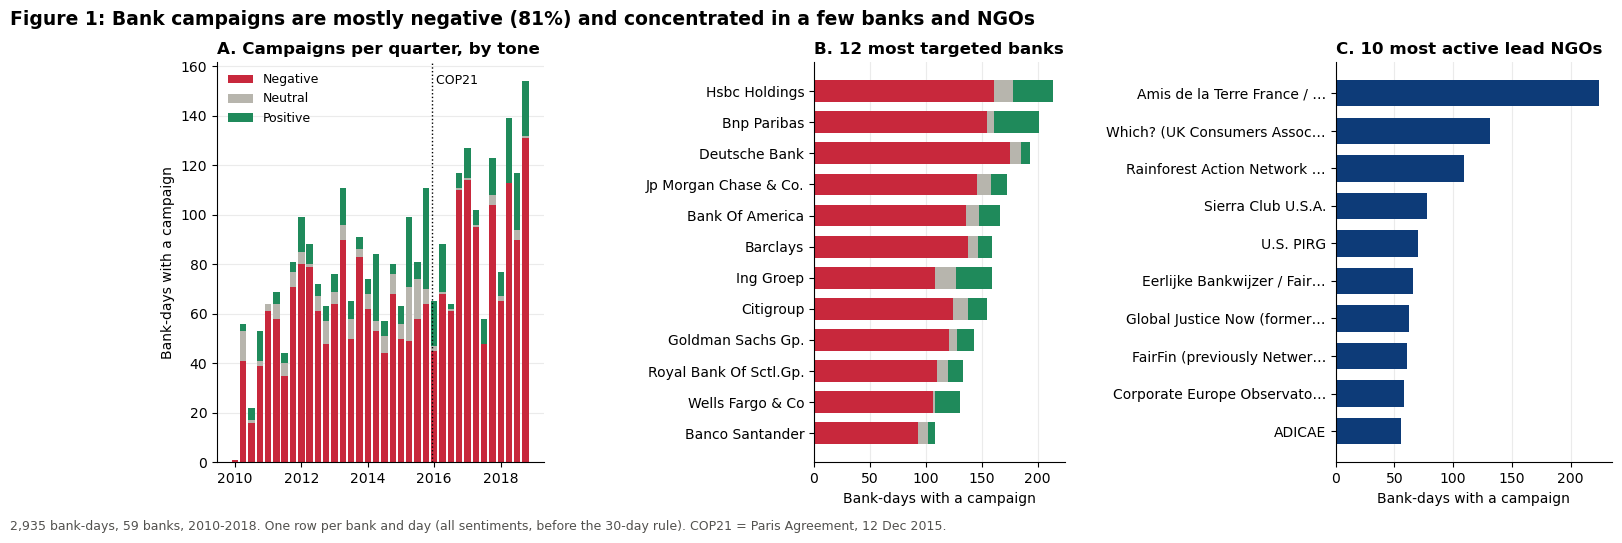

In [21]:
# Palette: red = negative, green = positive, grey = neutral (same as the PC Labs)
C = {"neg": "#c8283c", "neu": "#b7b5ad", "pos": "#1f8a5b", "navy": "#0d3b78", "grey": "#52514e"}
events["sign"] = np.select([events["sentiment"] < 0, events["sentiment"] > 0], ["neg", "pos"], "neu")
COP21 = pd.Timestamp("2015-12-12")                         # Paris Agreement

fig, axes = plt.subplots(1, 3, figsize=(18, 5.2), gridspec_kw={"width_ratios": [1.3, 1, 1.1], "wspace": 0.95})

# A. campaigns per quarter by tone
q = events.groupby([events["date"].dt.to_period("Q").dt.to_timestamp(), "sign"]).size().unstack(fill_value=0)
ax = axes[0]; bottom = np.zeros(len(q))
for s, lab in [("neg", "Negative"), ("neu", "Neutral"), ("pos", "Positive")]:
    ax.bar(q.index, q[s], width=70, bottom=bottom, color=C[s], label=lab); bottom += q[s].values
ax.axvline(COP21, color="black", ls=":", lw=1); ax.text(COP21, ax.get_ylim()[1] * 0.97, " COP21", va="top", fontsize=9)
ax.set_title("A. Campaigns per quarter, by tone", loc="left", fontweight="bold")
ax.set_ylabel("Bank-days with a campaign"); ax.legend(frameon=False, loc="upper left", fontsize=9)

# B. most targeted banks
top = events.groupby("ds_name").size().nlargest(12).index
b = events[events["ds_name"].isin(top)].groupby(["ds_name", "sign"]).size().unstack(fill_value=0).reindex(top)[::-1]
ax = axes[1]; left = np.zeros(len(b))
for s in ["neg", "neu", "pos"]:
    ax.barh(b.index.str.title(), b[s], left=left, color=C[s], height=0.7); left += b[s].values
ax.set_title("B. 12 most targeted banks", loc="left", fontweight="bold"); ax.set_xlabel("Bank-days with a campaign")

# C. most active NGOs
ngo_top = events.groupby("ngo").size().nlargest(10)[::-1]
ax = axes[2]; ax.barh([x[:26] + ("…" if len(x) > 26 else "") for x in ngo_top.index], ngo_top.values, color=C["navy"], height=0.7)
ax.set_title("C. 10 most active lead NGOs", loc="left", fontweight="bold"); ax.set_xlabel("Bank-days with a campaign")

for ax in axes: ax.spines[["top", "right"]].set_visible(False); ax.grid(alpha=0.25, axis="x" if ax is not axes[0] else "y"); ax.set_axisbelow(True)

# Panel A: one x label every 2 years (must come after the figure is created)
axes[0].xaxis.set_major_locator(mdates.YearLocator(2))
axes[0].xaxis.set_major_formatter(mdates.DateFormatter("%Y"))

share = (events["sign"] == "neg").mean()
fig.suptitle(f"Figure 1: Bank campaigns are mostly negative ({share:.0%}) and concentrated in a few banks and NGOs",
             x=0.01, ha="left", fontsize=13.5, fontweight="bold")
fig.text(0.01, -0.02, f"{len(events):,} bank-days, {events['ds_name'].nunique()} banks, 2010-2018. "
         "One row per bank and day (all sentiments, before the 30-day rule). COP21 = Paris Agreement, 12 Dec 2015.", fontsize=9, color=C["grey"])
plt.show()

**Comment:**

**A.** Campaigns against banks rise from about 20-80 per quarter in 2010–2011 to peaks of 120–155 in 2017–2018, and red (negative) dominates in every quarter. The positive share is largest in 2015 (about 23%), the year of COP21, when NGOs also praised banks for climate commitments.

**B.** A few large banks are the main targets: HSBC (214 bank-days), BNP Paribas (201) and Deutsche Bank (193). Deutsche Bank is almost purely negative, while BNP Paribas and ING also receive a visible share of positive campaigns.

**C.** Activity is concentrated in a handful of NGOs: Friends of the Earth France leads with 224 bank-days, followed by Which? (UK) at 131 and Rainforest Action Network at 109. Most are national or regional groups (France, UK, US, Belgium, Netherlands, Spain), so a few NGOs' repeated campaigns drive much of the sample.

### **Figure 2: What a campaign looks like**
We describe the three Sigwatch intensity variables: where the bank is mentioned (`prominence`), the reach of the strongest NGO (`ngo_power`) and how many firms are named in the same communication (`n_targets`).

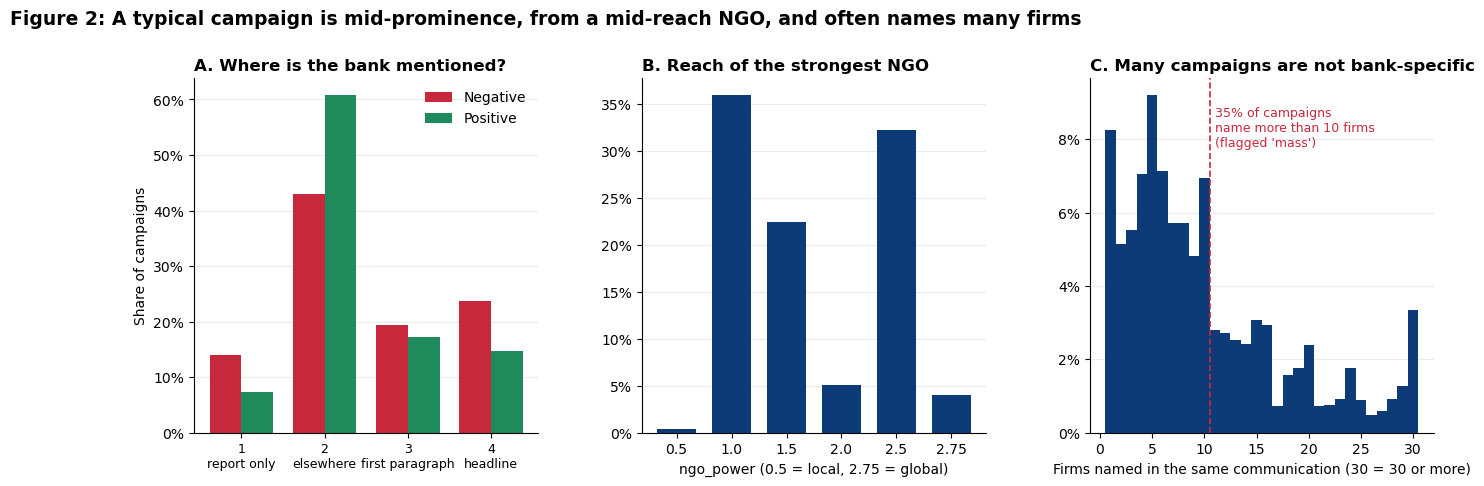

In [22]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.6), gridspec_kw={"wspace": 0.3})

# A. prominence, negative vs positive campaigns (share within each tone)
ax = axes[0]; w = 0.38; lv = [1, 2, 3, 4]
for k, (s, lab) in enumerate([("neg", "Negative"), ("pos", "Positive")]):
    sh = events[events["sign"] == s]["prominence"].value_counts(normalize=True).reindex(lv, fill_value=0)
    ax.bar(np.array(lv) + (k - 0.5) * w, sh.values, width=w, color=C[s], label=lab)
ax.set_xticks(lv, ["1\nreport only", "2\nelsewhere", "3\nfirst paragraph", "4\nheadline"], fontsize=9)
ax.yaxis.set_major_formatter(PercentFormatter(1, decimals=0)); ax.legend(frameon=False)
ax.set_title("A. Where is the bank mentioned?", loc="left", fontweight="bold"); ax.set_ylabel("Share of campaigns")

# B. reach of the strongest NGO
ax = axes[1]; p = events["ngo_power"].value_counts(normalize=True).sort_index()
ax.bar(p.index.astype(str), p.values, color=C["navy"], width=0.7)
ax.yaxis.set_major_formatter(PercentFormatter(1, decimals=0)); ax.set_xlabel("ngo_power (0.5 = local, 2.75 = global)")
ax.set_title("B. Reach of the strongest NGO", loc="left", fontweight="bold")

# C. firms named in the same communication
ax = axes[2]; clip = events["n_targets"].clip(upper=30)
ax.hist(clip, bins=np.arange(0.5, 31.5, 1), color=C["navy"], weights=np.ones(len(clip)) / len(clip))
ax.axvline(10.5, color=C["neg"], ls="--", lw=1.2)
ax.text(11, ax.get_ylim()[1] * 0.92, f"{events['mass'].mean():.0%} of campaigns\nname more than 10 firms\n(flagged 'mass')", color=C["neg"], fontsize=9, va="top")
ax.yaxis.set_major_formatter(PercentFormatter(1, decimals=0)); ax.set_xlabel("Firms named in the same communication (30 = 30 or more)")
ax.set_title("C. Many campaigns are not bank-specific", loc="left", fontweight="bold")

for ax in axes: ax.spines[["top", "right"]].set_visible(False); ax.grid(alpha=0.25, axis="y"); ax.set_axisbelow(True)
fig.suptitle("Figure 2: A typical campaign is mid-prominence, from a mid-reach NGO, and often names many firms",
             x=0.01, ha="left", fontsize=13.5, fontweight="bold", y=1.03)
plt.show()

**Comment:**

**A.** Negative campaigns put the bank in more visible places than positive ones: about 24% mention it in the headline versus 15% of positive campaigns. Positive news is mostly mentioned elsewhere in the text (about 61%).

**B.** The reach of the lead NGO is bimodal: about 36% of campaigns come from NGOs with reach 1.0 (local or national groups) and 32% from NGOs at 2.5 (international groups). Very local (0.5) and very global (2.75) NGOs are rare.

**C.** Most campaigns name few firms (a peak at 5), but 35% name more than 10, and a small group names 30 or more. These are bank rankings and multi-company reports, not bank-specific news, so we flag them as `mass` and use them as a robustness check.

## A5. Handoff files
- `events_banks.csv`: one row per bank-day, with the flags and the ISIN. **C uses it for the event study.** `uids` links each row back to its campaigns.
- `campaigns_banks.csv`: one row per campaign, with the report text and links. **D uses it for the add-on, and A for the NLP step.**
- `lookup_banks.csv`: Sigwatch name → Datastream name → ISIN.

In [23]:
# One row per campaign, with the text and links
campaigns = (banks.groupby("uid_archive", as_index=False)
             .agg(date=("date", "first"), ngo=("ngo_name1", "first"), ngo_power=("ngo_power", "max"),
                  sentiment=("sentiment", "mean"), prominence=("prominence", "max"), climate=("climate", "max"),
                  n_targets=("n_targets", "first"), n_banks=("ds_name", "nunique"),
                  banks=("ds_name", lambda s: "; ".join(sorted(set(s)))),
                  issue_name1=("issue_name1", "first"), issue_name2=("issue_name2", "first"), issue_name3=("issue_name3", "first"),
                  report=("report", "first"), link1=("link1", "first"), link2=("link2", "first"), link3=("link3", "first"),
                  link4=("link4", "first"), link5=("link5", "first")))
campaigns["report"] = campaigns["report"].fillna("").str.replace(r"<[^>]+>", " ", regex=True).map(html.unescape).str.strip()   # HTML -> plain text

events.to_csv(OUT / "events_banks.csv", index=False)
campaigns.to_csv(OUT / "campaigns_banks.csv", index=False)
lookup.to_csv(OUT / "lookup_banks.csv", index=False)
print(f"{len(events):,} bank-days | {len(campaigns):,} campaigns | {(campaigns['report'].str.len() > 0).mean():.0%} with report text, "
      f"{(campaigns['link1'].fillna('').str.len() > 0).mean():.0%} with a link")

2,935 bank-days | 1,311 campaigns | 100% with report text, 100% with a link


## A6 Task 1: Campaign Echo
Use names of targeted firms and NGO and the date of the campaign to see if major news outlet and newswires echoed the scandal. We gathered the data from the Factiva database.

**Definition of echo.** News echo is detected when at least one accepted, campaign-relevant press or newswire story appears during calendar days 0–7 relative to the recorded campaign date. The tests ran use occurrence, detected echo or no detected echo, rather than story counts. A zero means that no qualifying coverage was retrieved through the selected searches, not that no coverage existed.

**Remarks:** Due to the provate nature of the information, The article datasets are not disclosed with the analysis. The batching, merging and query creation operations are in python scripts and called as helper functions, the scripts can be found in the repository.

### A6.1 Sampling Candidates
We randomly sampled 300 NGO campaigns to assess the occurrence and intensity of media echo. Because Factiva searches and article exports had to be performed manually, full-sample data collection was impractical. We therefore drew a random sample of 300 campaigns to keep the analysis feasible.

Using LLM-assisted bank and NGO name dictionaries, we constructed batched Factiva queries restricted to a predefined panel of reputable national and international news outlets, including Reuters. 

Exported articles underwent LLM-assisted screening for campaign-specific relevance and local text-based deduplication, grouping identified print/online copies and repeated wire versions into single stories. Excluding campaigns with uncertain matches or documented collection gaps (due to limitations in the data collection) left 252 campaigns for the echo analysis, with coverage measured during calendar days 0–7 relative to the recorded campaign 
date.

**Observation window:** We measure news echo during calendar days 0–7 to capture coverage close to the campaign’s recorded date and avoid gathering unrelated news. This differs from the [−10, +10] trading-day return window, which measures stock-price movements before and after the event. The windows serve different purposes; the seven-day cutoff is a measurement choice rather than a requirement of the return model.

In [41]:
campaigns = pd.read_csv(
    "handoff/campaigns_banks.csv",
    dtype={"uid_archive": str},
)

sample = (
    campaigns.sample(n=300, random_state=42)
    .sort_values(["date", "uid_archive"])
    .reset_index(drop=True)
)

sample.to_csv("handoff/echo_sample.csv", index=False)
print(f"Selected {len(sample)} campaigns.")

Selected 300 campaigns.


In [43]:
# Load bank/NGO aliases and the Factiva query builder.
'''python files that are used in the notebook. 
Contain dictionaries of bank and NGO aliases, 
and a function to build Factiva queries for each campaign.'''

from echo_aliases import BANK_ALIASES, NGO_ALIASES 
from factiva_echo_queries import campaign_query

# Build one Boolean search query per sampled campaign.
sample["factiva_query"] = sample.apply(campaign_query, axis=1)

**Sample attrition.**

 Of the initial 300 randomly sampled campaigns, 252 remain eligible due to impossibility to access data. Exclusions do not reduce mass-campaign representation: 38 of the 48 exclusions concern 2013–2014, reducing those years’ combined share from 23.7% to 13.1%. Collection-related attrition also affects NGO representation, ikn particular "Which?". 
 Results therefore describe the eligible searched sample; weighting to restore the initial year distribution changes the overall detected echo rate from 5.16% to 4.79%.

### Figure A6.1

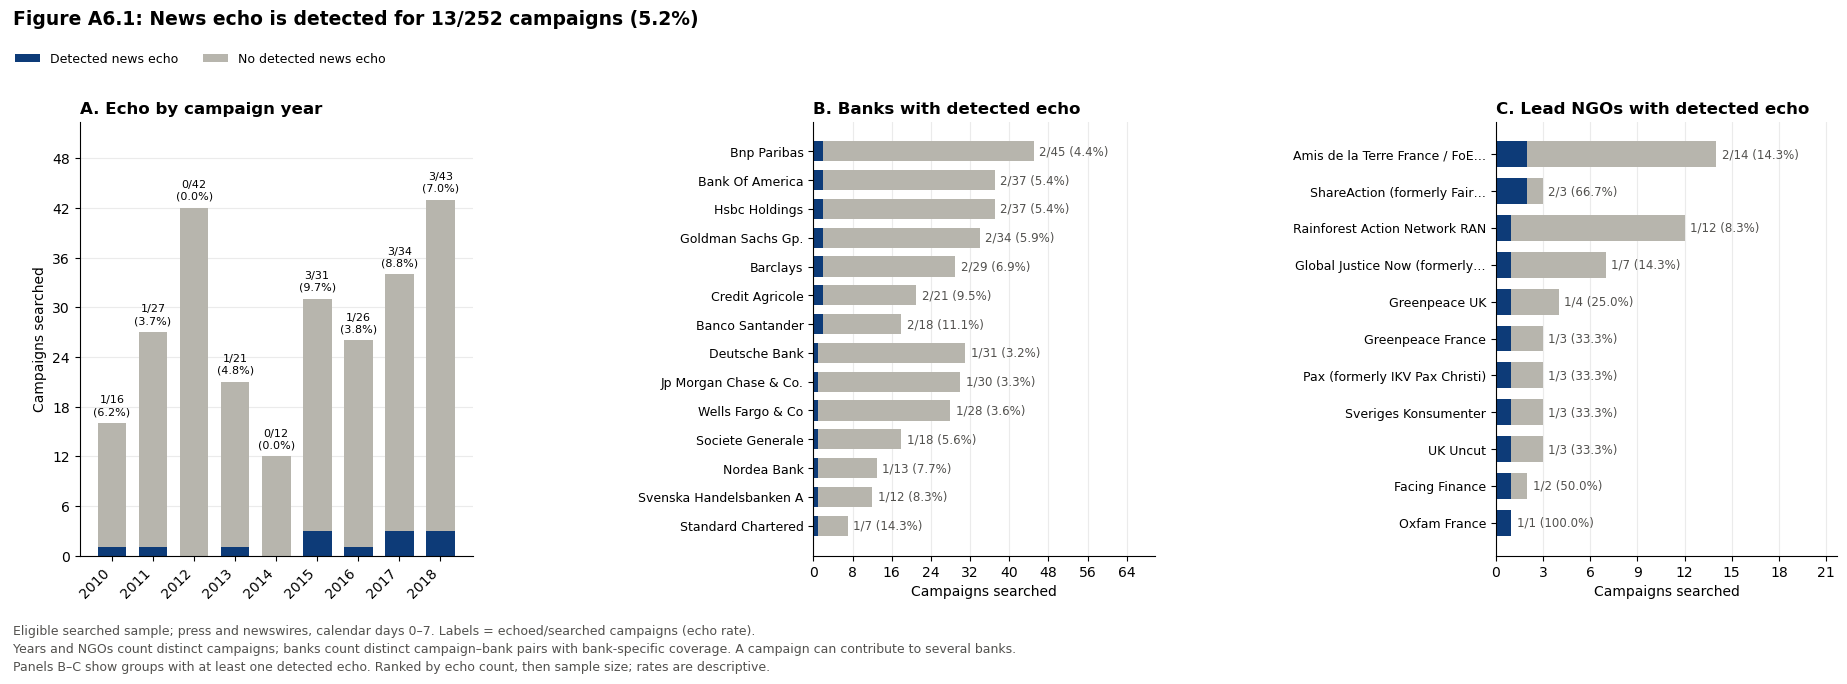

In [47]:
folder = Path("handoff/echo_final")
#echo_final was elaborated through helper functions in the repository
#worked by merging the extracted dataset, scoring it and filtering it to keep only the relevant campaigns and banks

campaign_echo = pd.read_csv(
    folder / "final_campaign_pool.csv",
    dtype={"uid_archive": str},
    parse_dates=["date"],
)
bank_echo = pd.read_csv(
    folder / "final_bank_pool.csv",
    dtype={"uid_archive": str},
)

OUTCOME = "news_observed_post7" 
NAVY, GREY, TEXT = "#0d3b78", "#b7b5ad", "#52514e"

# Campaign-level observations for years and NGOs.
campaign_echo["year"] = campaign_echo["date"].dt.year

# Bank-specific echo: use the bank pool rather than assigning a
# campaign's echo to every bank targeted by that campaign.
bank_echo = bank_echo[
    bank_echo["uid_archive"].isin(campaign_echo["uid_archive"])
].copy()

assert not campaign_echo["uid_archive"].duplicated().any()
assert not bank_echo.duplicated(["uid_archive", "ds_name"]).any()

def echo_counts(frame, variable):
    table = frame.groupby(variable)[OUTCOME].agg(
        searched="size",
        echoed="sum",
    )
    table["no_echo"] = table["searched"] - table["echoed"]
    table["rate"] = table["echoed"] / table["searched"]
    return table

annual = echo_counts(campaign_echo, "year")

# Show every bank and NGO with at least one detected echo.
# Rank by echo count; break ties by the number searched.
banks_echoed = (
    echo_counts(bank_echo, "ds_name")
    .query("echoed > 0")
    .sort_values(["echoed", "searched"], ascending=False)
)
ngos_echoed = (
    echo_counts(campaign_echo, "ngo")
    .query("echoed > 0")
    .sort_values(["echoed", "searched"], ascending=False)
)

def horizontal_echo(ax, table, bank_names=False):
    table = table.iloc[::-1]  # highest count at the top
    y = np.arange(len(table))
    names = table.index.str.title() if bank_names else table.index

    ax.barh(y, table["echoed"], color=NAVY, height=.7)
    ax.barh(
        y, table["no_echo"], left=table["echoed"],
        color=GREY, height=.7,
    )
    ax.set_yticks(
        y,
        [shorten(str(name), width=32, placeholder="…") for name in names],
        fontsize=9,
    )

    offset = max(0.3, table["searched"].max() * .025)
    for yi, row in zip(y, table.itertuples()):
        ax.text(
            row.searched + offset, yi,
            f"{row.echoed}/{row.searched} ({row.rate:.1%})",
            va="center", fontsize=8.5, color=TEXT,
        )

    ax.set_xlim(0, table["searched"].max() * 1.55)
    ax.set_xlabel("Campaigns searched")
    ax.xaxis.set_major_locator(MaxNLocator(integer=True))

with plt.rc_context({
    "font.family": "DejaVu Sans",
    "font.size": 10,
    "text.color": "black",
    "axes.labelcolor": "black",
}):
    fig, axes = plt.subplots(
        1, 3, figsize=(19, 7),
        gridspec_kw={"width_ratios": [1.15, 1, 1], "wspace": .95},
    )
    fig.set_facecolor("white")

    # A. Annual campaign counts.
    ax = axes[0]
    x = np.arange(len(annual))

    ax.bar(x, annual["echoed"], color=NAVY, width=.7)
    ax.bar(
        x, annual["no_echo"], bottom=annual["echoed"],
        color=GREY, width=.7,
    )
    ax.set_xticks(x, annual.index.astype(str), rotation=45, ha="right")
    ax.set_ylabel("Campaigns searched")
    ax.set_ylim(0, annual["searched"].max() * 1.22)
    ax.yaxis.set_major_locator(MaxNLocator(integer=True))

    for xi, row in zip(x, annual.itertuples()):
        ax.text(
            xi, row.searched + .8,
            f"{row.echoed}/{row.searched}\n({row.rate:.1%})",
            ha="center", va="bottom", fontsize=8,
        )

    ax.set_title(
        "A. Echo by campaign year", loc="left", fontweight="bold"
    )

    # B. Bank-specific coverage.
    horizontal_echo(axes[1], banks_echoed, bank_names=True)
    axes[1].set_title(
        "B. Banks with detected echo", loc="left", fontweight="bold"
    )

    # C. Coverage of campaigns attributed to each lead NGO.
    horizontal_echo(axes[2], ngos_echoed)
    axes[2].set_title(
        "C. Lead NGOs with detected echo", loc="left", fontweight="bold"
    )

    for i, ax in enumerate(axes):
        ax.spines[["top", "right"]].set_visible(False)
        ax.grid(alpha=.25, axis="y" if i == 0 else "x")
        ax.set_axisbelow(True)

    n = len(campaign_echo)
    k = int(campaign_echo[OUTCOME].sum())

    fig.suptitle(
        f"Figure A6.1: News echo is detected for {k}/{n} campaigns ({k/n:.1%})",
        x=.02, y=.98, ha="left", fontsize=13.5, fontweight="bold",
    )
    fig.legend(
        handles=[
            Patch(facecolor=NAVY, label="Detected news echo"),
            Patch(facecolor=GREY, label="No detected news echo"),
        ],
        loc="upper left", bbox_to_anchor=(.015, .935),
        ncol=2, frameon=False, fontsize=9,
    )
    fig.text(
        .02, .035,
        "Eligible searched sample; press and newswires, calendar days 0–7. "
        "Labels = echoed/searched campaigns (echo rate).\n"
        "Years and NGOs count distinct campaigns; banks count distinct campaign–bank pairs "
        "with bank-specific coverage. A campaign can contribute to several banks.\n"
        "Panels B–C show groups with at least one detected echo. "
        "Ranked by echo count, then sample size; rates are descriptive.",
        fontsize=9, color=TEXT, linespacing=1.5,
    )
    fig.subplots_adjust(top=.82, bottom=.20, left=.055, right=.98)
    plt.show()

**comment:**

**A. Timing.** News echo is detected for 13 of 252 eligible campaigns (5.2%). The largest counts occur in 2015, 2017 and 2018, with three echoed campaigns each. Their rates differ, 9.7%, 8.8% and 7.0%, because the numbers searched differ. These small counts do not establish a time trend, and zero detected echoes in 2012 or 2014 do not demonstrate an absence of coverage.

**B. Banks.** Seven banks share the highest count, with two echoed campaigns each. Their rates range from 4.4% for BNP Paribas (2/45) to 11.1% for Banco Santander (2/18). Several frequently targeted banks in Figure 1 also appear here, including HSBC, BNP Paribas and Bank of America. However, frequent targeting does not necessarily translate into a higher observed echo rate: Deutsche Bank has one echoed campaign among 31 searched. Coverage is assigned to the banks actually discussed in the accepted articles, rather than automatically to every campaign target.

**C. NGOs.** Friends of the Earth France and ShareAction have the most echoed campaigns, with two each, but different denominators: 2/14 and 2/3. Friends of the Earth France also leads campaign activity in Figure 1, whereas ShareAction illustrates how an NGO with fewer sampled campaigns can still generate detectable coverage. High percentages based on very small samples, such as Oxfam France’s 1/1, should not be interpreted as reliable measures of media effectiveness.

**Comparison with Figure 1 of Part A** Figure 1 describes NGO activity across 2,935 bank-days; Figure A6.1 describes detected coverage within 252 eligible campaigns, with bank-specific campaign–bank observations in panel B. Counts therefore cannot be compared directly. The figures also aggregate time differently—quarters versus years—and A6.1’s bank and NGO panels display only groups with detected echo. Sample attrition further limits comparison: 38 of the 48 exclusions concern 2013–2014, and all six sampled Which? campaigns were excluded because of collection problems. Its absence from A6.1 is therefore not evidence that its campaigns received no coverage.

**Value of the analysis.** This figure distinguishes how often banks are targeted from whether those campaigns receive detectable mainstream coverage. Campaign-specific matching and deduplication provide a measure of press visibility beyond NGO activity alone, creating a basis for examining whether stock-market reactions differ when campaigns receive wider attention. The findings remain descriptive: coverage is measured within selected outlets and days 0–7, only 13 campaigns have detected echo, and the analysis does not establish that NGO characteristics caused coverage or that coverage caused stock-price movements.

### Figure A6.2

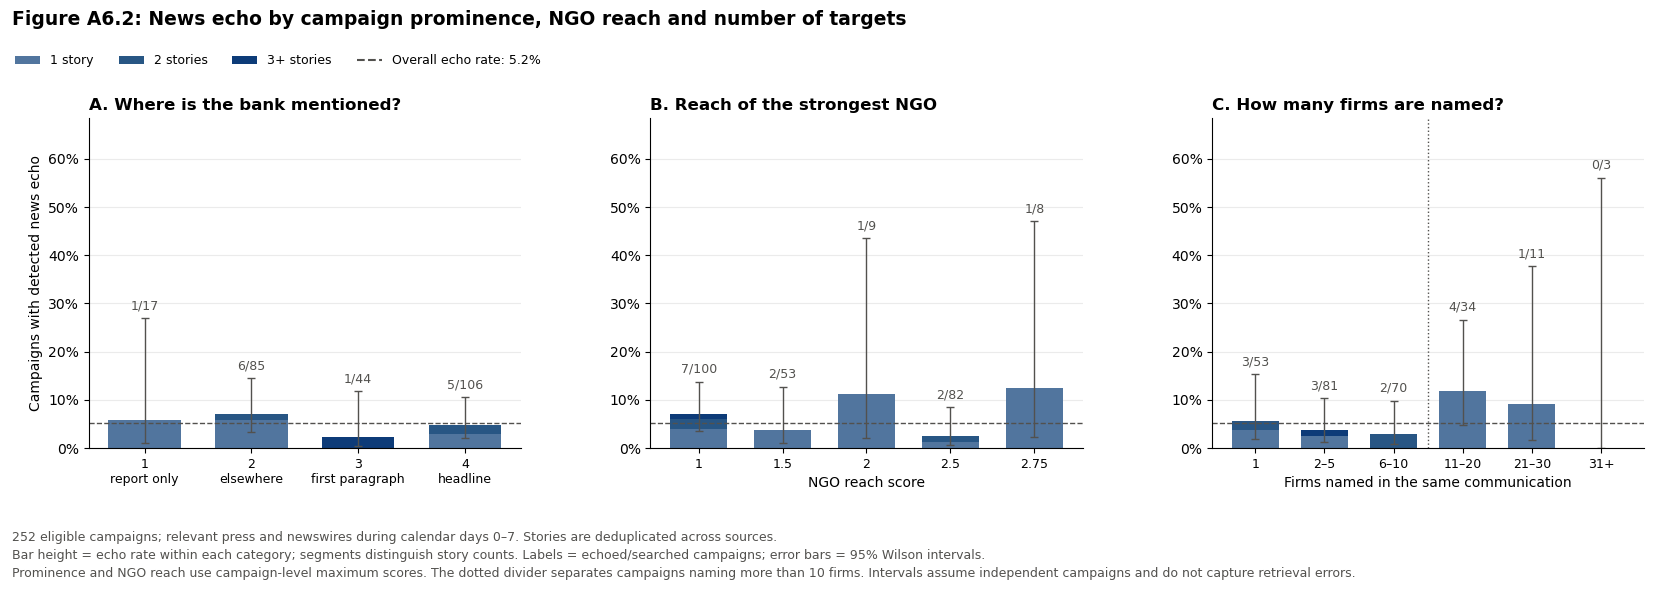

In [48]:
folder = Path("handoff/echo_final")
echo_profile = pd.read_csv(
    folder / "final_campaign_pool.csv",
    dtype={"uid_archive": str},
)

# Count distinct story groups across press and newswires, days 0–7.
evidence = pd.concat([
    pd.read_csv(
        folder / filename,
        usecols=["uid_archive", "relative_day", "count_story_id"],
        dtype={"uid_archive": str},
    )
    for filename in ["final_pool.csv", "final_wire_pool.csv"]
], ignore_index=True)

evidence = evidence[
    evidence["uid_archive"].isin(echo_profile["uid_archive"])
    & evidence["relative_day"].between(0, 7)
]

story_counts = evidence.groupby("uid_archive")["count_story_id"].nunique()
echo_profile["stories"] = (
    echo_profile["uid_archive"].map(story_counts).fillna(0).astype(int)
)

assert echo_profile["stories"].gt(0).astype(int).eq(
    echo_profile["news_observed_post7"]
).all()

# Group target counts because echoed campaigns are sparse.
echo_profile["target_group"] = pd.cut(
    echo_profile["n_targets"],
    bins=[0, 1, 5, 10, 20, 30, np.inf],
    labels=["1", "2–5", "6–10", "11–20", "21–30", "31+"],
)
assert echo_profile["target_group"].notna().all()

COLORS = ["#51759E", "#285684", "#0d3b78"]
TEXT = "#52514e"
baseline = echo_profile["stories"].gt(0).mean()

def profile_table(variable):
    return echo_profile.groupby(variable, observed=True)["stories"].agg(
        n="size",
        k=lambda s: s.gt(0).sum(),
        one=lambda s: s.eq(1).sum(),
        two=lambda s: s.eq(2).sum(),
        many=lambda s: s.ge(3).sum(),
    )

def wilson_bounds(k, n):
    k, n = np.asarray(k, float), np.asarray(n, float)
    p, z = k / n, 1.96
    denominator = 1 + z**2 / n
    centre = (p + z**2 / (2*n)) / denominator
    half = z * np.sqrt(p*(1-p)/n + z**2/(4*n**2)) / denominator
    return np.maximum(0, centre-half), np.minimum(1, centre+half)

tables = [
    profile_table("prominence"),
    profile_table("ngo_power"),
    profile_table("target_group"),
]

labels = [
    ["1\nreport only", "2\nelsewhere", "3\nfirst paragraph", "4\nheadline"],
    [f"{value:g}" for value in tables[1].index],
    tables[2].index.astype(str).tolist(),
]

titles = [
    "A. Where is the bank mentioned?",
    "B. Reach of the strongest NGO",
    "C. How many firms are named?",
]

# Use the same vertical scale across all three panels.
upper = max(wilson_bounds(t["k"], t["n"])[1].max() for t in tables)
ymax = min(1, upper * 1.22)

with plt.rc_context({
    "font.family": "DejaVu Sans",
    "font.size": 10,
    "text.color": "black",
    "axes.labelcolor": "black",
}):
    fig, axes = plt.subplots(
        1, 3, figsize=(17, 6),
        gridspec_kw={"wspace": .30},
    )
    fig.set_facecolor("white")

    for ax, table, tick_labels, title in zip(
        axes, tables, labels, titles
    ):
        x = np.arange(len(table))
        bottom = np.zeros(len(table))

        for column, color in zip(["one", "two", "many"], COLORS):
            heights = table[column].to_numpy() / table["n"].to_numpy()
            ax.bar(
                x, heights, bottom=bottom,
                width=.68, color=color,
            )
            bottom += heights

        lo, hi = wilson_bounds(table["k"], table["n"])

        ax.errorbar(
            x, bottom,
            yerr=np.maximum(0, np.vstack([bottom-lo, hi-bottom])),
            fmt="none", color=TEXT,
            elinewidth=1, capsize=3,
        )
        ax.axhline(
            baseline, color=TEXT, linestyle="--", linewidth=1,
        )

        # Labels show echoed/searched campaigns.
        for xi, row, limit in zip(x, table.itertuples(), hi):
            ax.text(
                xi, limit + .012,
                f"{row.k}/{row.n}",
                ha="center", va="bottom",
                fontsize=9, color=TEXT,
            )

        ax.set_xticks(x, tick_labels, fontsize=9)
        ax.set_ylim(0, ymax)
        ax.yaxis.set_major_formatter(PercentFormatter(1, decimals=0))
        ax.set_title(title, loc="left", fontweight="bold", fontsize=12)
        ax.spines[["top", "right"]].set_visible(False)
        ax.grid(axis="y", alpha=.25)
        ax.set_axisbelow(True)

    axes[0].set_ylabel("Campaigns with detected news echo")
    axes[1].set_xlabel("NGO reach score")
    axes[2].set_xlabel("Firms named in the same communication")

    # Separate campaigns naming <=10 firms from mass campaigns.
    axes[2].axvline(2.5, color=TEXT, linestyle=":", linewidth=1)

    fig.suptitle(
        "Figure A6.2: News echo by campaign prominence, NGO reach and number of targets",
        x=.02, y=.98, ha="left", fontsize=13.5, fontweight="bold",
    )

    handles = [
        Patch(facecolor=color, label=label)
        for color, label in zip(COLORS, ["1 story", "2 stories", "3+ stories"])
    ]
    handles.append(
        Line2D(
            [], [], color=TEXT, linestyle="--",
            label=f"Overall echo rate: {baseline:.1%}",
        )
    )
    fig.legend(
        handles=handles, loc="upper left",
        bbox_to_anchor=(.015, .925),
        ncol=4, frameon=False, fontsize=9,
    )

    fig.text(
        .02, .035,
        "252 eligible campaigns; relevant press and newswires during calendar days 0–7. "
        "Stories are deduplicated across sources.\n"
        "Bar height = echo rate within each category; segments distinguish story counts. "
        "Labels = echoed/searched campaigns; error bars = 95% Wilson intervals.\n"
        "Prominence and NGO reach use campaign-level maximum scores. "
        "The dotted divider separates campaigns naming more than 10 firms. "
        "Intervals assume independent campaigns and do not capture retrieval errors.",
        fontsize=9, color=TEXT, linespacing=1.5,
    )
    fig.subplots_adjust(top=.80, bottom=.25, left=.065, right=.98)
    plt.show()

**comment:**

**A. Prominence.** Detected echo does not increase consistently with the bank’s prominence in the NGO communication. Campaigns with prominence 2 have the highest observed rate, 7.1% (6/85), compared with 4.7% for headline campaigns (5/106). Figure 2 (part A) shows that negative campaigns mention banks in headlines more frequently than positive campaigns, but D2 suggests that prominence within the original communication does not automatically translate into mainstream coverage.

**B. NGO reach.** NGOs with reach score 1.0 account for the largest number of echoed campaigns (7/100). The highest rates occur at scores 2.75 (1/8) and 2.0 (1/9), but each rests on a single observation. Although Figure 2 shows substantial campaign activity among NGOs with reach 2.5, their detected echo rate here is only 2.4% (2/82). Organisational reach and observed press amplification are therefore distinct measures; these small samples cannot establish which NGOs are more effective at attracting coverage.

**C. Number of targets.** Campaigns naming 11–20 firms have the highest observed echo rate, 11.8% (4/34). Across all mass campaigns (those naming more than ten firms) echo is detected for 5/48 (10.4%), compared with 8/204 (3.9%) among other campaigns. This is a descriptive pattern, rather than an established difference. It also illustrates that a multi-firm campaign can attract coverage while remaining difficult to interpret as bank-specific news in an event study.

**Comparison with Figure 2.** Figure 2 describes how campaign characteristics are distributed; A6.2 measures the proportion receiving echo within each category. The bar heights therefore answer different questions. Figure 2 uses bank-day observations, while A6.2 uses distinct campaigns and campaign-level maximum prominence and reach scores. This also helps explain the different mass shares: mass campaigns represent approximately 35% of Figure 2’s bank-days but 19% of the eligible echo campaigns, close to 19.4% in the full campaign-level dataset. Collection-related exclusions, particularly in 2013–2014, further limit direct comparison.

**Value and limitations.** A6.2 examines whether characteristics describing NGO activity also distinguish campaigns that receive detectable press coverage. It separates prominence in an NGO communication, organisational reach and campaign breadth from subsequent media visibility. The exact tests do not establish differences by these characteristics after multiple-testing adjustment. With only 13 echoed campaigns, wide intervals and possible dependence between campaigns, this should be interpreted as limited evidence rather than proof that these characteristics do not matter.

### Figure A6.3

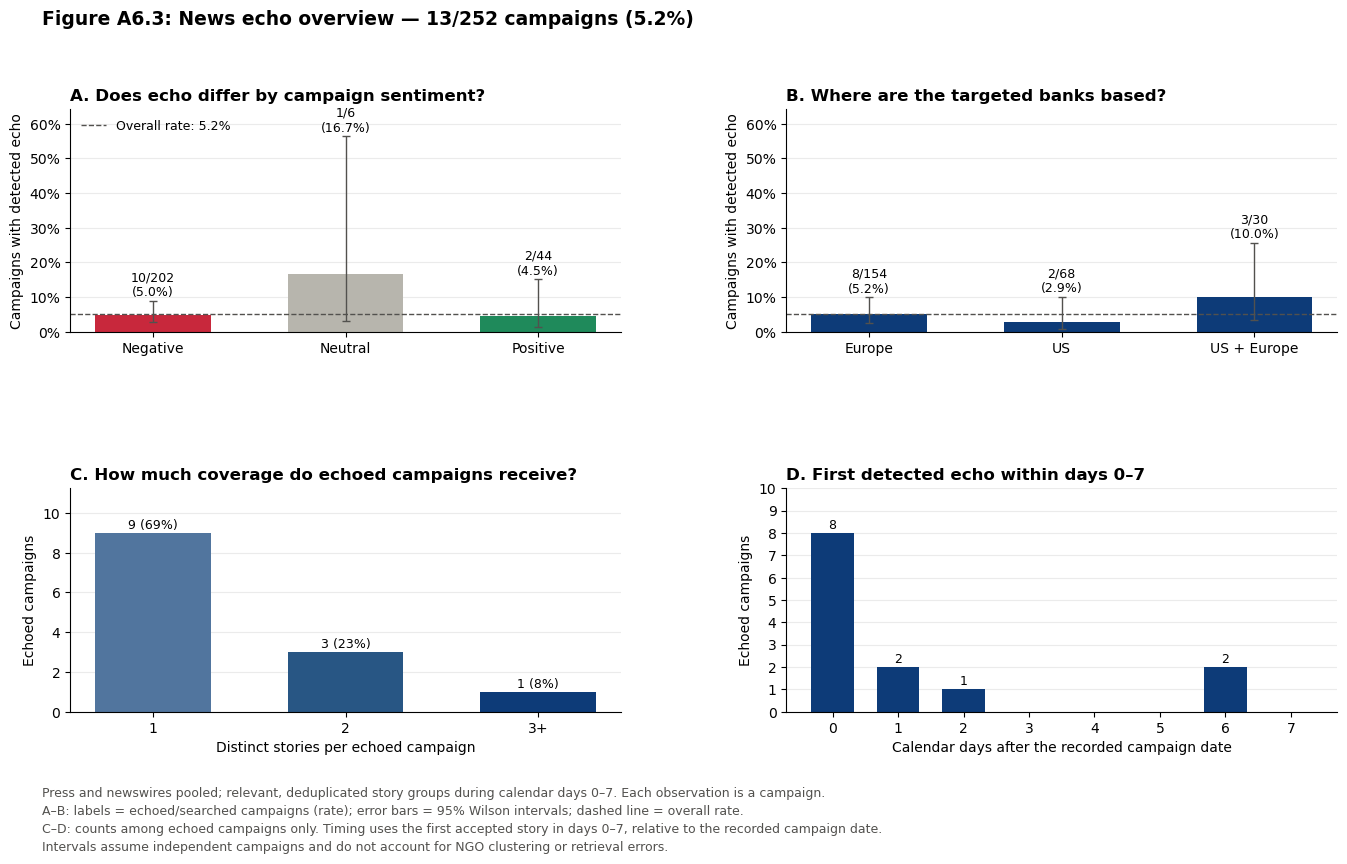

In [49]:
folder = Path("handoff/echo_final")

# Keep d available for the subsequent exact-test cell.
d = pd.read_csv(
    folder / "final_campaign_pool.csv",
    dtype={"uid_archive": str},
    parse_dates=["date"],
)

articles = pd.concat([
    pd.read_csv(
        folder / filename,
        usecols=["uid_archive", "relative_day", "count_story_id"],
        dtype={"uid_archive": str},
    )
    for filename in ["final_pool.csv", "final_wire_pool.csv"]
], ignore_index=True)

articles = articles[
    articles["uid_archive"].isin(d["uid_archive"])
    & articles["relative_day"].between(0, 7)
]

counts = articles.groupby("uid_archive")["count_story_id"].nunique()
d["stories"] = d["uid_archive"].map(counts).fillna(0).astype(int)
d["echo"] = d["stories"].gt(0).astype(int)
d["year"] = d["date"].dt.year

assert d["echo"].eq(d["news_observed_post7"]).all()

# Same sentiment grouping as the campaign handoff.
d["tone"] = np.select(
    [d["sentiment"].lt(0), d["sentiment"].gt(0)],
    ["Negative", "Positive"],
    default="Neutral",
)

N, K = len(d), int(d["echo"].sum())
baseline = K / N
NAVY, TEXT = "#0d3b78", "#52514e"

def rate_table(variable, order):
    return (
        d.groupby(variable)["echo"]
        .agg(n="size", k="sum")
        .reindex(order)
    )

def wilson(k, n):
    k, n = np.asarray(k, float), np.asarray(n, float)
    p, z = k / n, 1.96
    denominator = 1 + z*z/n
    centre = (p + z*z/(2*n)) / denominator
    half = z*np.sqrt(p*(1-p)/n + z*z/(4*n*n)) / denominator
    return np.maximum(0, centre-half), np.minimum(1, centre+half)

sentiment = rate_table("tone", ["Negative", "Neutral", "Positive"])
geography = rate_table(
    "bank_region", ["Europe", "US", "US and Europe"]
)

# Common scale for the two rate panels.
rate_top = max(
    wilson(table["k"], table["n"])[1].max()
    for table in [sentiment, geography]
) + .08

def rate_panel(ax, table, labels, colors, title):
    x = np.arange(len(table))
    rates = table["k"] / table["n"]
    lo, hi = wilson(table["k"], table["n"])

    ax.bar(x, rates, color=colors, width=.6)
    ax.errorbar(
        x, rates,
        yerr=np.maximum(0, np.vstack([rates-lo, hi-rates])),
        fmt="none", color=TEXT, capsize=3, elinewidth=1,
    )
    ax.axhline(
        baseline, color=TEXT, ls="--", lw=1,
        label=f"Overall rate: {baseline:.1%}",
    )

    for xi, row, upper in zip(x, table.itertuples(), hi):
        ax.text(
            xi, upper + .015,
            f"{row.k}/{row.n}\n({row.k/row.n:.1%})",
            ha="center", fontsize=9,
        )

    ax.set_xticks(x, labels)
    ax.set_ylim(0, rate_top)
    ax.yaxis.set_major_formatter(PercentFormatter(1, decimals=0))
    ax.set_ylabel("Campaigns with detected echo")
    ax.set_title(title, loc="left", fontweight="bold", fontsize=12)

with plt.rc_context({
    "font.family": "DejaVu Sans",
    "font.size": 10,
    "text.color": "black",
    "axes.labelcolor": "black",
}):
    fig, axes = plt.subplots(
        2, 2, figsize=(14, 9),
        gridspec_kw={"hspace": .70, "wspace": .30},
    )
    fig.set_facecolor("white")

    # A. Sentiment: retain Part A's colour meanings.
    rate_panel(
        axes[0, 0], sentiment, sentiment.index,
        ["#c8283c", "#b7b5ad", "#1f8a5b"],
        "A. Does echo differ by campaign sentiment?",
    )
    axes[0, 0].legend(
        frameon=False, fontsize=9, loc="upper left"
    )

    # B. Geography refers to targeted banks, not news outlets.
    rate_panel(
        axes[0, 1], geography, ["Europe", "US", "US + Europe"],
        NAVY, "B. Where are the targeted banks based?",
    )

    # C. Intensity, conditional on detecting echo.
    covered = d[d["echo"].eq(1)]
    intensity = np.array([
        covered["stories"].eq(1).sum(),
        covered["stories"].eq(2).sum(),
        covered["stories"].ge(3).sum(),
    ])

    ax = axes[1, 0]
    x = np.arange(3)
    ax.bar(
        x, intensity,
        color=["#51759E", "#285684", NAVY], width=.6,
    )
    ax.set_xticks(x, ["1", "2", "3+"])

    for xi, count in zip(x, intensity):
        ax.text(
            xi, count + .2, f"{count} ({count/K:.0%})",
            ha="center", fontsize=9,
        )

    ax.set_ylim(0, max(1, intensity.max()*1.25))
    ax.set_xlabel("Distinct stories per echoed campaign")
    ax.set_ylabel("Echoed campaigns")
    ax.set_title(
        "C. How much coverage do echoed campaigns receive?",
        loc="left", fontweight="bold", fontsize=12,
    )

    # D. First accepted story inside the observation window.
    first_day = (
        articles.groupby("uid_archive")["relative_day"].min().astype(int)
    )
    assert len(first_day) == K
    lag = first_day.value_counts().reindex(range(8), fill_value=0)

    ax = axes[1, 1]
    ax.bar(lag.index, lag.values, color=NAVY, width=.65)

    for day, count in lag.items():
        if count:
            ax.text(
                day, count + .2, str(count),
                ha="center", fontsize=9,
            )

    ax.set_xticks(range(8))
    ax.set_ylim(0, max(1, lag.max()*1.25))
    ax.set_xlabel("Calendar days after the recorded campaign date")
    ax.set_ylabel("Echoed campaigns")
    ax.set_title(
        "D. First detected echo within days 0–7",
        loc="left", fontweight="bold", fontsize=12,
    )

    for ax in axes.flat:
        ax.spines[["top", "right"]].set_visible(False)
        ax.grid(axis="y", alpha=.25)
        ax.set_axisbelow(True)

    for ax in axes[1]:
        ax.yaxis.set_major_locator(MaxNLocator(integer=True))

    fig.suptitle(
        f"Figure A6.3: News echo overview — {K}/{N} campaigns ({baseline:.1%})",
        x=.055, y=.97, ha="left", fontsize=13.5, fontweight="bold",
    )
    fig.text(
        .055, .035,
        "Press and newswires pooled; relevant, deduplicated story groups during "
        "calendar days 0–7. Each observation is a campaign.\n"
        "A–B: labels = echoed/searched campaigns (rate); error bars = 95% Wilson "
        "intervals; dashed line = overall rate.\n"
        "C–D: counts among echoed campaigns only. Timing uses the first accepted "
        "story in days 0–7, relative to the recorded campaign date.\n"
        "Intervals assume independent campaigns and do not account for NGO "
        "clustering or retrieval errors.",
        fontsize=9, color=TEXT, linespacing=1.5,
    )
    fig.subplots_adjust(top=.86, bottom=.19, left=.075, right=.98)
    plt.show()

**comment:**

**A. Sentiment.** Negative and positive campaigns have similar detected echo rates: 5.0% (10/202) and 4.5% (2/44). Negative campaigns account for most echoed observations mainly because they dominate the eligible sample. The category labelled “Neutral” has a higher rate, 16.7%, but contains only six campaigns and one detected echo. More precisely, these are zero-average sentiment campaigns: five have neutral bank observations, while one combines positive and negative bank scores.

**B. Geography.** Campaigns targeting both US and European banks have the highest observed rate, 10.0% (3/30), followed by European-only campaigns at 5.2% (8/154) and US-only campaigns at 2.9% (2/68). The overlapping intervals and small counts do not establish a geographic difference. These categories describe the targeted banks’ locations, not the locations or audiences of the news outlets.

**C. Intensity.** Nine of the 13 echoed campaigns receive one distinct story, three receive two, and one receives three. Detected coverage therefore usually consists of a single story group. Because copies (same article in different format) are deduplicated, this measures distinct content rather than total publication volume or audience reach: one story may still circulate through several outlets.

**D. Timing.** Eight campaigns have their first detected story on the recorded campaign date, two on day +1, one on day +2 and two on day +6. Thus, 11 of the 13 first detected echoes occur within days 0–2. This describes the first accepted story within the observation window, rather than necessarily the first-ever coverage. Same-day publication does not establish whether the NGO communication preceded the news report.

**Comparison with Figure 2 and analytical value.** Figure 2 describes the original communications; A6.3 adds information about their observed amplification—whether coverage occurs, how much distinct content appears and how quickly it is detected. In particular, the greater headline prominence of negative campaigns in Figure 2 does not correspond to a clearly higher echo rate in A6.3. Together, the figures distinguish features of NGO messaging from measurable press visibility, providing a basis for investigating associations with stock-market reactions. The restricted searched sample, collection-related attrition and small echo group limit generalisation, and coverage detected after an event cannot establish the cause of earlier price movements.

### Is any characteristic statistically linked to echo occurrence?

In [45]:
# Use the same eligible campaigns and pooled story counts as the plots.
# Run the first echo plotting cell before this cell.
echo = d.copy()
OUTCOME = "news_observed_post7"

assert echo[OUTCOME].isin([0, 1]).all()
assert echo["echo"].eq(echo[OUTCOME]).all(), (
    "Plot and test definitions of news echo must agree."
)

def exact_categorical_test(n, k):
    """
    Two-sided Fisher–Freeman–Halton exact test for a 2×K table.
    n: campaigns in each category
    k: campaigns with echo in each category
    Enumerates all tables with the same margins.
    """
    n, k = list(map(int, n)), list(map(int, k))
    successes = sum(k)
    denominator = comb(sum(n), successes)

    observed_weight = 1
    for size, positive in zip(n, k):
        observed_weight *= comb(size, positive)

    suffix = [sum(n[i:]) for i in range(len(n))]
    total_weight = extreme_weight = 0

    def enumerate_tables(i, remaining, weight):
        nonlocal total_weight, extreme_weight

        if i == len(n) - 1:
            if 0 <= remaining <= n[i]:
                table_weight = weight * comb(n[i], remaining)
                total_weight += table_weight
                if table_weight <= observed_weight:
                    extreme_weight += table_weight
            return

        minimum = max(0, remaining - suffix[i + 1])
        maximum = min(n[i], remaining)
        for positive in range(minimum, maximum + 1):
            enumerate_tables(
                i + 1,
                remaining - positive,
                weight * comb(n[i], positive)
            )

    enumerate_tables(0, successes, 1)
    assert total_weight == denominator
    return extreme_weight / denominator

# Derive the characteristics used in the figures.
echo["year"] = pd.to_datetime(echo["date"]).dt.year

required = [
    OUTCOME, "stories", "sentiment", "n_banks", "n_targets",
    "ngo_power", "prominence", "bank_region", "year",
]
assert echo[required].notna().all().all(), (
    "Check missing values before comparing groups."
)

echo["sentiment_group"] = echo["sentiment"].map(
    lambda value: (
        "Negative" if value < 0
        else "Positive" if value > 0
        else "Neutral"
    )
)

# Group bank counts to avoid many very small categories.
echo["bank_count_group"] = pd.cut(
    echo["n_banks"],
    bins=[0, 1, 5, float("inf")],
    labels=["1", "2–5", "6+"],
)

# Use the same target-count categories as Figure D2.
echo["target_group"] = pd.cut(
    echo["n_targets"],
    bins=[0, 1, 5, 10, 20, 30, float("inf")],
    labels=["1", "2–5", "6–10", "11–20", "21–30", "31+"],
)

assert echo[["bank_count_group", "target_group"]].notna().all().all()

SPECS = {
    "ngo_power": "NGO reach",
    "prominence": "Bank prominence",
    "bank_region": "Target-bank geography",
    "year": "Campaign year",
    "sentiment_group": "Campaign sentiment",
    "bank_count_group": "Number of targeted banks",
    "target_group": "Total firms named",
}

rows = []
group_tables = {}

for variable, label in SPECS.items():
    table = echo.groupby(variable, observed=True).agg(
        campaigns=(OUTCOME, "size"),
        echo_campaigns=(OUTCOME, "sum"),
        mean_distinct_stories=("stories", "mean"),
    )

    table["echo_rate_pct"] = (
        100 * table["echo_campaigns"] / table["campaigns"]
    )

    # Ensure every campaign contributes to the comparison.
    assert table["campaigns"].sum() == len(echo)

    group_tables[variable] = table

    rows.append({
        "characteristic": variable,
        "p_exact": exact_categorical_test(
            table["campaigns"],
            table["echo_campaigns"],
        ),
    })

tests = pd.DataFrame(rows).set_index("characteristic")

# Holm adjustment automatically covers all seven comparisons.
ordered = tests["p_exact"].sort_values()
multipliers = list(range(len(ordered), 0, -1))

adjusted = (
    ordered * multipliers
).cummax().clip(upper=1)

tests["p_holm"] = adjusted.reindex(tests.index)

display(tests.round(4))

# Display the three additional comparisons.
for variable in [
    "sentiment_group", "bank_count_group", "target_group"
]:
    print(SPECS[variable])
    display(group_tables[variable].round(3))

# Tests assess whether pooled news-echo occurrence differs across categories.
# They assume independent campaigns and do not account for NGO clustering.
# Bank counts and total target counts are tested using the groups defined above.
# Story-count intensity and first-echo timing remain descriptive outcomes.

,p_exact,p_holm
characteristic,,
ngo_power,0.2480,1.0
prominence,0.6652,1.0
bank_region,0.3360,1.0
year,0.6035,1.0
sentiment_group,0.3712,1.0
bank_count_group,0.4523,1.0
target_group,0.3633,1.0


Campaign sentiment


,campaigns,echo_campaigns,mean_distinct_stories,echo_rate_pct
sentiment_group,,,,
Negative,202,10,0.064,4.950
Neutral,6,1,0.333,16.667
Positive,44,2,0.068,4.545


Number of targeted banks


,campaigns,echo_campaigns,mean_distinct_stories,echo_rate_pct
bank_count_group,,,,
1,139,6,0.072,4.317
2–5,101,6,0.069,5.941
6+,12,1,0.083,8.333


Total firms named


,campaigns,echo_campaigns,mean_distinct_stories,echo_rate_pct
target_group,,,,
1,53,3,0.075,5.660
2–5,81,3,0.062,3.704
6–10,70,2,0.057,2.857
11–20,34,4,0.118,11.765
21–30,11,1,0.091,9.091
31+,3,0,0.000,0.000


**comment:**

**Tests performed.** We ran two-sided Fisher–Freeman–Halton exact tests on contingency tables comparing echo occurrence across seven campaign characteristics. Each test assesses whether the proportion of campaigns receiving echo differs across categories, conditional on the group sizes and total number of echoed campaigns. This approach accommodates sparse counts without relying on large-sample approximations. We applied Holm’s adjustment across the seven comparisons to account for multiple testing.

**Statistical significance.** None of the comparisons is significant at the conventional 5% level, even before adjustment. Consequently, the observed differences in the figures, such as higher rates for mixed US–European campaigns or campaigns naming 11–20 firms, remain descriptive patterns rather than established associations. An adjusted p-value of 1.000 does not imply certainty that groups are identical; it indicates insufficient evidence against the null under this testing procedure.

**Interpretation and limitations.** Only 13 of 252 eligible campaigns have detected echo, limiting statistical power, particularly for small categories. The sentiment comparison also includes six zero-average campaigns, one of which combines opposing bank-level scores. The tests assume independent campaigns and do not account for repeated NGOs, shared communications or retrieval errors. Moreover, the concentration of exclusions in 2013–2014 limits representativeness; a nonsignificant echo-by-year test does not resolve that selection problem.

**Conclusion.** The analysis documents uncommon detected coverage within the eligible searched sample, but cannot reliably identify which campaign characteristics predict it. Its value is to distinguish NGO activity from observed press amplification and identify patterns for further investigation. 

### A6.2 Handoff Files
Main local outputs in `handoff/echo_final/` are `final_campaign_pool.csv` for campaign summaries, `final_bank_pool.csv` for return comparisons, and `echo_descriptives.csv` for aggregate results.

Use `attach_returns(bank_pool, cars)` from `finalize_echo.py` to join by campaign ID and bank; start return comparisons with `single_campaign_event == True`.
`media_observed_post7` measures press echo in days 0–7; `news_observed_post7`
also includes Reuters. Zero means no echo detected by the saved searches.
Campaigns with incomplete collection or uncertain matches are excluded from
the comparison pools.

## A7 Task 3: NLP sentiment and link check

We score each campaign from the `report` text in `campaigns_banks.csv`, compare the score with Sigwatch's own tone, test whether the source links still work, and merge the results back to bank-days through `uids`.

**Output:** `handoff/campaigns_banks_nlp.csv` (one row per campaign) and `handoff/events_banks_nlp.csv` (same rows as `events_banks.csv`, with nlp_score, nlp_score_min, nlp_score_link, vader, any_link_ok and nlp_negative).


**Load the campaigns.** We read the file written in A4 (one row per campaign). `uid_archive` is read as text so that it matches the `uids` column of `events_banks.csv` later. We also check how long the texts are.

In [29]:
# Folder of the handoff files: reuse OUT from the top of the notebook if it exists
OUT = Path(OUT) if "OUT" in globals() else Path("handoff")

# Read the campaign file; uid_archive as text (it is joined with the `uids` text column at the end)
camp = pd.read_csv(OUT / "campaigns_banks.csv", dtype={"uid_archive": str}, parse_dates=["date"])
camp["report"] = camp["report"].fillna("").astype(str)         # an empty report becomes an empty string, not NaN

# Quick look: number of campaigns, share with text, and length of the texts in words
print(f"{len(camp):,} campaigns | {(camp['report'].str.len() > 0).mean():.0%} with text")
print(camp["report"].str.split().str.len().describe().round(0))

1,311 campaigns | 100% with text
count    1311.0
mean       66.0
std        46.0
min         1.0
25%        28.0
50%        61.0
75%        95.0
max       257.0
Name: report, dtype: float64


**Baseline score: VADER.** 

VADER is a simple general-purpose word list. It runs in seconds and is not built for finance, so we use it as a point of comparison for FinBERT, not as the main score.

In [30]:
vader = SentimentIntensityAnalyzer()

def vader_score(text):
    # VADER saturates on long texts, so we score sentence by sentence and average
    sents = [s for s in re.split(r"(?<=[.!?])\s+", text) if len(s) > 3]
    if not sents:
        return np.nan
    return float(np.mean([vader.polarity_scores(s)["compound"] for s in sents]))   # in [-1, +1]

camp["vader"] = camp["report"].map(vader_score)
print(camp["vader"].describe().round(3))

count    1282.000
mean        0.040
std         0.265
min        -0.950
25%        -0.119
50%         0.000
75%         0.201
max         0.902
Name: vader, dtype: float64


**Main score: FinBERT.** 

FinBERT is a BERT model trained on financial text. For each text it gives the probabilities of positive, negative and neutral. Our score is `P(positive) - P(negative)`, between -1 (very negative) and +1 (very positive). BERT reads at most 512 tokens, so long reports are cut into chunks and the chunk probabilities are averaged. Scoring is slow (about 5-15 minutes on a CPU), so the results are saved to a file and a rerun only scores new campaigns.

In [31]:
# --- Load the model ---
MODEL = "ProsusAI/finbert"
tok = AutoTokenizer.from_pretrained(MODEL)                      # cuts text into tokens
model = AutoModelForSequenceClassification.from_pretrained(MODEL).eval()   # eval(): prediction mode, no training
label_idx = {v.lower(): k for k, v in model.config.id2label.items()}       # position of each label, read from the model
MAX_TOK, MAX_CHUNKS = 510, 6                                    # 510 tokens + [CLS] + [SEP] = 512; at most 6 chunks per text

# --- Score one text ---
def finbert_probs(text):
    ids = tok(text, add_special_tokens=False, truncation=False)["input_ids"]       # the whole text as token ids
    if not ids:
        return (np.nan, np.nan, np.nan)                         # empty text -> no score
    chunks = [ids[i:i + MAX_TOK] for i in range(0, len(ids), MAX_TOK)][:MAX_CHUNKS]   # cut into chunks of 510 tokens
    batch = [[tok.cls_token_id] + c + [tok.sep_token_id] for c in chunks]          # add the start and end markers BERT expects
    width = max(len(b) for b in batch)
    input_ids = torch.tensor([b + [tok.pad_token_id] * (width - len(b)) for b in batch])   # pad to the same length
    mask = (input_ids != tok.pad_token_id).long()               # tells the model which tokens are real
    with torch.no_grad():                                       # no training, so no gradients needed
        p = torch.softmax(model(input_ids=input_ids, attention_mask=mask).logits, dim=-1).numpy()   # probabilities per chunk
    w = np.array([len(c) for c in chunks], dtype=float)         # longer chunks weigh more
    p = (p * w[:, None]).sum(axis=0) / w.sum()                  # weighted average over the chunks
    return (p[label_idx["positive"]], p[label_idx["negative"]], p[label_idx["neutral"]])

# --- Cache: do not score twice ---
cache_file = OUT / "finbert_scores.csv"
done = (pd.read_csv(cache_file, dtype={"uid_archive": str}) if cache_file.exists()
        else pd.DataFrame(columns=["uid_archive", "fb_pos", "fb_neg", "fb_neu"]))   # scores from a previous run, if any
todo = camp[~camp["uid_archive"].isin(done["uid_archive"])]                          # only the campaigns not yet scored
print(f"{len(done):,} already scored, {len(todo):,} to score")

# --- Score the new campaigns (progress printed every 100) ---
rows = []
for n, (uid, text) in enumerate(zip(todo["uid_archive"], todo["report"]), 1):
    rows.append((uid, *finbert_probs(text)))
    if n % 100 == 0:
        print(f"  {n}/{len(todo)}")
done = pd.concat([done, pd.DataFrame(rows, columns=done.columns)], ignore_index=True)
done.to_csv(cache_file, index=False)                            # save, so a rerun does not start from zero

# --- Attach the scores to the campaigns and build the final score ---
camp = camp.merge(done, on="uid_archive", how="left", validate="1:1")
camp["nlp_score"] = camp["fb_pos"] - camp["fb_neg"]             # P(positive) - P(negative), in [-1, +1]
print(camp[["fb_pos", "fb_neg", "fb_neu", "nlp_score"]].describe().round(3))

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

1,311 already scored, 0 to score
         fb_pos    fb_neg    fb_neu  nlp_score
count  1311.000  1311.000  1311.000   1311.000
mean      0.088     0.316     0.597     -0.228
std       0.159     0.328     0.320      0.404
min       0.008     0.008     0.019     -0.959
25%       0.023     0.033     0.289     -0.575
50%       0.034     0.140     0.715     -0.090
75%       0.068     0.618     0.899      0.017
max       0.944     0.970     0.953      0.920


**Validation.** Sigwatch already codes the tone of each campaign by hand (-2 to +2), so we can check whether the text score agrees with it: rank correlation, ability to separate positive from negative campaigns (AUC), sign agreement, average score by tone group, and a figure. About 81% of campaigns are negative, so the sign agreement is compared with the "always negative" baseline.

Spearman nlp_score vs Sigwatch tone: 0.10 (p = 0.000318)
Spearman vader vs Sigwatch tone: 0.13 (p = 2.39e-06)
AUC nlp_score (positive vs negative campaigns): 0.60  [168 pos, 1080 neg]
AUC vader (positive vs negative campaigns): 0.60  [166 pos, 1053 neg]
Sign agreement: 68.7% (always-negative baseline: 86.5%)
               count   mean  median
tone                               
very negative    631 -0.260  -0.114
negative         428 -0.232  -0.093
neutral          110 -0.156  -0.028
positive         101 -0.136  -0.024
very positive     41 -0.111   0.004


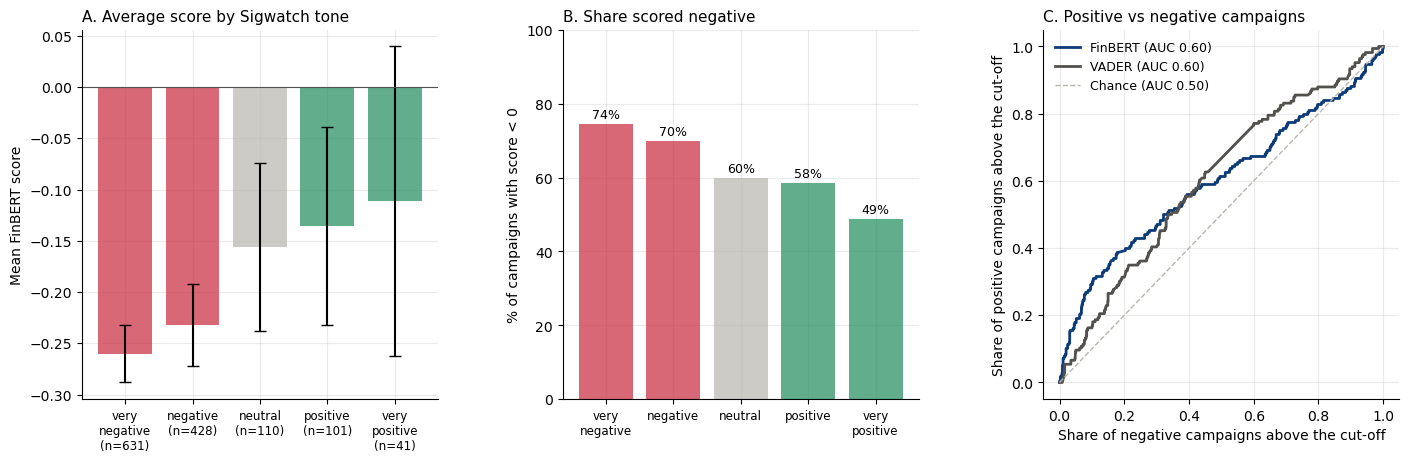

81 strong disagreements
[Examples omitted from the public version: Sigwatch campaign text is licensed and cannot be redistributed.]


In [32]:

# --- Prepare: keep campaigns with both scores, and put Sigwatch's mean tone into 5 groups ---
v = camp.dropna(subset=["nlp_score", "sentiment"]).copy()
v["tone"] = pd.cut(v["sentiment"], [-2.01, -1.5, -0.5, 0.5, 1.5, 2.01],
                   labels=["very negative", "negative", "neutral", "positive", "very positive"])

# --- 1. Rank correlation between each text score and Sigwatch's tone ---
for col in ["nlp_score", "vader"]:
    d = v.dropna(subset=[col])                                  # VADER can be missing for very short texts
    r, p = spearmanr(d[col], d["sentiment"])
    print(f"Spearman {col} vs Sigwatch tone: {r:.2f} (p = {p:.3g})")

# --- 2. AUC: probability that a random positive campaign scores higher than a random negative one (0.5 = chance, 1 = perfect) ---
pos, neg = v[v["sentiment"] > 0], v[v["sentiment"] < 0]
for col in ["nlp_score", "vader"]:
    a, b = pos[col].dropna(), neg[col].dropna()                 # drop missing scores before the test
    u = mannwhitneyu(a, b).statistic
    print(f"AUC {col} (positive vs negative campaigns): {u / (len(a) * len(b)):.2f}  [{len(a)} pos, {len(b)} neg]")

# --- 3. Sign agreement, compared with a model that always says 'negative' ---
nz = v[v["sentiment"] != 0]
print(f"Sign agreement: {(np.sign(nz['nlp_score']) == np.sign(nz['sentiment'])).mean():.1%} "
      f"(always-negative baseline: {(nz['sentiment'] < 0).mean():.1%})")

# --- 4. Average score by Sigwatch tone group (should rise from 'very negative' to 'very positive') ---
print(v.groupby("tone", observed=True)["nlp_score"].agg(["count", "mean", "median"]).round(3))

# --- Figure: 3 panels ---
C = globals().get("C", {"neg": "#c8283c", "neu": "#b7b5ad", "pos": "#1f8a5b", "navy": "#0d3b78", "grey": "#52514e"})   # palette of Figure 1
order = ["very negative", "negative", "neutral", "positive", "very positive"]
cols = [C["neg"], C["neg"], C["neu"], C["pos"], C["pos"]]       # red = negative, grey = neutral, green = positive

fig, axes = plt.subplots(1, 3, figsize=(17, 4.8), gridspec_kw={"wspace": 0.35})

# A. Mean score by Sigwatch tone, with 95% confidence interval and group size
ax = axes[0]
g = v.groupby("tone", observed=True)["nlp_score"].agg(["mean", "std", "count"]).reindex(order)
ci = 1.96 * g["std"] / np.sqrt(g["count"])                      # 95% confidence interval of the mean
ax.bar(range(5), g["mean"], yerr=ci, color=cols, alpha=0.7, capsize=4)
ax.axhline(0, color=C["grey"], lw=0.8)
ax.set_xticks(range(5)); ax.set_xticklabels([f"{t.replace(' ', chr(10))}\n(n={int(g.loc[t, 'count'])})" for t in order], fontsize=8.5)   # 'very negative' on two lines
ax.set_ylabel("Mean FinBERT score"); ax.set_title("A. Average score by Sigwatch tone", loc="left", fontsize=11)

# B. Share of campaigns that FinBERT scores as negative, by Sigwatch tone
ax = axes[1]
share = v.assign(fb_neg=v["nlp_score"] < 0).groupby("tone", observed=True)["fb_neg"].mean().reindex(order)
ax.bar(range(5), 100 * share, color=cols, alpha=0.7)
for i, s in enumerate(share):
    ax.text(i, 100 * s + 1.5, f"{100 * s:.0f}%", ha="center", fontsize=9)     # label each bar
ax.set_xticks(range(5)); ax.set_xticklabels([t.replace(" ", "\n") for t in order], fontsize=8.5)
ax.set_ylim(0, 100); ax.set_ylabel("% of campaigns with score < 0")
ax.set_title("B. Share scored negative", loc="left", fontsize=11)

# C. ROC curve: how well does the score separate positive from negative campaigns?
def roc(pos_s, neg_s):
    thr = np.sort(np.unique(np.r_[pos_s, neg_s]))[::-1]         # every possible cut-off, from high to low
    tpr = [(pos_s >= t).mean() for t in thr]                     # share of positive campaigns above the cut-off
    fpr = [(neg_s >= t).mean() for t in thr]                     # share of negative campaigns above the cut-off
    return np.r_[0, fpr, 1], np.r_[0, tpr, 1]

ax = axes[2]
for col, label, colour in [("nlp_score", "FinBERT", C["navy"]), ("vader", "VADER", C["grey"])]:
    d = v.dropna(subset=[col])                                   # VADER can be missing for very short texts
    p_s, n_s = d.loc[d["sentiment"] > 0, col].to_numpy(), d.loc[d["sentiment"] < 0, col].to_numpy()
    x, y = roc(p_s, n_s)
    ax.plot(x, y, color=colour, lw=2, label=f"{label} (AUC {np.sum(np.diff(x) * (y[1:] + y[:-1]) / 2):.2f})")   # AUC = area under the curve
ax.plot([0, 1], [0, 1], color=C["neu"], ls="--", lw=1, label="Chance (AUC 0.50)")
ax.set_xlabel("Share of negative campaigns above the cut-off"); ax.set_ylabel("Share of positive campaigns above the cut-off")
ax.set_title("C. Positive vs negative campaigns", loc="left", fontsize=11); ax.legend(frameon=False, fontsize=9)

for ax in axes:                                                  # common style for the three panels
    ax.spines[["top", "right"]].set_visible(False); ax.grid(alpha=0.25)
    ax.set_axisbelow(True)
plt.show()

# --- Read the biggest disagreements by hand: they show where the model fails ---
dis = v[(v["sentiment"] <= -1) & (v["nlp_score"] > 0.3) | (v["sentiment"] >= 1) & (v["nlp_score"] < -0.3)]
print(f"{len(dis)} strong disagreements")
for _, r in dis.head(5).iterrows():
    print(f"\n[{r['ngo']}] Sigwatch {r['sentiment']:+.1f}, score {r['nlp_score']:+.2f}\n{r['report'][:400]}")

**Comment:** The FinBERT score points in the right direction but is weak. It is positively correlated with Sigwatch's tone (Spearman 0.10, p < 0.001; VADER 0.13), and the average score rises from −0.26 for very negative campaigns to −0.11 for very positive ones, but the confidence intervals of neighbouring groups overlap (panel A). It separates positive from negative campaigns only slightly better than chance (AUC 0.60 for both FinBERT and VADER), and it scores 58% of positive and 49% of very positive campaigns as negative (panel B). Sign agreement (68.7%) is below the always-negative baseline (86.5%), so the score is not usable as a sign classifier.

The disagreements show why. Sigwatch codes the bank's stance relative to the NGO's demand, while FinBERT reads the wording. A campaign that praises banks for ending coal financing contains words such as "coal mining" and "cease their investment" and scores negative (Rainforest Action Network: Sigwatch +1, score −0.74), whereas a criticism of a sustainability award reads as positive (Deutsche Bank award: Sigwatch −2, score +0.36). We therefore keep Sigwatch's tone as the main sentiment variable and use the NLP score only as a continuous complement and robustness check.

**Step 1: test the links.** 

Each campaign has up to five source links (`link1` to `link5`). We list all of them, remove duplicates and test each one with a web request (32 in parallel). Results are saved in `link_check.csv`, so a rerun does not start from zero. For a first test, set `LIMIT = 50`; then set it back to None for the full run.

In [33]:
# --- List all links: one row per (campaign, link) ---
links = (camp[["uid_archive", "date"] + [f"link{i}" for i in range(1, 6)]]
         .melt(id_vars=["uid_archive", "date"], var_name="slot", value_name="url"))   # link1..link5 -> one column
links["url"] = links["url"].fillna("").astype(str).str.strip()
links = links[links["url"].str.len() > 0].copy()                                    # drop empty slots
links.loc[~links["url"].str.match(r"https?://", case=False), "url"] = "http://" + links["url"]   # add a scheme when missing
print(f"{len(links):,} links, {links['url'].nunique():,} distinct URLs, {links['uid_archive'].nunique():,} campaigns")

# --- Test one URL ---
HEADERS = {"User-Agent": "Mozilla/5.0 (academic project, link check)"}              # some sites refuse requests without a browser-like name

def check(url):
    # Try HEAD first (light: no page download); if the server refuses, try GET. Returns (status, final URL, error)
    for method in ("HEAD", "GET"):
        try:
            r = requests.request(method, url, headers=HEADERS, timeout=(4, 6), allow_redirects=True, stream=True)   # 4 s to connect, 6 s to answer
            code, final = r.status_code, r.url
            r.close()
            if code < 400:
                return code, final, ""                           # the page answers
        except requests.exceptions.RequestException as e:
            err = type(e).__name__                               # Timeout, ConnectionError (dead domain), SSLError ...
            if method == "GET":
                return None, "", err                             # both methods failed
    return code, final, ""                                       # answered, but with an error code (404, 403, ...)

# --- Cache: do not test twice ---
link_cache = OUT / "link_check.csv"
checked = (pd.read_csv(link_cache) if link_cache.exists()
           else pd.DataFrame(columns=["url", "status", "final_url", "error"]))      # results of a previous run, if any
todo_urls = [u for u in links["url"].unique() if u not in set(checked["url"])]       # only the URLs not yet tested
LIMIT = None                                                    # put e.g. 50 here for a first test run
todo_urls = todo_urls[:LIMIT]
print(f"{len(checked):,} already checked, {len(todo_urls):,} to check")

# --- Progress bar (tqdm); falls back to a printed line every 100 links if tqdm is not installed ---
# pip install tqdm
try:
    from tqdm.auto import tqdm
    bar = tqdm(total=len(todo_urls), desc="Links checked", unit="link")
except ImportError:
    bar = None
count = {"working": 0, "broken (404/410)": 0, "blocked (401/403/429)": 0, "no answer": 0, "other error": 0}   # live tally

def tally(code):
    # Put one result in a rough category, only to show it live in the progress bar
    if code is None or pd.isna(code):
        return "no answer"
    if code < 400:
        return "working"
    if code in (404, 410):
        return "broken (404/410)"
    if code in (401, 403, 429):
        return "blocked (401/403/429)"
    return "other error"

# --- Test all new URLs, 32 at a time, with a checkpoint every 100 links ---
results, start = [], time.time()
with ThreadPoolExecutor(max_workers=32) as ex:
    futures = {ex.submit(check, u): u for u in todo_urls}          # start all the tests
    for n, fut in enumerate(as_completed(futures), 1):             # handle each result as soon as it arrives
        res = fut.result()
        results.append((futures[fut], *res))
        count[tally(res[0])] += 1
        if bar is not None:
            bar.update(1)
            bar.set_postfix({"ok": count["working"], "broken": count["broken (404/410)"],
                             "blocked": count["blocked (401/403/429)"], "no answer": count["no answer"]})
        elif n % 100 == 0:
            print(f"  {n}/{len(futures)} checked ({time.time() - start:.0f}s) {count}")
        if n % 100 == 0 or n == len(futures):
            # checkpoint: save everything done so far, so an interruption keeps the work
            (pd.concat([checked, pd.DataFrame(results, columns=checked.columns)], ignore_index=True)
               .drop_duplicates("url", keep="last").to_csv(link_cache, index=False))
if bar is not None:
    bar.close()

# --- Final save ---
checked = pd.concat([checked, pd.DataFrame(results, columns=checked.columns)], ignore_index=True).drop_duplicates("url", keep="last")
checked.to_csv(link_cache, index=False)
print(f"Done in {time.time() - start:.0f}s: {count}")

2,188 links, 2,175 distinct URLs, 1,310 campaigns


2,175 already checked, 0 to check


Links checked: 0link [00:00, ?link/s]

Done in 0s: {'working': 0, 'broken (404/410)': 0, 'blocked (401/403/429)': 0, 'no answer': 0, 'other error': 0}


**Comment:** The campaigns list 2,188 source links, of which 2,175 are distinct URLs, spread over 1,310 of the 1,311 campaigns (one campaign has no link). We tested each URL once with a web request (HEAD, then GET if the server refuses). A link counts as working if the server answers with a code below 400; the results are saved in `link_check.csv`, so the test does not have to be run again. The test was run on the day of the analysis, so it measures link rot today, not when the campaigns were published.

**Step 2: classify and summarise.** 

Each result becomes one of: ok, redirected to the home page (the page was probably removed), gone (404/410), blocked (403/429: the site refuses scripts, so we cannot tell), or error (dead domain, timeout). We count "blocked" as working, so the share of dead links is a lower bound. We then look at the share of working links by year and by domain, and build per-campaign variables.

In [34]:
# --- Classify one result ---
def classify(row):
    s = row["status"]
    if pd.isna(s):
        return "error (dead domain, timeout, SSL)"               # no answer at all
    s = int(s)
    # a redirect to the site's home page means that the page was removed, whatever the final status code
    o, f = urlparse(str(row["url"])), urlparse(str(row["final_url"]))
    if f.path in ("", "/") and o.path not in ("", "/"):
        return "redirected to home page"
    if s < 400:
        return "ok"
    if s in (404, 410):
        return "gone (404/410)"                                  # page removed
    if s in (401, 403, 429, 999):
        return "blocked (cannot tell)"                           # bot protection or login: the page may well exist
    return "error (other 4xx/5xx)"

checked["link_status"] = checked.apply(classify, axis=1)
links = links.merge(checked[["url", "link_status"]], on="url", how="left")
links["link_ok"] = links["link_status"].isin(["ok", "blocked (cannot tell)"])   # 'blocked' counts as alive: we cannot prove it is dead

# --- Summaries: overall, by year, by domain ---
print(links["link_status"].value_counts(normalize=True).round(3))
print("\nShare of links that work, by year of the campaign:")
print(links.groupby(links["date"].dt.year)["link_ok"].mean().round(3))      # old links should work less often
links["domain"] = links["url"].map(lambda u: urlparse(u).netloc.replace("www.", ""))
print("\nMost frequent domains and their share of links that work:")
print(links.groupby("domain")["link_ok"].agg(["size", "mean"]).sort_values("size", ascending=False).head(10).round(2))

# --- One row per campaign: number of links, share that work, and at least one working link ---
per_camp = (links.groupby("uid_archive")
            .agg(n_links=("url", "size"), share_links_ok=("link_ok", "mean"), any_link_ok=("link_ok", "max"))
            .reset_index())
camp = camp.drop(columns=["n_links", "share_links_ok", "any_link_ok"], errors="ignore")   # remove the copies from a previous run
camp = camp.merge(per_camp, on="uid_archive", how="left", validate="1:1")
print(f"\n{camp['any_link_ok'].mean():.1%} of campaigns keep at least one working link")

link_status
gone (404/410)                       0.419
ok                                   0.393
blocked (cannot tell)                0.071
error (dead domain, timeout, SSL)    0.068
redirected to home page              0.040
error (other 4xx/5xx)                0.009
Name: proportion, dtype: float64

Share of links that work, by year of the campaign:
date
2010    0.337
2011    0.324
2012    0.327
2013    0.344
2014    0.387
2015    0.491
2016    0.590
2017    0.562
2018    0.671
Name: link_ok, dtype: float64

Most frequent domains and their share of links that work:
                       size  mean
domain                           
ran.org                  89  0.52
amisdelaterre.org        87  0.28
banktrack.org            71  0.97
greenpeace.org           55  0.95
wdm.org.uk               44  0.00
uspirg.org               39  0.77
eerlijkebankwijzer.nl    35  0.00
corporateeurope.org      35  0.94
globalwitness.org        32  0.19
france.attac.org         31  0.94

54.7% of campaig

**Spot-check.** We print three links from the suspicious domains, with the server's answer, to confirm that home-page redirects and refusals are classified correctly.

In [35]:
# Spot-check: a few links of the suspicious domains, with what the server answered
pd.set_option("display.max_colwidth", 90)
for d in ["eerlijkebankwijzer.nl", "wdm.org.uk", "globalwitness.org"]:
    print("\n", d)
    print(links[links["domain"] == d]
          .merge(checked[["url", "status", "final_url", "error"]], on="url")
          .head(3)[["url", "link_status", "status", "final_url", "error"]].to_string(index=False))

[Output omitted from the public version: lists individual Sigwatch source links.]


**Comment:** Of 2,175 distinct URLs, 39% still work, 7% are blocked (we cannot tell and count them as working), 4% redirect to the home page of the site (the page was removed), 42% are gone (404/410) and 8% give an error or no answer. Link rot rises with age: 32-39% of links work for campaigns of 2010-2014, against 49% for 2015 and 56-67% for 2016-2018. It also depends on the site: banktrack.org and corporateeurope.org keep 94-97% of their links, while eerlijkebankwijzer.nl and wdm.org.uk (now Global Justice Now, which redirects to its home page) keep none, and Global Witness keeps 19%, which points to site redesigns. 54.7% of campaigns still have at least one working link, so the `report` text, not the link, is the reliable source for the content of a campaign.

**Limits:** "blocked" links (403/429) are counted as working because the site may refuse scripts and still have the page; slow sites (more than 6 seconds) are counted as errors; and a page that answers "ok" may still show different content from the original.

**Read the linked pages.** Sigwatch's `report` is a short summary (a few lines), while the link leads to the full article or press release, which carries much more text and tone. For each campaign we take the first link that works and extract the main text of the page (without menus or cookie banners). Pages that are PDFs or have almost no text are skipped. Pages are saved in `link_texts.csv`, so a rerun does not download them again. For a first test, set `LIMIT_PAGES = 30`; then set it back to `None`.

In [36]:
# pip install trafilatura   (extracts the main text of a web page and removes menus, ads, cookie banners)
import trafilatura

# --- Which page to read for each campaign: the first link that works ("ok"), in the order link1 ... link5 ---
good = (links[links["link_status"] == "ok"]
        .sort_values(["uid_archive", "slot"])
        .drop_duplicates("uid_archive")[["uid_archive", "url"]])
print(f"{len(good):,} campaigns have at least one working link")

# --- Download one page and extract its text ---
def fetch_text(url):
    try:
        r = requests.get(url, headers=HEADERS, timeout=(4, 10), stream=True)
        ctype = r.headers.get("Content-Type", "").lower()
        if "html" not in ctype:                                   # PDFs, images ... are skipped
            r.close()
            return "", "not html (" + ctype.split(";")[0] + ")"
        raw = r.raw.read(2_000_000, decode_content=True)          # at most 2 MB per page
        r.close()
        return trafilatura.extract(raw, include_comments=False, include_tables=False) or "", ""   # main text only
    except Exception as e:
        return "", type(e).__name__

# --- Cache: do not download twice ---
text_cache = OUT / "link_texts.csv"
got = (pd.read_csv(text_cache, dtype={"uid_archive": str}).fillna("") if text_cache.exists()
       else pd.DataFrame(columns=["uid_archive", "url", "text", "error"]))           # pages from a previous run, if any
todo_pages = good[~good["uid_archive"].isin(got["uid_archive"])]
LIMIT_PAGES = None                                                 # put e.g. 30 here for a first test run
todo_pages = todo_pages.iloc[:LIMIT_PAGES]
print(f"{len(got):,} already downloaded, {len(todo_pages):,} to download")

# --- Download all new pages, 16 at a time, with a progress bar and a checkpoint every 50 pages ---
try:
    from tqdm.auto import tqdm
    bar = tqdm(total=len(todo_pages), desc="Pages downloaded", unit="page")
except ImportError:
    bar = None
rows = []
with ThreadPoolExecutor(max_workers=16) as ex:
    futures = {ex.submit(fetch_text, u): (uid, u) for uid, u in zip(todo_pages["uid_archive"], todo_pages["url"])}
    for n, fut in enumerate(as_completed(futures), 1):
        uid, u = futures[fut]
        text, err = fut.result()
        rows.append((uid, u, text, err))
        if bar is not None:
            bar.update(1)
        if n % 50 == 0 or n == len(futures):
            pd.concat([got, pd.DataFrame(rows, columns=got.columns)], ignore_index=True).to_csv(text_cache, index=False)   # checkpoint
if bar is not None:
    bar.close()
got = pd.concat([got, pd.DataFrame(rows, columns=got.columns)], ignore_index=True).drop_duplicates("uid_archive", keep="last")
got.to_csv(text_cache, index=False)

got["n_words"] = got["text"].str.split().str.len().fillna(0)
print(f"{(got['n_words'] >= 80).sum():,} pages with at least 80 words of text (usable)")
print(got.loc[got["n_words"] < 80, "error"].replace("", "page too short or empty").value_counts().head(6))

624 campaigns have at least one working link
150 already downloaded, 474 to download


Pages downloaded:   0%|          | 0/474 [00:00<?, ?page/s]

447 pages with at least 80 words of text (usable)
error
page too short or empty       117
not html (application/pdf)     51
ConnectTimeout                  4
ConnectionError                 1
ProtocolError                   1
not html (image/jpeg)           1
Name: count, dtype: int64


**Comment:** 447 pages gave at least 80 words of text. The others failed because the page was empty or had too little text (117, usually pages built with JavaScript or cookie walls), was a PDF (51), or was an image or gave a connection error (a handful: 7). So we read a page for 34% of the campaigns, mostly the more recent ones.

**Score the pages.** We keep the pages with at least 80 words (a cookie banner or an error page has almost no text) and score them with the same FinBERT function as for the reports: `P(positive) - P(negative)`. Scores are saved in `link_finbert_scores.csv`. The page score becomes a second variable, `nlp_score_link`, next to the report score `nlp_score`.

In [37]:
# --- Keep usable pages only (a cookie banner or an error page has almost no text) ---
MIN_WORDS = 80
pages = got[got["n_words"] >= MIN_WORDS][["uid_archive", "text", "n_words"]]

# --- Cache: do not score twice (same logic as for the reports; finbert_probs comes from the FinBERT cell above) ---
lk_cache = OUT / "link_finbert_scores.csv"
lk_done = (pd.read_csv(lk_cache, dtype={"uid_archive": str}) if lk_cache.exists()
           else pd.DataFrame(columns=["uid_archive", "lk_pos", "lk_neg", "lk_neu"]))
lk_todo = pages[~pages["uid_archive"].isin(lk_done["uid_archive"])]
print(f"{len(lk_done):,} pages already scored, {len(lk_todo):,} to score")

rows = []
for n, (uid, text) in enumerate(zip(lk_todo["uid_archive"], lk_todo["text"]), 1):
    rows.append((uid, *finbert_probs(text)))                        # P(positive), P(negative), P(neutral) of the page
    if n % 50 == 0:
        print(f"  {n}/{len(lk_todo)}")
        pd.concat([lk_done, pd.DataFrame(rows, columns=lk_done.columns)], ignore_index=True).to_csv(lk_cache, index=False)   # checkpoint
lk_done = pd.concat([lk_done, pd.DataFrame(rows, columns=lk_done.columns)], ignore_index=True)
lk_done[["lk_pos", "lk_neg", "lk_neu"]] = lk_done[["lk_pos", "lk_neg", "lk_neu"]].astype(float)    # make sure the scores are numbers
lk_done.to_csv(lk_cache, index=False)

# --- Attach to the campaigns; the page score is P(positive) - P(negative), like the report score ---
camp = camp.drop(columns=["lk_pos", "lk_neg", "lk_neu", "nlp_score_link", "link_words"], errors="ignore")   # remove old copies on a rerun
camp = (camp.merge(lk_done, on="uid_archive", how="left", validate="1:1")
            .merge(pages[["uid_archive", "n_words"]].rename(columns={"n_words": "link_words"}), on="uid_archive", how="left", validate="1:1"))
camp["nlp_score_link"] = camp["lk_pos"] - camp["lk_neg"]
print(f"{camp['nlp_score_link'].notna().sum():,} campaigns with a page score "
      f"({camp['nlp_score_link'].notna().mean():.0%}); median page length {camp['link_words'].median():.0f} words "
      f"vs {camp['report'].str.split().str.len().median():.0f} for the report")

0 pages already scored, 447 to score


  50/447


  100/447


  150/447


  200/447


  250/447


  300/447


  350/447


  400/447


447 campaigns with a page score (34%); median page length 535 words vs 61 for the report


**Comment:** The pages are much longer than the reports (median 535 words against 61). FinBERT reads at most 6 chunks of 510 tokens per page, so very long pages are cut. 34% of campaigns now have a page score.

**Does the full article give a better score than the report?** We compare the two scores on the same campaigns (those with both), so that the comparison is fair: rank correlation with Sigwatch's tone, AUC for positive against negative campaigns, and ROC curves. If the page score is clearly better, the longer text carries more information about the campaign.

447 campaigns with both scores (46 positive, 384 negative)
AUC report:      0.60  [95% CI 0.51, 0.69]
AUC linked page: 0.53  [95% CI 0.44, 0.61]
Difference (page - report): -0.07  [95% CI -0.19, +0.05]  -> a CI that contains 0 means no clear difference
Spearman with Sigwatch tone: report 0.10, page -0.06; correlation between the two scores 0.05


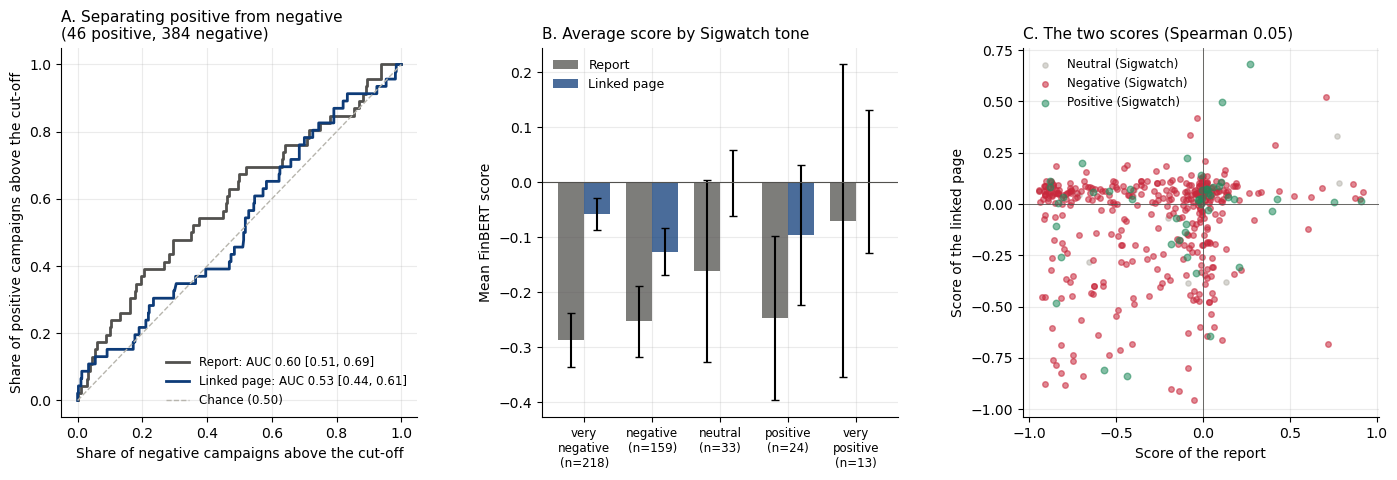

In [38]:
from scipy.stats import spearmanr

# --- Same campaigns for both scores, so that the comparison is fair ---
both = camp.dropna(subset=["nlp_score", "nlp_score_link", "sentiment"]).copy()
both["tone"] = pd.cut(both["sentiment"], [-2.01, -1.5, -0.5, 0.5, 1.5, 2.01],
                      labels=["very negative", "negative", "neutral", "positive", "very positive"])
pn = both[both["sentiment"] != 0].copy()                           # positive and negative campaigns only (for the AUC)
y = (pn["sentiment"] > 0).to_numpy()                               # True = positive campaign
s_rep, s_lnk = pn["nlp_score"].to_numpy(), pn["nlp_score_link"].to_numpy()
print(f"{len(both):,} campaigns with both scores ({y.sum()} positive, {(~y).sum()} negative)")

# --- AUC (probability that a random positive campaign scores above a random negative one) ---
def auc(s, y):
    p, n = s[y], np.sort(s[~y])
    lo, hi = np.searchsorted(n, p, "left"), np.searchsorted(n, p, "right")      # ties count for 1/2
    return (lo.sum() + 0.5 * (hi - lo).sum()) / (len(p) * len(n))

# --- Bootstrap: redraw the campaigns 1,000 times to get a 95% interval for each AUC and for their difference ---
rng = np.random.default_rng(0)
boot = []
for _ in range(1000):
    b = rng.integers(0, len(pn), len(pn))
    if y[b].sum() == 0 or (~y[b]).sum() == 0:
        continue
    boot.append((auc(s_rep[b], y[b]), auc(s_lnk[b], y[b])))
boot = np.array(boot)
ci_rep, ci_lnk = np.percentile(boot[:, 0], [2.5, 97.5]), np.percentile(boot[:, 1], [2.5, 97.5])
ci_diff = np.percentile(boot[:, 1] - boot[:, 0], [2.5, 97.5])
a_rep, a_lnk = auc(s_rep, y), auc(s_lnk, y)
print(f"AUC report:      {a_rep:.2f}  [95% CI {ci_rep[0]:.2f}, {ci_rep[1]:.2f}]")
print(f"AUC linked page: {a_lnk:.2f}  [95% CI {ci_lnk[0]:.2f}, {ci_lnk[1]:.2f}]")
print(f"Difference (page - report): {a_lnk - a_rep:+.2f}  [95% CI {ci_diff[0]:+.2f}, {ci_diff[1]:+.2f}]  -> a CI that contains 0 means no clear difference")
print(f"Spearman with Sigwatch tone: report {spearmanr(both['nlp_score'], both['sentiment'])[0]:.2f}, "
      f"page {spearmanr(both['nlp_score_link'], both['sentiment'])[0]:.2f}; "
      f"correlation between the two scores {spearmanr(both['nlp_score'], both['nlp_score_link'])[0]:.2f}")

# --- Figure: 3 panels ---
C = globals().get("C", {"neg": "#c8283c", "neu": "#b7b5ad", "pos": "#1f8a5b", "navy": "#0d3b78", "grey": "#52514e"})
order = ["very negative", "negative", "neutral", "positive", "very positive"]
fig, axes = plt.subplots(1, 3, figsize=(17, 4.8), gridspec_kw={"wspace": 0.35})

# A. ROC curves, with the bootstrap interval of each AUC in the legend
def roc(s, y):
    thr = np.sort(np.unique(s))[::-1]                              # every cut-off, from high to low
    return (np.r_[0, [(s[~y] >= t).mean() for t in thr], 1],       # share of negative campaigns above the cut-off
            np.r_[0, [(s[y] >= t).mean() for t in thr], 1])        # share of positive campaigns above the cut-off
ax = axes[0]
for s, lab, a, ci, colour in [(s_rep, "Report", a_rep, ci_rep, C["grey"]), (s_lnk, "Linked page", a_lnk, ci_lnk, C["navy"])]:
    x_, y_ = roc(s, y)
    ax.plot(x_, y_, color=colour, lw=2, label=f"{lab}: AUC {a:.2f} [{ci[0]:.2f}, {ci[1]:.2f}]")
ax.plot([0, 1], [0, 1], color=C["neu"], ls="--", lw=1, label="Chance (0.50)")
ax.set_xlabel("Share of negative campaigns above the cut-off"); ax.set_ylabel("Share of positive campaigns above the cut-off")
ax.set_title(f"A. Separating positive from negative\n({y.sum()} positive, {(~y).sum()} negative)", loc="left", fontsize=11)
ax.legend(frameon=False, fontsize=8.5, loc="lower right")

# B. Mean score by Sigwatch tone, for both text sources, with 95% interval
ax = axes[1]
w = 0.38
for k, (col, lab, colour) in enumerate([("nlp_score", "Report", C["grey"]), ("nlp_score_link", "Linked page", C["navy"])]):
    g = both.groupby("tone", observed=True)[col].agg(["mean", "std", "count"]).reindex(order)
    ax.bar(np.arange(5) + (k - 0.5) * w, g["mean"], w, yerr=1.96 * g["std"] / np.sqrt(g["count"]),
           color=colour, alpha=0.75, capsize=3, label=lab)
n_by_tone = both["tone"].value_counts().reindex(order)
ax.set_xticks(range(5)); ax.set_xticklabels([f"{t.replace(' ', chr(10))}\n(n={n_by_tone[t]})" for t in order], fontsize=8.5)
ax.axhline(0, color=C["grey"], lw=0.8); ax.set_ylabel("Mean FinBERT score")
ax.set_title("B. Average score by Sigwatch tone", loc="left", fontsize=11); ax.legend(frameon=False, fontsize=9)

# C. Report score against page score, one point per campaign
ax = axes[2]
for lab, mask, colour, size in [("Neutral", both["sentiment"] == 0, C["neu"], 14),
                                ("Negative", both["sentiment"] < 0, C["neg"], 16),
                                ("Positive", both["sentiment"] > 0, C["pos"], 22)]:
    ax.scatter(both.loc[mask, "nlp_score"], both.loc[mask, "nlp_score_link"], s=size, color=colour, alpha=0.55, label=f"{lab} (Sigwatch)")
ax.axhline(0, color=C["grey"], lw=0.6); ax.axvline(0, color=C["grey"], lw=0.6)
ax.set_xlabel("Score of the report"); ax.set_ylabel("Score of the linked page")
ax.set_title(f"C. The two scores (Spearman {spearmanr(both['nlp_score'], both['nlp_score_link'])[0]:.2f})", loc="left", fontsize=11)
ax.legend(frameon=False, fontsize=8.5)

for ax in axes:
    ax.spines[["top", "right"]].set_visible(False); ax.grid(alpha=0.25); ax.set_axisbelow(True)
plt.show()

**Comment:** On the 447 campaigns with both scores, the linked page does not do better than the report. 

- Panel A: the AUC for positive against negative campaigns is 0.53 [0.44, 0.61] for the page, an interval that contains chance (0.50), against 0.60 [0.51, 0.69] for the report. The difference (page − report) is −0.07 with a 95% CI of −0.19 to +0.05, which contains 0, so the gap is small. The rank correlation of the page score with Sigwatch's tone is even slightly negative (−0.06, against 0.10 for the report). 
- Panel B: the report score rises from −0.29 for very negative campaigns to −0.07 for very positive ones, while the page score shows no clear pattern (between −0.13 and 0.00). 
- Panel C: the two scores are unrelated (Spearman 0.05): most page scores sit close to 0, as if FinBERT read long articles as neutral, while many reports are scored very negative. A likely reason is that a long article mixes many topics, so the part about the bank is diluted when the whole text is averaged, whereas the report is a short summary of what the NGO claimed. The sample is small and selected: only 46 campaigns have a positive average tone (the AUC uses this split; the five rounded groups of panel B show 37 positive and very positive), and only campaigns whose link still works are included, mostly recent ones. The comparison therefore holds for these campaigns only. With more time we would score only the sentences that mention the bank, or ask a model whether the text criticises or praises the bank.

**Merge back to bank-days and save.** A bank-day in `events_banks.csv` can rest on several campaigns, listed in `uids` separated by `;`. We split `uids` into one row per (bank-day, campaign), attach the campaign scores, and average them back to one row per bank-day (the mean score, and the most negative one). The result has exactly the same rows as `events_banks.csv`, so C and Alissa can join it on `ds_name` and `date`. We save new files and do not overwrite the originals.

In [39]:
# --- Read the bank-day file written in A4 (uids stays as text) ---
ev = pd.read_csv(OUT / "events_banks.csv", parse_dates=["date"], dtype={"uids": str})

# --- One row per (bank-day, campaign): split the ';'-separated uids and give each campaign its own row ---
m = (ev[["ds_name", "date", "uids"]]
     .assign(uid_archive=ev["uids"].str.split(";"))
     .explode("uid_archive"))
m = m.merge(camp[["uid_archive", "nlp_score", "nlp_score_link", "vader", "any_link_ok"]],
            on="uid_archive", how="left", validate="m:1")        # attach the campaign scores

# --- Back to one row per bank-day ---
agg = (m.groupby(["ds_name", "date"], as_index=False)
         .agg(nlp_score=("nlp_score", "mean"),                   # average over the campaigns of that bank-day
              nlp_score_min=("nlp_score", "min"),                # the most negative campaign of the day
              nlp_score_link=("nlp_score_link", "mean"),          # score of the linked page (only where a page was read)
              vader=("vader", "mean"),
              any_link_ok=("any_link_ok", "max")))               # at least one campaign with a working link
ev_nlp = ev.merge(agg, on=["ds_name", "date"], how="left", validate="1:1")
assert len(ev_nlp) == len(ev), "the merge must not add or drop bank-days"      # safety check
print(f"{ev_nlp['nlp_score'].notna().mean():.1%} of bank-days have an NLP score, "
      f"{ev_nlp['nlp_score_link'].notna().mean():.1%} have a linked-page score")

# --- A flag for the splits in Task 6: negative text (score < 0) or not ---
ev_nlp["nlp_negative"] = (ev_nlp["nlp_score"] < 0).astype(int)

# --- Save the two output files ---
camp.to_csv(OUT / "campaigns_banks_nlp.csv", index=False)        # per campaign: text, scores, links
ev_nlp.to_csv(OUT / "events_banks_nlp.csv", index=False)         # per bank-day: same rows as events_banks.csv, plus the NLP columns
print("saved:", OUT / "campaigns_banks_nlp.csv", "|", OUT / "events_banks_nlp.csv")

100.0% of bank-days have an NLP score, 39.0% have a linked-page score
saved: data\handoff\campaigns_banks_nlp.csv | data\handoff\events_banks_nlp.csv


**Conclusion (NLP):** FinBERT scores about 70% of campaigns as negative. The score agrees only weakly with Sigwatch's tone: Spearman 0.10, AUC 0.60 for positive against negative campaigns (VADER: 0.13 and 0.60). The average score rises from −0.26 for very negative campaigns to −0.11 for very positive ones, but the sign agrees with Sigwatch in only 68.7% of campaigns, below an "always negative" rule (86.5%). Reading the full linked article does not help: the AUC of the page score is 0.53 against 0.60 for the report, and the difference (−0.07, 95% CI −0.19 to +0.05) is not clearly different from 0. We therefore keep Sigwatch's tone as the main sentiment variable, use the report score `nlp_score` only as a continuous complement and robustness check, and save the page score as `nlp_score_link`. 39% of the links still work (32-34% for campaigns in 2010-2012, 56-67% for 2016-2018) and 54.7% of campaigns keep at least one working link, so the `report` text, not the link, is the reliable source. **Limits:** FinBERT is trained on market news, and NGO reports criticise a bank rather than report bad news for its stock; mass events (more than 10 firms) describe many banks at once, so their text is not bank-specific; "blocked" links are counted as working, so the share of dead links is a lower bound.

---
# Part B: Market data and betas
Build the daily panel (returns from RI, Fama-French factors, risk-free rate, currencies), then estimate rolling CAPM and Fama-French betas (task #4), which give each bank's expected return on each day.

**Handoff to C:** `handoff/panel_returns.csv`, `handoff/betas_daily.csv`.

## B1. Daily panel
We build one daily panel with returns for the 59 banks in our events, plus the Fama-French factors and the risk-free rate. US banks use the North America factors and all other banks the Europe factors. We keep only banks that appear in the campaign data.

In [39]:
# Total-return indices of all banks (main file + Swiss/Nordic file), same bank key as the events file
def load_ri(file):
    sheets = pd.read_excel(DATA / "banks_data_bocconi" / file, sheet_name=None)
    sheets.pop("REQUEST_TABLE")
    return pd.concat([v.rename(columns={"Name": "date"}).melt(id_vars="date", var_name="bank", value_name="ri").assign(country=k)
                      for k, v in sheets.items()], ignore_index=True)

ri = pd.concat([load_ri("banks_ri.xlsm"), load_ri("scandinavian_banks_ri.xlsm")], ignore_index=True)
ri["date"] = pd.to_datetime(ri["date"], errors="coerce")
ri["ds_name"] = ri["bank"].str.rsplit(" - ", n=1).str[0].str.strip().str.lower()
ri = ri[ri["ds_name"].isin(events["ds_name"])].dropna(subset=["date", "ri"]).sort_values(["ds_name", "date"]).drop_duplicates(["ds_name", "date"])

In [40]:
# Daily returns; drop impossible moves (> +/-100% in a day = data errors) and flag very large ones (> 50%)
ri["ret"] = ri.groupby("ds_name")["ri"].pct_change()
ri = ri.dropna(subset=["ret"])
ri["ret"] = ri["ret"].where(ri["ret"].abs() <= 1)
ri["big"] = ri["ret"].abs() > 0.5

**Risk-free rate:** the `RF` column of the factor files is rounded to 0.01% a day, which makes it a coarse measure of the daily risk-free rate. We use the daily 4-week T-bill from `risk_free_rate.xlsm`, the closest match to the 1-month bill behind the Fama-French factors.

In [41]:
# Daily 4-week US T-bill, annualised % -> daily decimal (actual/360)
rf = pd.read_excel(DATA / "banks_data_bocconi" / "risk_free_rate.xlsm", sheet_name="DAILY", header=2)
rf.columns = ["date", "tb3m", "tb4w"]
rf["date"] = pd.to_datetime(rf["date"], errors="coerce")
rf = rf.dropna(subset=["date"]).assign(rf=lambda d: pd.to_numeric(d["tb4w"]) / 100 / 360)[["date", "rf"]]

**Factors:** the data pack only has 3-factor files, so we download the daily 5-factor files (Mkt-RF, SMB, HML, RMW, CMA) for Developed Markets (Europe and North America) from Ken French's Data Library and save them as `North_America_5_Factors_Daily.xlsx` and `Europe_5_Factors_Daily.xlsx` in `banks_data_bocconi/`. `ff` below is therefore the Fama-French five-factor model (FF5), and the panel, the betas and C's `model="ff"` use all five factors.

In [ ]:
BASE = "https://mba.tuck.dartmouth.edu/pages/faculty/ken.french/ftp/"
FILES = {"Europe": "Europe_5_Factors_Daily_CSV.zip",
         "North_America": "North_America_5_Factors_Daily_CSV.zip"}

for name, zname in FILES.items():
    target = DATA / "banks_data_bocconi" / f"{name}_5_Factors_Daily.xlsx"
    if target.exists():
        continue
    with urllib.request.urlopen(BASE + zname, timeout=60) as r:
        z = zipfile.ZipFile(io.BytesIO(r.read()))
    lines = z.read(z.namelist()[0]).decode("latin-1").splitlines()
    h = next(i for i, l in enumerate(lines) if l.replace(" ", "").startswith(",Mkt-RF"))
    f = pd.read_csv(io.StringIO("\n".join(lines[h:])), index_col=0)
    f.index = f.index.astype(str).str.strip()
    f = f.loc[f.index.str.fullmatch(r"\d{8}")]
    f.columns = f.columns.str.strip()
    f = f.astype(float).replace(-99.99, np.nan)
    f.insert(0, "date", pd.to_datetime(f.index, format="%Y%m%d").strftime("%m/%d/%Y"))
    f.to_excel(target, index=False)
    print(name, f.shape, f["date"].iloc[0], "->", f["date"].iloc[-1], "|", list(f.columns))

In [43]:
# Fama-French factors: % -> decimals, US banks use North America, all others Europe. The 5-factor file is used once it is in the folder
def load_ff(name, region):
    files = [DATA / "banks_data_bocconi" / f"{name}_{n}_Factors_Daily.xlsx" for n in (5, 3)]
    ff = pd.read_excel(next(f for f in files if f.exists()))
    ff["date"] = pd.to_datetime(ff["date"], format="%m/%d/%Y")
    ff.columns = ff.columns.str.lower().str.replace("-", "_")
    factors = ff.columns.drop(["date", "rf"])
    ff[factors] /= 100
    return ff.drop(columns="rf").assign(region=region)

ff = pd.concat([load_ff("North_America", "US"), load_ff("Europe", "EU")], ignore_index=True)
FACTORS = list(ff.columns.drop(["date", "region"]))
ri["region"] = np.where(ri["country"] == "US", "US", "EU")
print("Factors:", FACTORS)

Factors: ['mkt_rf', 'smb', 'hml', 'rmw', 'cma']


**Currencies:** the Fama-French factors are in USD, but the bank series are in local currency: the Datastream request is plain `RI`, with no currency conversion. The `RF` column is a US rate in both factor files, so the European factors are USD returns over a US rate. The data pack has no European risk-free rate or factors in euro, so we convert bank returns to USD, which makes the US T-bill the right risk-free rate for every bank. This is the slides' warning that the risk-free rate differs across markets.

**Exchange rates:** `banks_data_bocconi/fx_usd.csv` is built from the ECB's daily euro reference rates (series `EXR.D.USD.EUR.SP00.A`, `EXR.D.GBP.EUR.SP00.A`, `EXR.D.SEK.EUR.SP00.A`), not part of the data pack. GBP and SEK are crossed through the euro. On days with no ECB rate, the last rate is carried forward.

**Limitation:** the ECB fixes its rates at 14:15 CET, before European markets close, so the FX move and the stock move of a day are not perfectly aligned.

In [44]:
# Align currencies: bank returns -> USD, using fx_usd.csv (columns: date, EUR, GBP, SEK; USD per 1 unit of local currency)
CURRENCY = {"US": "USD", "UK": "GBP", "SD": "SEK"}                        # every other sheet in the sample is euro area
ri["currency"] = ri["country"].map(CURRENCY).fillna("EUR")
ri["ret_local"] = ri["ret"]                                               # kept for the stale-price check: FX moves would hide a zero return

fx_file = DATA / "banks_data_bocconi" / "fx_usd.csv"
USD_ALIGNED = fx_file.exists()
if USD_ALIGNED:
    fx = pd.read_csv(fx_file, parse_dates=["date"]).set_index("date").sort_index()
    fx = fx.reindex(pd.bdate_range(fx.index.min(), fx.index.max())).ffill().pct_change()       # FX holidays: rate carried forward
    fx = fx.rename_axis("date").reset_index().melt(id_vars="date", var_name="currency", value_name="fx_ret")
    ri = ri.merge(fx, on=["date", "currency"], how="left")
    ri["ret"] = (1 + ri["ret"]) * (1 + ri["fx_ret"].where(ri["currency"] != "USD", 0)) - 1
    print("Bank returns converted to USD")
else:
    print(f"WARNING: no {fx_file.name}. {ri.loc[ri['currency'] != 'USD', 'ds_name'].nunique()} non-US banks stay in local currency against USD factors")

Bank returns converted to USD


In [45]:
# Final panel: one row per bank and day, with excess return (return - risk-free) and a trading-day counter t
panel = ri.merge(ff, on=["date", "region"], how="inner").merge(rf, on="date", how="left")
assert panel["rf"].notna().all()
panel["exret"] = panel["ret"] - panel["rf"]
panel["mkt"] = panel["mkt_rf"] + panel["rf"]                              # market return
panel = panel[["date", "ds_name", "country", "currency", "region", "ri", "ret_local", "ret", "exret", *FACTORS, "mkt", "rf", "big"]].dropna(subset=["ret"])
panel = panel.sort_values(["ds_name", "date"]).reset_index(drop=True)
panel["t"] = panel.groupby("ds_name").cumcount()

# The region must agree between the events (from the parent's country) and the panel (from the Datastream sheet)
reg = events.drop_duplicates("ds_name").set_index("ds_name")["region"]
assert (reg == panel.groupby("ds_name")["region"].first().reindex(reg.index)).all()

panel.to_csv(OUT / "panel_returns.csv", index=False)
print(f"{len(panel):,} bank-days | {panel['ds_name'].nunique()} banks | {panel['date'].min().date()} to {panel['date'].max().date()}")
print(panel.groupby("region")["ds_name"].nunique())
print(panel.drop_duplicates("ds_name")["currency"].value_counts())

172,502 bank-days | 59 banks | 2008-01-02 to 2020-11-19
region
EU    38
US    21
Name: ds_name, dtype: int64
currency
EUR    28
USD    21
GBP     7
SEK     3
Name: count, dtype: int64


**Comment:** The panel has 172,502 daily observations for 59 banks (21 US, 38 European: 28 in euro, 7 in sterling, 3 in Swedish krona) from 2 January 2008 to 19 November 2020. The panel holds the total-return index `ri`, the bank return `ret`, the market return `mkt` and the risk-free rate `rf`, plus the factors. `ret` is in USD, while `ri` and `ret_local` stay in the original currency. Every bank in the campaign data has market data, so no bank is lost at this stage. Some events fall outside a bank's price history or lack a full estimation window, and C handles them in C2.

### Figures 3-4: How the bank panel behaves
We build an equal-weight portfolio of the banks in each region and compare it with the market. Figure 3 shows performance and Figure 4 shows how risky the banks are (beta) and how reliable their prices are.

In [46]:
# Equal-weight bank portfolio, market, bank/market ratio and rolling 250-day beta, per region
plot = panel[panel["date"].between("2008-01-03", "2020-04-28")]           # the main price file stops on 28 Apr 2020
REG = {"US": ("US banks", C["navy"]), "EU": ("European banks", C["neg"])}
EVENTS = {"Lehman": "2008-09-15", "Euro crisis": "2011-08-01", "COP21": "2015-12-12", "Covid": "2020-03-11"}
res = {}
for r in REG:
    d = plot[plot["region"] == r]
    bank = d.groupby("date")["ret"].mean()
    mkt = d.groupby("date")[["mkt_rf", "rf"]].first().sum(axis=1)                    # market return = Mkt-RF + RF
    res[r] = pd.DataFrame({"bank": 100 * (1 + bank).cumprod(), "mkt": 100 * (1 + mkt).cumprod(),
                           "beta": bank.rolling(250).cov(mkt) / mkt.rolling(250).var()})
    res[r]["rel"] = 100 * res[r]["bank"] / res[r]["mkt"]

import matplotlib.ticker
def marks(ax):                                                            # vertical lines for the key episodes
    for lab, d in EVENTS.items():
        left = lab in ("Lehman", "Euro crisis")
        ax.axvline(pd.Timestamp(d), color="black", ls=":", lw=0.9)
        ax.text(pd.Timestamp(d), 1.0, (" " + lab) if left else (lab + " "), transform=ax.get_xaxis_transform(),
                fontsize=8.5, va="top", ha="left" if left else "right")
def style(axes):
    for ax in axes: ax.spines[["top", "right"]].set_visible(False); ax.grid(alpha=0.25); ax.set_axisbelow(True)

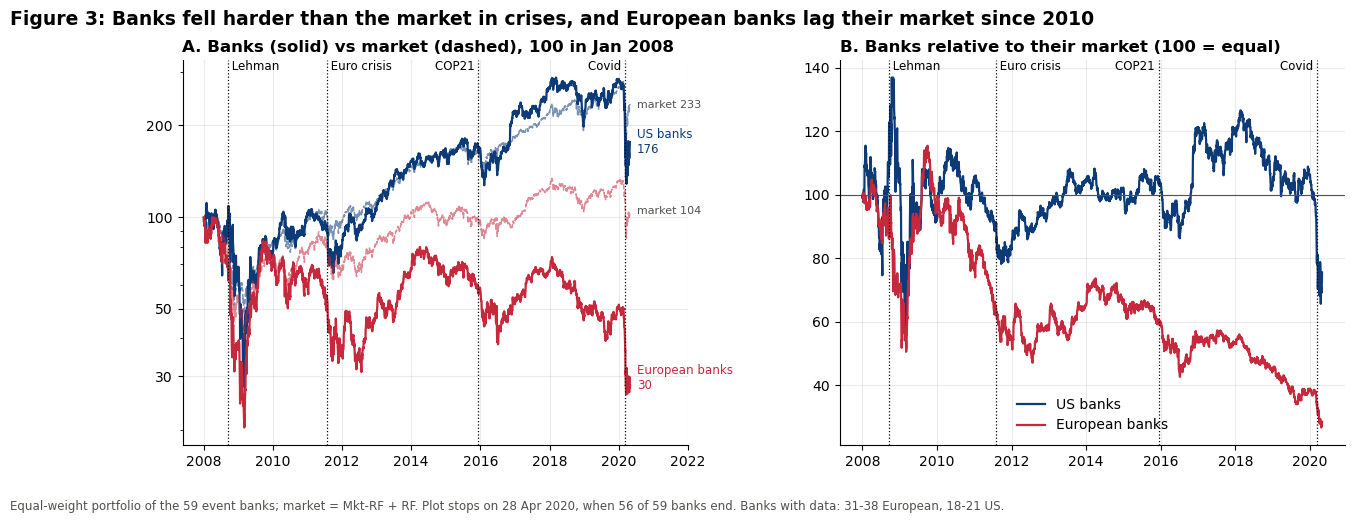

In [47]:
# Figure 3 (performance)
fig, axes = plt.subplots(1, 2, figsize=(15, 5), gridspec_kw={"wspace": 0.3})

# A. levels, with end values labelled
ax = axes[0]
for r, (lab, col) in REG.items():
    ax.plot(res[r].index, res[r]["bank"], color=col, lw=1.6)
    ax.plot(res[r].index, res[r]["mkt"], color=col, lw=1.1, ls="--", alpha=0.55)
    ax.annotate(f"{lab}\n{res[r]['bank'].iloc[-1]:.0f}", (res[r].index[-1], res[r]["bank"].iloc[-1]), xytext=(5, 0), textcoords="offset points", fontsize=8.5, color=col, va="center")
    ax.annotate(f"market {res[r]['mkt'].iloc[-1]:.0f}", (res[r].index[-1], res[r]["mkt"].iloc[-1]), xytext=(5, 0), textcoords="offset points", fontsize=8, color=C["grey"], va="center")
ax.set_yscale("log"); ax.yaxis.set_minor_formatter(matplotlib.ticker.NullFormatter())
ax.set_yticks([30, 50, 100, 200]); ax.set_yticklabels(["30", "50", "100", "200"]); ax.set_xlim(right=pd.Timestamp("2022-01-01"))
marks(ax); ax.set_title("A. Banks (solid) vs market (dashed), 100 in Jan 2008", loc="left", fontweight="bold")

# B. bank / market ratio
ax = axes[1]
for r, (lab, col) in REG.items(): ax.plot(res[r].index, res[r]["rel"], color=col, lw=1.6, label=lab)
ax.axhline(100, color=C["grey"], lw=0.8); marks(ax)
ax.set_title("B. Banks relative to their market (100 = equal)", loc="left", fontweight="bold"); ax.legend(frameon=False, loc="lower center")

style(axes)
fig.suptitle("Figure 3: Banks fell harder than the market in crises, and European banks lag their market since 2010",
             x=0.01, ha="left", fontsize=13.5, fontweight="bold")
n_end = (panel.groupby("ds_name")["date"].max() <= "2020-04-28").sum()
cov = plot.groupby(["date", "region"])["ds_name"].nunique().unstack()
fig.text(0.01, -0.02, f"Equal-weight portfolio of the {panel['ds_name'].nunique()} event banks; market = Mkt-RF + RF. Plot stops on 28 Apr 2020, when {n_end} of {panel['ds_name'].nunique()} banks end. "
         f"Banks with data: {cov['EU'].min()}-{cov['EU'].max()} European, {cov['US'].min()}-{cov['US'].max()} US.", fontsize=8.5, color=C["grey"])
plt.show()

**Comment:** All lines are in USD.

**A.** Bank stocks fall much further than the market in every crisis. In 2008-09 the US bank portfolio loses about 70% and the European one about 80%, and both fall sharply again in the euro crisis (2011-12) and in the Covid crash (March 2020). Between the crises the two regions diverge. US banks stay above their market for most of 2017-2019, but after the Covid crash they stand at 176 against 233 for the market on 28 April 2020. European banks never get back to 100, staying around or below 80 after 2010, while their market rises to about 135 before Covid, and they end at 30 against 104. The COP21 line falls in a flat period for both, with no visible reaction at aggregate level.

**B.** The ratio makes the gap clear. US banks move between about 80 and 110 from 2011 until 2016, jump to about 120 after the US election at the end of 2016 (which matters for the Trump effect we test later), peak near 125 in 2018 and fall to about 75 in April 2020. European banks peak near 115 in 2009, fall to about 50 in 2012, recover to about 70 in 2014, and then drift down to about 38 before Covid and 27 in April 2020. The underperformance of European banks is persistent, not a one-off shock.

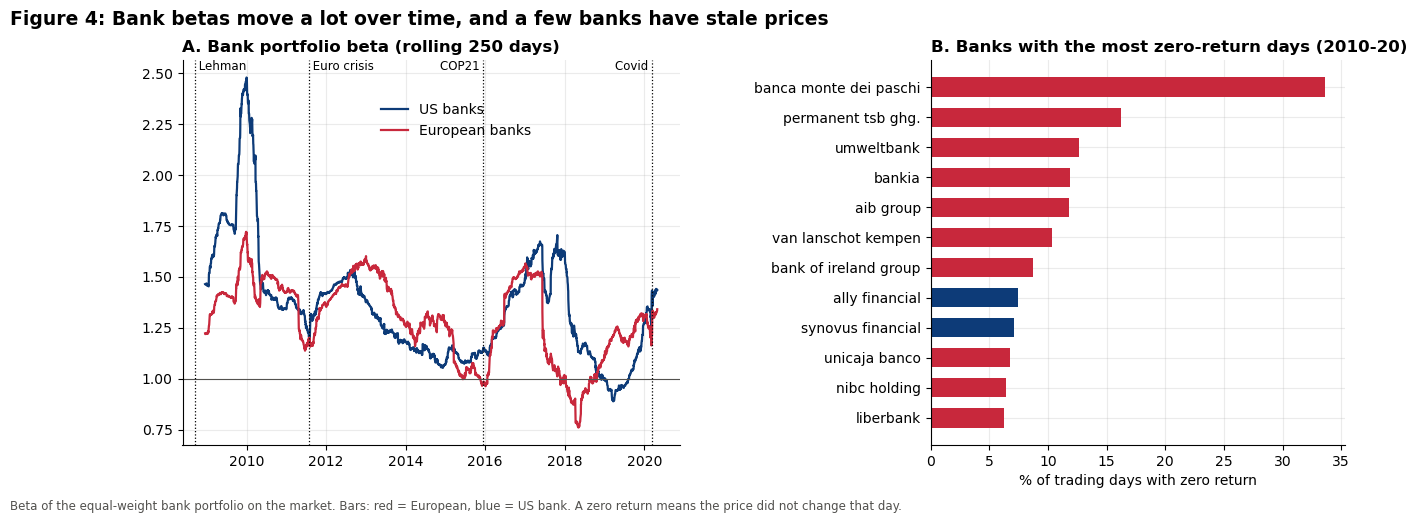

In [48]:
#Figure 4 (risk and data quality)
# Share of days with exactly zero return per bank (stale prices), from 2010
zero = (panel[panel["date"] >= "2010-01-01"].assign(z=lambda d: d["ret_local"].abs() < 1e-12)
        .groupby("ds_name")["z"].mean().sort_values(ascending=False))
reg_of = panel.groupby("ds_name")["region"].first()
top = zero.head(12)[::-1]

fig, axes = plt.subplots(1, 2, figsize=(15, 5), gridspec_kw={"wspace": 0.55, "width_ratios": [1.2, 1]})

# A. rolling beta of the bank portfolio
ax = axes[0]
for r, (lab, col) in REG.items(): ax.plot(res[r].index, res[r]["beta"], color=col, lw=1.6, label=lab)
ax.axhline(1, color=C["grey"], lw=0.8); marks(ax)
ax.set_title("A. Bank portfolio beta (rolling 250 days)", loc="left", fontweight="bold")
ax.legend(frameon=False, loc="upper center", bbox_to_anchor=(0.55, 0.92))

# B. banks with the most stale prices
ax = axes[1]
ax.barh([s[:26] for s in top.index], top.values * 100, color=[REG[reg_of[s]][1] for s in top.index], height=0.65)
ax.set_title("B. Banks with the most zero-return days (2010-20)", loc="left", fontweight="bold")
ax.set_xlabel("% of trading days with zero return")

style(axes)
fig.suptitle("Figure 4: Bank betas move a lot over time, and a few banks have stale prices", x=0.01, ha="left", fontsize=13.5, fontweight="bold")
fig.text(0.01, -0.02, "Beta of the equal-weight bank portfolio on the market. Bars: red = European, blue = US bank. A zero return means the price did not change that day.",
         fontsize=8.5, color=C["grey"])
plt.show()

**Comment:**

**A.** The beta of the bank portfolio is far from constant. For US banks it ranges from about 0.9 to about 2.5: it peaks at about 2.5 at the start of 2010 after the financial crisis, falls to about 1.3 in 2011, rises again to about 1.7 in 2017, and falls back to about 0.9 in 2019 before rising with Covid. European banks mostly move between 1.0 and 1.6, peak at about 1.7 at the end of 2009 and reach a minimum of about 0.76 in 2018. They are close to US banks for much of the period, and above them in 2013-2015. A beta estimated in one period is therefore a poor guide to another, so each event must get its own beta from a window just before it (the 250 days ending 50 days before the event), not one beta for the whole sample.

**B.** A few banks have prices that do not change on many days (measured on local-currency returns, because FX moves would hide a zero return). Monte dei Paschi has a zero return on about 34% of days and Permanent TSB on about 16%. Most banks are far lower. Ten of the twelve banks shown are European (the exceptions are Ally Financial and Synovus). For these banks the beta is estimated with more noise, and an event day with no price change can hide a real reaction. We should check that these banks do not drive the results. We also dropped Saga Group, whose Datastream index never changes (100% zero returns), because it has no usable price data, and removed a duplicated Crédit Agricole series that created false zero returns.

## B2. Rolling betas and expected returns (#4)
For each bank and each day `t`, we regress the bank's excess return on the factors over the window [t−300, t−50], which ends 50 days before `t` as in Krüger (2015), so the estimate never uses the day it is applied to.

`betas_daily.csv` has one row per bank-day, with the parameters (`capm_alpha`, `capm_mkt_rf`, `ff_alpha`, `ff_mkt_rf`, `ff_smb`, `ff_hml`, `ff_rmw`, `ff_cma`) and the expected excess return for that day (`exp_capm`, `exp_ff`). The abnormal return of a day is `exret - exp_capm`.

**For C:** in the event study, read the parameters at the event day `t0` and hold them fixed over the whole event window, as described in the Part C notes.

In [49]:
import statsmodels.api as sm
from statsmodels.regression.rolling import RollingOLS

EST_START, EST_END = 300, 50                                              # estimation window [t-300, t-50]

def rolling_params(d, factors, name):
    window = EST_START - EST_END + 1
    fit = RollingOLS(d["exret"], sm.add_constant(d[factors]), window=window).fit(params_only=True)
    p = fit.params.shift(EST_END)                                         # window ends EST_END days before t
    expected = p["const"] + (p[factors] * d[factors]).sum(axis=1, min_count=len(factors))
    return p.rename(columns=lambda c: f"{name}_alpha" if c == "const" else f"{name}_{c}").assign(**{f"exp_{name}": expected})

parts = []
for _, d in panel.groupby("ds_name"):
    parts.append(pd.concat([d[["date", "ds_name", "region", "t", "exret"]],
                            rolling_params(d, ["mkt_rf"], "capm"), rolling_params(d, FACTORS, "ff")], axis=1))
betas = pd.concat(parts, ignore_index=True).dropna(subset=["capm_alpha"])

betas.to_csv(OUT / "betas_daily.csv", index=False)
print(f"{len(betas):,} bank-days with betas | {betas['ds_name'].nunique()} banks")
print(betas.groupby("region")[["capm_mkt_rf", "ff_mkt_rf", "ff_smb", "ff_hml", "ff_rmw", "ff_cma"]].median().round(2))
print(f"Abnormal return, daily std: CAPM {(betas['exret'] - betas['exp_capm']).std():.4f}, FF {(betas['exret'] - betas['exp_ff']).std():.4f}")

154,802 bank-days with betas | 59 banks
        capm_mkt_rf  ff_mkt_rf  ff_smb  ff_hml  ff_rmw  ff_cma
region                                                        
EU             1.31       0.89   -0.35    0.86   -1.54   -0.50
US             1.26       1.15    0.01    0.99   -0.91   -0.05
Abnormal return, daily std: CAPM 0.0232, FF 0.0218


**Comment:** 

The median CAPM beta is 1.26 for US banks and 1.31 for European banks. In the Fama-French five-factor model both load strongly on HML (0.99 and 0.86), so banks behave like value stocks, and the market beta of European banks drops to 0.89 once the other four factors are included. Both also load negatively on RMW (−0.91 for US banks, −1.54 for European banks), so they behave like weakly profitable firms, and European banks load negatively on CMA (−0.50, against −0.05 for US banks), like aggressive investors. The extra factors reduce the daily abnormal-return volatility from 2.32% (CAPM) to 2.18% (FF5).

**Effect of the USD conversion:** converting returns to USD puts returns and factors in the same currency. It affects the European banks (38 of the 59); US banks are unchanged. 

# Part C: Event study 

## C1. Event study: CAPM and cumulative abnormal returns
We follow Krüger (2015). For each kept campaign event, we estimate a market model for the targeted bank just before the event, use it to predict the bank's "normal" return around the event, and measure how far the actual return deviates from it.

In [50]:
ev = events[events["keep"]].copy()

ev = ev.merge(
    panel[["ds_name", "date", "t"]], 
    left_on=["ds_name", "trade_date"],
    right_on=["ds_name", "date"],
    how="left",  
    suffixes=("", "_panel"),
)
ev = ev.rename(columns={"t": "t0"})

In [51]:
print(f"{len(ev):,} events kept")
print(f"{ev['t0'].isna().sum()} without a matching trading day in the panel")
print(f"{(ev['t0'] < 300).sum()} with less than 300 days of history before t0")

1,363 events kept
50 without a matching trading day in the panel
12 with less than 300 days of history before t0


In [52]:
miss = ev[ev["t0"].isna()]
span = panel.groupby("ds_name")["date"].agg(first="min", last="max")
miss = miss.join(span, on="ds_name")

outside = (miss["trade_date"] < miss["first"]) | (miss["trade_date"] > miss["last"])
print(f"{outside.sum()} outside the bank's price history (not yet listed / delisted)")
print(f"{(~outside).sum()} inside the history but no return that day (holiday / removed return)")
print(f"{miss['ds_name'].nunique()} distinct banks concerned")

50 outside the bank's price history (not yet listed / delisted)
0 inside the history but no return that day (holiday / removed return)
7 distinct banks concerned


**Locating the event day:** Trading days (`t`) are numbered bank by bank in Part B, so all windows are measured in trading days. We find the event day t0 by matching each kept event to the panel on bank and trade date. Of the 1,363 kept events, 50 (7 banks) fall outside the bank's price history: the bank was not yet listed, or no longer listed, on the event date, so no market reaction can be measured. No event is lost to holidays or removed returns. A further 12 events have fewer than 300 trading days before t0, so the estimation window [t0−300, t0−50] cannot be filled. Dropping the unusable events leaves 1,301 events (95% of the kept sample) on 55 banks (only 4 of the 7 banks had no usable events).

In [53]:
ev = ev[ev["t0"].notna() & (ev["t0"] >= 300)].copy()
ev["t0"] = ev["t0"].astype(int)          #t0 was float because of the NaNs
print(f"{len(ev):,} events for the event study")

1,301 events for the event study


**Method:** All windows are measured in the bank's trading days (`t`), not calendar days, and all returns are in USD.

- **Estimation window** [t0−300, t0−50] (251 days). We use the parameters estimated in Part B, read at t0 and held fixed over the whole event window, so the benchmark only uses information from before the event:
  $r_{i,t} - r_{f,t} = \alpha_i + \beta_i \,(r_{m,t} - r_{f,t}) + \varepsilon_{i,t}$.
  The 50-day gap keeps any pre-event information leakage out of the estimation.
- **Abnormal return** on each day of the event window:
  $AR_{i,t} = (r_{i,t} - r_{f,t}) - (\hat\alpha_i + \hat\beta_i \,(r_{m,t} - r_{f,t}))$.
- **CAR** = sum of the daily ARs over the window. We also keep the event-day abnormal return `ar0`.

`run_event_study` takes the window (`pre`, `post`) and the model as arguments. Our main specification is the CAPM on [t0−10, t0+10] (21 days); we also run [t0−1, t0+1] and [t0−5, t0+5], and a Fama-French model. For each event, it also computes the residual volatility `sigma` and the share of positive residuals `pos_share` on the estimation window, which the significance tests need, and `n_other`, the number of other campaigns on the same bank inside the event window.

Because `t0 ≥ 300` and `t` has no gaps, every estimation window has exactly 251 days. The function also checks that the event window is complete, which matters only if a bank's price series ends before t0+10; this never happens here, so all 1,301 events get a CAR.

In [54]:
# all campaign days of each bank, in trading days, including those dropped by the overlap rule
camp = events.merge(panel[["ds_name", "date", "t"]], left_on=["ds_name", "trade_date"],
                    right_on=["ds_name", "date"], how="inner", suffixes=("", "_panel"))
campaign_t = camp.groupby("ds_name")["t"].apply(lambda s: np.sort(s.unique()))

In [55]:
MODELS = {"capm": ["mkt_rf"], "ff": FACTORS}


def run_event_study(ev, panel, betas, pre=10, post=10, model="capm"):

    factors = MODELS[model]
    cols = [f"{model}_alpha"] + [f"{model}_{f}" for f in factors]
    data = ev.merge(betas[["ds_name", "t", *cols]], left_on=["ds_name", "t0"], right_on=["ds_name", "t"], how="left")

    rows = []
    for _, e in data.iterrows():
        bank = panel[panel["ds_name"] == e["ds_name"]]
        win = bank[(bank["t"] >= e["t0"] - pre) & (bank["t"] <= e["t0"] + post)].copy()

        if len(win) < pre + post + 1:
            continue

        def predict(d):
            return e[f"{model}_alpha"] + sum(e[f"{model}_{f}"] * d[f] for f in factors)

        win["ar"] = win["exret"] - predict(win)

        est = bank[(bank["t"] >= e["t0"] - 300) & (bank["t"] <= e["t0"] - 50)]
        resid = est["exret"] - predict(est)

        rows.append({
            "ds_name": e["ds_name"],
            "trade_date": e["trade_date"],
            "alpha": e[f"{model}_alpha"],
            "beta": e[f"{model}_{factors[0]}"],
            "car": win["ar"].sum(),
            "ar0": win["ar"].iloc[pre], 
            "n_big": int(win["big"].sum()),
            "ar_path": win["ar"].to_numpy(),
            "sigma": resid.std(ddof=len(factors) + 1),     # residual volatility, for Boehmer
            "pos_share": (resid > 0).mean(),               # share of positive ARs, for Cowan
            "r2": 1 - resid.var() / est["exret"].var(),
            "sign": e["sign"],
            "uids": e["uids"],
            "n_other": int(((campaign_t[e["ds_name"]] >= e["t0"] - pre) & (campaign_t[e["ds_name"]] <= e["t0"] + post)
                            & (campaign_t[e["ds_name"]] != e["t0"])).sum()),   # other campaigns inside the window
        })

    return pd.DataFrame(rows)

In [56]:
studies = {}
for model in ["capm", "ff"]:
    for k in [1, 5, 10]:
        studies[(model, k)] = run_event_study(ev, panel, betas, pre=k, post=k, model=model)

summary = pd.DataFrame({key: s["car"].describe() for key, s in studies.items()}).T
print(summary[["count", "mean", "50%", "std", "min", "max"]].round(4))
print(f"Correlation CAPM / FF on [-10,+10]: {studies[('capm', 10)]['car'].corr(studies[('ff', 10)]['car']):.3f}")
print(studies[("capm", 10)][["sigma", "pos_share"]].describe().round(4))

          count    mean     50%     std     min     max
capm 1   1301.0 -0.0023 -0.0025  0.0346 -0.7553  0.2365
     5   1301.0 -0.0030 -0.0044  0.0613 -1.1080  0.3852
     10  1301.0 -0.0040 -0.0054  0.0805 -1.3872  0.4070
ff   1   1301.0 -0.0012 -0.0009  0.0327 -0.7844  0.2285
     5   1301.0 -0.0014 -0.0006  0.0554 -1.0918  0.3248
     10  1301.0 -0.0038 -0.0045  0.0730 -1.3931  0.3700
Correlation CAPM / FF on [-10,+10]: 0.856
           sigma  pos_share
count  1301.0000  1301.0000
mean      0.0153     0.4859
std       0.0073     0.0263
min       0.0052     0.3944
25%       0.0109     0.4661
50%       0.0139     0.4861
75%       0.0181     0.5060
max       0.0922     0.5817


In [57]:
# diagnostics of the market model on the estimation window, CAPM only

from statsmodels.stats.diagnostic import het_breuschpagan

data = ev.merge(betas[["ds_name", "t", "capm_alpha", "capm_mkt_rf"]], left_on=["ds_name", "t0"], right_on=["ds_name", "t"], how="left")

rows = []
for _, e in data.iterrows():
    bank = panel[panel["ds_name"] == e["ds_name"]]
    est = bank[(bank["t"] >= e["t0"] - 300) & (bank["t"] <= e["t0"] - 50)]

    x, y = est["mkt_rf"], est["exret"]
    resid = y - (e["capm_alpha"] + e["capm_mkt_rf"] * x)

    half = len(est) // 2
    x1, y1 = x.iloc[:half], y.iloc[:half]
    x2, y2 = x.iloc[half:], y.iloc[half:]

    rows.append({
        "ds_name": e["ds_name"],
        "trade_date": e["trade_date"],
        "dw": (resid.diff() ** 2).sum() / (resid ** 2).sum(),
        "bp_p": het_breuschpagan(resid, sm.add_constant(x))[1],
        "beta_1": x1.cov(y1) / x1.var(),
        "beta_2": x2.cov(y2) / x2.var(),
    })

cars = studies[("capm", 10)].merge(pd.DataFrame(rows), on=["ds_name", "trade_date"])

In [58]:
print(f"{len(cars):,} events with a CAR")
print(cars[["beta", "car", "ar0"]].describe().round(4))

1,301 events with a CAR
            beta        car        ar0
count  1301.0000  1301.0000  1301.0000
mean      1.3620    -0.0040    -0.0003
std       0.3842     0.0805     0.0217
min      -0.1084    -1.3872    -0.4891
25%       1.1034    -0.0416    -0.0081
50%       1.3403    -0.0054    -0.0007
75%       1.6130     0.0329     0.0069
max       2.7594     0.4070     0.1870


In [59]:
low_dw = cars["dw"] < 1.5
cars["beta_diff"] = cars["beta_2"] - cars["beta_1"]
print(f"{low_dw.mean():.1%} of events have a Durbin-Watson < 1.5 (autocorrelated residuals)")
bp_events = cars["bp_p"] < 0.05
print(f"{bp_events.mean():.1%} of events have a Breusch-Pagan p-value < 0.05 (heteroskedastic residuals)")
print(cars[["r2", "dw", "beta_diff"]].describe().round(4))
print(f"Correlation between first- and second-half betas: {cars['beta_1'].corr(cars['beta_2']):.2f}")
print(cars.groupby("ds_name")["r2"].median().nsmallest(6).round(3))

0.4% of events have a Durbin-Watson < 1.5 (autocorrelated residuals)
18.0% of events have a Breusch-Pagan p-value < 0.05 (heteroskedastic residuals)
              r2         dw  beta_diff
count  1301.0000  1301.0000  1301.0000
mean      0.4475     2.1026    -0.0323
std       0.1658     0.2110     0.3949
min       0.0019     1.3265    -2.2208
25%       0.3332     1.9602    -0.2593
50%       0.4634     2.1025    -0.0281
75%       0.5775     2.2496     0.2142
max       0.7737     2.9495     1.1999
Correlation between first- and second-half betas: 0.56
ds_name
umweltbank             0.003
van lanschot kempen    0.105
permanent tsb ghg.     0.114
aib group              0.143
erste group bank       0.168
abn amro bank          0.194
Name: r2, dtype: float64


**Diagnostics of the market model:** The market factor explains a median 46% of daily bank returns (R²). The lowest R² belong to Umweltbank, Van Lanschot Kempen, Permanent TSB and AIB, three of which also have many zero-return days. Residuals show little first-order autocorrelation (mean Durbin-Watson 2.10; only 0.4% of events below 1.5). The Breusch-Pagan test rejects homoskedasticity for 18% of events (against 5% expected by chance): this does not bias α and β, but it means that our significance tests should not rely on a constant variance. Betas estimated on the two halves of the estimation window show no systematic drift (mean difference −0.03) but vary substantially across the two halves (standard deviation 0.39, correlation 0.56), consistent with changing risk during the crisis years. We therefore check below that our results hold with a market-adjusted model (β = 1), which does not require estimating β.

In [60]:
low = cars[cars["beta"] < 0.3]
print(f"Betas: mean {cars['beta'].mean():.2f}, median {cars['beta'].median():.2f}")
print(f"{len(low)} events with beta < 0.3:")
for bank, n in low["ds_name"].value_counts().items():
    print(f"{bank}: {n} events, {zero[bank]:.1%} zero-return days")

Betas: mean 1.36, median 1.34
3 events with beta < 0.3:
umweltbank: 3 events, 12.6% zero-return days


**Result:** The mean estimated beta is 1.36 and the median 1.34, so on average banks move more than the market. Only 3 events, all on Umweltbank, have a beta below 0.3. Umweltbank is a small German bank with a zero return on 12.6% of its trading days, and infrequent price changes bias betas towards zero.

In [61]:
print(f"{(cars['car'] < -0.5).sum()} events with CAR < -50%, {(cars['car'] > 0.3).sum()} with CAR > +30%")
print(cars.nsmallest(5, "car")[["ds_name", "trade_date", "car", "beta"]].round({"car": 3, "beta": 3}))
print(cars.nlargest(5, "car")[["ds_name", "trade_date", "car", "beta"]].round({"car": 3, "beta": 3}))

1 events with CAR < -50%, 5 with CAR > +30%
                     ds_name trade_date    car   beta
154                   bankia 2013-05-23 -1.387  1.273
14    banca monte dei paschi 2016-12-09 -0.322  2.386
167            bankinter 'r' 2012-05-29 -0.304  1.142
187                 barclays 2012-07-06 -0.248  1.807
1186               unicredit 2016-01-14 -0.237  1.432
                    ds_name trade_date    car   beta
830               kbc group 2012-01-18  0.407  1.697
155                  bankia 2014-01-21  0.351  1.377
972  royal bank of sctl.gp. 2010-04-22  0.335  1.962
218                barclays 2016-10-28  0.305  1.976
533           deutsche bank 2016-10-13  0.301  1.579


**Extreme CARs:** A handful of events have very large CARs. In the cases below, a major bank-specific or sector-wide shock falls inside the event window, so these CARs are most likely driven by that shock rather than by the NGO campaign:

- **Bankia, May 2013 (CAR ≈ −139%):** the state recapitalisation by the FROB almost wiped out existing shareholders and forcibly converted retail hybrid debt into shares; when trading resumed, these new shareholders sold massively. A CAR below −100% does not mean the share lost more than its value: the CAR sums daily abnormal returns instead of compounding them, which overstates losses when daily moves are very large.
- **Monte dei Paschi, December 2016 (−32%):** the private recapitalisation failed, trading was suspended and the Italian state stepped in.
- **Barclays, July 2012 (−25%):** the LIBOR scandal, with a settlement with regulators and the resignation of its CEO.
- **Bankinter, May 2012 (−30%) and UniCredit, January 2016 (−24%):** periods of stress for Spanish and Italian banks.
- **Positive extremes, +30% to +41%:** mostly rebounds after periods of stress, e.g. KBC in January 2012, when European bank stocks rallied after the ECB's long-term refinancing operations, and Deutsche Bank in October 2016, recovering from fears of a $14bn fine from the US Department of Justice.

We draw two lessons. First, a few events dominate the mean, so we winsorise CARs at 1%/99% and also report medians. Second, four of the five most negative CARs are Spanish or Italian banks, and the market factor does not capture national or bank-sector shocks; a bank-sector benchmark would be a natural extension.

In [62]:
def winsorise(s, col="car"):
    lo, hi = s[col].quantile([0.01, 0.99])
    return s.assign(car_w=s[col].clip(lo, hi))

In [63]:
cars = winsorise(cars)
print(f"CARs winsorised at 1%/99%: [{cars['car_w'].min():.1%}, {cars['car_w'].max():.1%}]")
print(f"{(cars['n_big'] > 0).sum()} events with a >50% daily move in the event window")

CARs winsorised at 1%/99%: [-17.7%, 21.1%]
1 events with a >50% daily move in the event window


In [64]:
cars = cars.merge(
    ev[["ds_name", "trade_date", "sentiment", "negative", "prominence",
        "ngo_power", "n_targets", "climate", "mass", "region"]],
    on=["ds_name", "trade_date"], how="left",
)
print(cars.shape)
cars["ds_name"].nunique()

(1301, 28)


55

In [65]:
# other windows and models, then the handoff file (one row per event, without the daily path)
extra = {"car_1": ("capm", 1), "car_5": ("capm", 5),
         "car_ff": ("ff", 10), "car_ff_1": ("ff", 1), "car_ff_5": ("ff", 5)}

for name, key in extra.items():
    cars = cars.merge(studies[key][["ds_name", "trade_date", "car"]].rename(columns={"car": name}),
                      on=["ds_name", "trade_date"], how="left")

cars.drop(columns="ar_path").to_csv(OUT / "cars.csv", index=False)
print(cars.shape, cars["ds_name"].nunique())

(1301, 33) 55


**Output of Part C:** `cars` holds one row per event (1,301 events, 55 banks). CARs are winsorised at 1%/99% (bounds [−17.7%, +21.1%]). Next, we test whether they differ from zero, separately for negative and positive campaigns.

In [66]:
def clustered_t(y, groups):
    # regressing y on a constant gives its mean; the cluster SE allow correlation within a group
    fit = sm.OLS(y.to_numpy(), np.ones(len(y))).fit(cov_type="cluster", cov_kwds={"groups": pd.factorize(groups)[0]})
    return fit.tvalues[0]

def car_tests(s, pre, post, col="car_w"):
    y, n = s[col], len(s)

    scar = y / (s["sigma"] * np.sqrt(pre + post + 1))       # CAR in units of its expected volatility
    p = s["pos_share"].mean()                               # share of positive ARs in normal times

    return pd.Series({
        "n": n,
        "mean": y.mean(),
        "median": y.median(),
        "t_plain": y.mean() / (y.std() / np.sqrt(n)),
        "t_boehmer": scar.mean() * np.sqrt(n) / scar.std(),
        "z_cowan": ((y > 0).sum() - n * p) / np.sqrt(n * p * (1 - p)),
        "t_date": clustered_t(y, s["trade_date"]),
        "t_month": clustered_t(y, s["trade_date"].dt.to_period("M")),
    })

In [67]:
def test_table(studies, keep=None, col="car_w"):
    rows = {}
    for (model, k), st in studies.items():
        w = winsorise(st)
        if keep is not None:
            w = w[keep(w)]
        for sign in ["neg", "pos"]:
            rows[(model, k, sign)] = car_tests(w[w["sign"] == sign], k, k, col)
    out = pd.DataFrame(rows).T
    out.index.names = ["model", "window", "sign"]
    return out


results = test_table(studies)
clean = test_table(studies, keep=lambda w: w["n_other"] == 0)

print(pd.Series({k: (s["n_other"] > 0).mean() for k, s in studies.items()}).round(3))
print(results.round(3).to_string())
print(clean.round(3).to_string())
m, t = results.loc[("capm", 10, "neg"), ["mean", "t_month"]]
se = m / t
print(f"95% CI of the mean CAR (month-clustered): [{m - 1.96 * se:.1%}, {m + 1.96 * se:.1%}]")

capm  1     0.058
      5     0.254
      10    0.447
ff    1     0.058
      5     0.254
      10    0.447
dtype: float64
                        n   mean  median  t_plain  t_boehmer  z_cowan  t_date  t_month
model window sign                                                                     
capm  1      neg   1054.0 -0.002  -0.003   -2.197     -1.628   -2.221  -1.551   -1.671
             pos    162.0 -0.006  -0.003   -2.963     -3.382   -1.562  -2.722   -2.844
      5      neg   1054.0 -0.002  -0.004   -1.542     -1.916   -2.036  -1.174   -0.922
             pos    162.0 -0.007  -0.011   -2.046     -2.302   -2.191  -1.900   -1.739
      10     neg   1054.0 -0.004  -0.007   -1.843     -2.444   -1.913  -1.382   -0.993
             pos    162.0 -0.005  -0.002   -1.056     -1.051    0.167  -0.963   -0.840
ff    1      neg   1054.0 -0.001  -0.001   -0.805     -0.007   -0.811  -0.673   -0.709
             pos    162.0 -0.005  -0.003   -2.619     -2.598   -1.372  -2.601   -2.916
      5

**Significance tests:** We test whether the mean CAR differs from zero, separately for negative and positive campaigns, on winsorised CARs. A plain t-test assumes independent events, so we report several tests:

- **Boehmer et al.:** scales each CAR by the bank's own volatility and uses the observed dispersion around the event, so it allows for higher volatility on event days.
- **Cowan's sign test:** compares the share of positive CARs with its normal share in the estimation window, so extreme CARs do not matter.
- **t-tests clustered by date and by month:** allow CARs to be correlated across events. Windows last up to 21 days, so events close in time share the same shocks, and the month-clustered test is our most cautious one.

**Results:** For negative campaigns, our main specification (CAPM, [−10,+10], 1,054 events) gives a mean CAR of −0.4% and a median of −0.7%. Boehmer (−2.44) is significant at 5%, and Cowan (−1.91) is close, but the effect is not significant once we allow for correlation across events (−1.38 by date, −0.99 by month). The 95% confidence interval from the month-clustered test is about [−1.1%, +0.4%], so a small negative effect cannot be ruled out, but we find no robust evidence of one. With the Fama-French five-factor model, the mean is −0.3% (Boehmer −1.70, −1.28 by month), also not significant. This differs from Krueger (2015), who finds a strong negative reaction to negative events.

For positive campaigns (162 events), the mean CAR on [−1,+1] is −0.6% (−3.38 Boehmer, −2.72 by date, −2.84 by month), but the sign test is weaker (−1.56). On longer windows, the effect is not significant with clustering. A negative reaction to good news is in line with Krueger's weakly negative result, but we do not test why it happens here.

These pooled results hide a difference between regions: see the bank-benchmark extension at the end of Part C, where negative campaigns have a short-lived effect for European banks only.

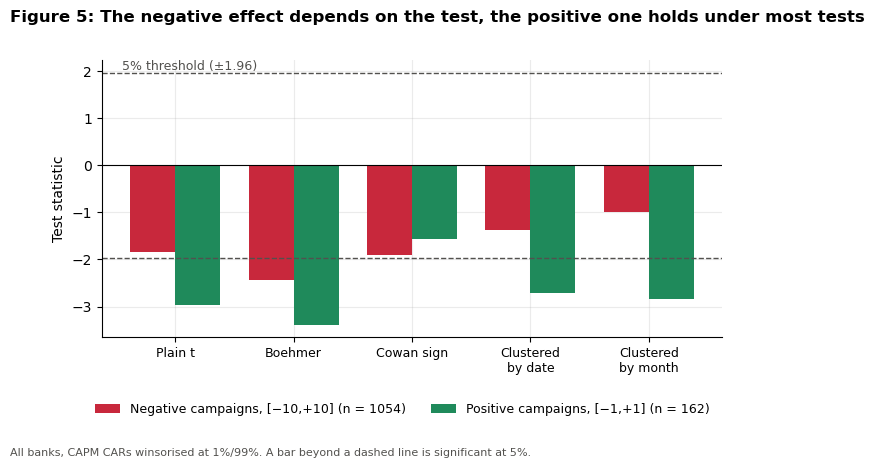

In [68]:
tests = {"t_plain": "Plain t", "t_boehmer": "Boehmer", "z_cowan": "Cowan sign",
         "t_date": "Clustered\nby date", "t_month": "Clustered\nby month"}
cases = {"Negative campaigns, [−10,+10]": ("capm", 10, "neg"), "Positive campaigns, [−1,+1]": ("capm", 1, "pos")}

x, w = np.arange(len(tests)), 0.38
fig, ax = plt.subplots(figsize=(8, 3.6))
for j, (label, key) in enumerate(cases.items()):
    ax.bar(x + (j - 0.5) * w, results.loc[key, list(tests)], width=w, color=C[key[2]],
           label=f"{label} (n = {int(results.loc[key, 'n'])})")

for level in (-1.96, 1.96):
    ax.axhline(level, color=C["grey"], ls="--", lw=1)
ax.axhline(0, color="black", lw=0.8)
ax.text(-0.45, 1.96, "5% threshold (±1.96)", ha="left", va="bottom", fontsize=9, color=C["grey"])

ax.set_xticks(x, list(tests.values()), fontsize=9)
ax.set_ylabel("Test statistic")
style([ax])
fig.legend(*ax.get_legend_handles_labels(), loc="lower center", ncol=2, frameon=False,
           bbox_to_anchor=(0.5, -0.14), fontsize=9)
fig.suptitle("Figure 5: The negative effect depends on the test, the positive one holds under most tests",
             x=0.01, y=1.02, ha="left", fontsize=12, fontweight="bold")
fig.text(0.01, -0.22, "All banks, CAPM CARs winsorised at 1%/99%. A bar beyond a dashed line is significant at 5%.",
         fontsize=8, color=C["grey"])
plt.show()

**Figure 5:** For negative campaigns on [−10,+10], only Boehmer's test is significant at 5% (−2.44). The plain t-test (−1.84) and Cowan's sign test (−1.91) are just short of the threshold, and the statistic falls to −1.38 once errors are clustered by date and to −0.99 by month. The apparent effect therefore relies on treating events as independent, which they are not: many campaigns fall on the same days or in the same weeks. For positive campaigns on [−1,+1], four of the five tests are significant, including both clustered ones (−2.72 by date, −2.84 by month). Only the sign test is not (−1.72), which suggests that part of the effect comes from a minority of large negative CARs rather than a general shift.

In [69]:
# market-adjusted model: alpha = 0 and beta = 1
MODELS["mkt"] = ["mkt_rf"]
betas["mkt_alpha"], betas["mkt_mkt_rf"] = 0.0, 1.0
for k in [1, 5, 10]:
    studies[("mkt", k)] = run_event_study(ev, panel, betas, pre=k, post=k, model="mkt")

stale = zero[zero > 0.10].index
print(f"{len(stale)} banks with more than 10% zero-return days: {list(stale)}")

checks = {
    "baseline": test_table(studies),
    "clean": test_table(studies, keep=lambda w: w["n_other"] == 0),
    "raw": test_table(studies, col="car"),
    "no_stale": test_table(studies, keep=lambda w: ~w["ds_name"].isin(stale)),
}

6 banks with more than 10% zero-return days: ['banca monte dei paschi', 'permanent tsb ghg.', 'umweltbank', 'bankia', 'aib group', 'van lanschot kempen']


In [70]:
pos = winsorise(studies[("capm", 1)])
pos = pos[pos["sign"] == "pos"].sort_values("car_w")

print(f"{(pos['car_w'] < 0).mean():.1%} of positive campaigns have a negative CAR on [-1,+1]")
print(pos[["ds_name", "trade_date", "car_w"]].head(5).round({"car_w": 3}).to_string())
print(pos["trade_date"].value_counts().head(5).to_string())
print(pos.groupby("ds_name")["car_w"].agg(["size", "mean", "sum"]).sort_values("sum").head(5).round(3).to_string())

print(car_tests(pos.iloc[5:], 1, 1)[["n", "mean", "t_month"]].round(4).to_string())

57.4% of positive campaigns have a negative CAR on [-1,+1]
                 ds_name trade_date  car_w
756      intesa sanpaolo 2016-02-17 -0.077
1099  standard chartered 2015-11-06 -0.077
1100  standard chartered 2016-02-17 -0.077
1167          umweltbank 2016-01-14 -0.075
1179           unicredit 2013-06-26 -0.071
trade_date
2015-11-23    9
2016-02-17    5
2015-05-20    5
2015-04-09    5
2016-05-03    3
                       size   mean    sum
ds_name                                  
standard chartered        7 -0.026 -0.183
wells fargo & co         11 -0.011 -0.124
jp morgan chase & co.     7 -0.015 -0.104
van lanschot kempen      11 -0.008 -0.093
umweltbank                3 -0.029 -0.086
n          157.0000
mean        -0.0036
t_month     -1.9322


**Positive campaigns on [−1,+1]:** The effect is not driven by a few events: without the five most negative CARs, the mean is −0.36% (t_month −1.93), and 57% of CARs are negative. We read it with caution: it was not our starting hypothesis, it rests on 162 events, and 24 of them fall on just four dates.

In [71]:
keys = [("capm", 10, "neg"), ("ff", 10, "neg"), ("capm", 1, "pos"), ("ff", 1, "pos"), ("mkt", 1, "pos")]
print(pd.concat({name: t.loc[keys, ["mean", "t_month"]] for name, t in checks.items()}, axis=1).round(4).to_string())

                  baseline           clean             raw         no_stale        
                      mean t_month    mean t_month    mean t_month     mean t_month
model window sign                                                                  
capm  10     neg   -0.0039 -0.9929 -0.0052 -1.2916 -0.0048 -1.1356  -0.0032 -0.8167
ff    10     neg   -0.0033 -1.2765 -0.0042 -1.4227 -0.0044 -1.5060  -0.0030 -1.1898
capm  1      pos   -0.0059 -2.8436 -0.0059 -2.7346 -0.0054 -2.2538  -0.0052 -2.4072
ff    1      pos   -0.0046 -2.9156 -0.0044 -2.7091 -0.0040 -2.1038  -0.0038 -2.4311
mkt   1      pos   -0.0058 -2.8039 -0.0058 -2.6533 -0.0054 -2.3042  -0.0054 -2.5019


**Robustness:** The table shows our key cases under each check: dropping events with another campaign in the window (`clean`, 45% of events on [−10,+10]), raw instead of winsorised CARs (`raw`), and dropping banks with many zero-return days (`no_stale`). For negative campaigns, the mean CAR stays negative but never significant. The Fama-French five-factor model gives a similar mean (−0.33% against −0.39% under CAPM) and is also not significant (month-clustered t = −1.28 against −0.99). For positive campaigns on [−1,+1], the mean stays around −0.5% and its month-clustered t-statistic exceeds 2 in absolute value under every check, including the β = 1 model, although the sign test is weaker.

The bank-sector benchmark at the end of Part C is a further check: it removes shocks common to all banks, and it confirms that the positive-campaign effect is limited to [−1,+1].

In [72]:
# data check: bank-years where more than half of the days have a zero return
p = panel[panel["date"] >= "2010-01-01"].assign(zero=lambda d: d["ret_local"].abs() < 1e-12)
by_year = p.groupby(["ds_name", p["date"].dt.year])["zero"].mean()
print(by_year[by_year > 0.5].round(2).to_string())

ds_name                 date
banca monte dei paschi  2017    0.97
                        2018    0.88
                        2019    0.92
                        2020    0.88


**Data check:** Monte dei Paschi's return series is almost entirely frozen from 2017 to 2020. This does not affect our results, because its only event in the sample is on 9 December 2016.

In [73]:
def build_ev(gap):
    e = events[overlap_rule(events, gap)].merge(panel[["ds_name", "date", "t"]], left_on=["ds_name", "trade_date"],
                                                right_on=["ds_name", "date"], how="inner", suffixes=("", "_panel"))
    e = e.rename(columns={"t": "t0"})
    return e[e["t0"] >= 300].copy()


rows = {}
for gap in [30, 45, 60, 90]:
    e = build_ev(gap)
    for model in ["capm", "ff"]:
        w = winsorise(run_event_study(e, panel, betas, model=model))
        for sign in ["neg", "pos"]:
            rows[(gap, model, sign)] = car_tests(w[w["sign"] == sign], 10, 10)

gaps = pd.DataFrame(rows).T
gaps.index.names = ["gap", "model", "sign"]
print(gaps[["n", "mean", "median", "t_boehmer", "t_month"]].round(4).to_string())

                     n    mean  median  t_boehmer  t_month
gap model sign                                            
30  capm  neg   1054.0 -0.0039 -0.0066    -2.4442  -0.9929
          pos    162.0 -0.0050 -0.0021    -1.0512  -0.8400
    ff    neg   1054.0 -0.0033 -0.0055    -1.7037  -1.2765
          pos    162.0 -0.0030 -0.0043    -0.9627  -0.6173
45  capm  neg    869.0 -0.0046 -0.0085    -2.5140  -1.1121
          pos    127.0 -0.0046 -0.0108    -0.6206  -0.6368
    ff    neg    869.0 -0.0027 -0.0054    -1.2156  -1.0153
          pos    127.0 -0.0054 -0.0066    -1.0406  -0.8655
60  capm  neg    737.0 -0.0051 -0.0100    -2.3705  -1.1131
          pos    114.0 -0.0082 -0.0129    -1.1976  -1.1728
    ff    neg    737.0 -0.0034 -0.0077    -1.1943  -1.1317
          pos    114.0 -0.0103 -0.0073    -1.6913  -1.6814
90  capm  neg    598.0 -0.0033 -0.0045    -1.0041  -0.7664
          pos     77.0 -0.0083 -0.0145    -0.8651  -0.9743
    ff    neg    598.0 -0.0031 -0.0045    -0.9016  -0.99

**Other overlap gaps:** On [−10,+10], gaps of 30 to 90 days give a mean CAPM CAR between −0.33% and −0.51% for negative campaigns, with t_month between −0.76 and −1.11. A longer gap does not remove the other campaigns from the window: it only changes which events we keep.

## Extension: a bank-sector benchmark

This extension checks whether abnormal returns around NGO campaigns reflect movements common to the banking sector that the broad market benchmark may miss. We replace the market factor with an equal-weight index of the other banks in the same region, excluding the bank being studied, and recompute CARs to assess whether the results survive after accounting for sector-wide shocks.

In [74]:
# leave-one-out bank index: each day, the equal-weight return of the other banks in the same region
g = panel.groupby(["region", "date"])["ret"]
n_banks = g.transform("count")
panel["bank_mkt"] = (g.transform("sum") - panel["ret"]) / (n_banks - 1)
panel["bank_rf"] = panel["bank_mkt"] - panel["rf"]

print(n_banks.groupby(panel["region"]).describe()[["min", "50%", "max"]])
print(panel.groupby("region")[["bank_rf", "mkt_rf"]].corr().round(2))
print(panel.groupby("region")[["bank_rf", "mkt_rf"]].std().round(4))

         min   50%   max
region                  
EU       3.0  33.0  38.0
US      18.0  20.0  21.0
                bank_rf  mkt_rf
region                         
EU     bank_rf     1.00    0.82
       mkt_rf      0.82    1.00
US     bank_rf     1.00    0.80
       mkt_rf      0.80    1.00
        bank_rf  mkt_rf
region                 
EU       0.0219  0.0133
US       0.0243  0.0129


**Bank index:** Each day, a bank's benchmark is the equal-weight return of the other banks in the same region (US or Europe), so a bank is never compared with itself. The index is correlated at 0.80–0.82 with the market factor, so the market explains about two thirds of its daily variance, and it is much more volatile (2.2–2.4% a day against 1.3%). The rest includes shocks common to banks, which this benchmark is meant to capture, and some noise.

In [75]:
# when does a region have few banks?
print(panel[n_banks < 10].groupby("region")["date"].agg(["min", "max", "count"]))

# rolling alpha and beta on the bank index, same window [t-300, t-50] as Part B
parts = []
for _, d in panel.groupby("ds_name"):
    parts.append(pd.concat([d[["ds_name", "t"]], rolling_params(d, ["bank_rf"], "bank")], axis=1))
bank_params = pd.concat(parts, ignore_index=True)

betas = betas.drop(columns=["bank_alpha", "bank_bank_rf"], errors="ignore").merge(
    bank_params[["ds_name", "t", "bank_alpha", "bank_bank_rf"]], on=["ds_name", "t"], how="left")
MODELS["bank"] = ["bank_rf"]

print(betas[["capm_mkt_rf", "bank_bank_rf"]].describe().round(2))
print(panel.groupby("ds_name")["date"].max().value_counts().head())

              min        max  count
region                             
EU     2020-04-29 2020-11-19    441
       capm_mkt_rf  bank_bank_rf
count    154802.00     154802.00
mean          1.31          0.96
std           0.43          0.29
min          -0.75         -0.10
25%           1.05          0.79
50%           1.29          0.97
75%           1.56          1.15
max           3.44          2.26
date
2020-04-28    56
2020-11-19     3
Name: count, dtype: int64


**Bank betas:** Most bank series end on 28 April 2020 (56 of 59 banks), so Europe has fewer than 10 banks only from 29 April to 30 September 2020, after the end of our event windows. Betas on the bank index average 0.96, against 1.31 on the market factor, and are less dispersed (standard deviation 0.29 against 0.43): a bank moves roughly like the other banks.

In [76]:
for k in [1, 5, 10]:
    studies[("bank", k)] = run_event_study(ev, panel, betas, pre=k, post=k, model="bank")

bank = test_table({key: s for key, s in studies.items() if key[0] == "bank"})
print(bank.round(3).to_string())

# do the extremes shrink once bank-sector shocks are removed?
cmp = studies[("capm", 10)][["ds_name", "trade_date", "car"]].merge(
    studies[("bank", 10)][["ds_name", "trade_date", "car"]], on=["ds_name", "trade_date"], suffixes=("_capm", "_bank"))
print(f"Correlation CAPM / bank CARs on [-10,+10]: {cmp['car_capm'].corr(cmp['car_bank']):.2f}")
print(cmp.nsmallest(5, "car_capm").round({"car_capm": 3, "car_bank": 3}).to_string())
print(cmp.nlargest(5, "car_capm").round({"car_capm": 3, "car_bank": 3}).to_string())

                        n   mean  median  t_plain  t_boehmer  z_cowan  t_date  t_month
model window sign                                                                     
bank  1      neg   1054.0 -0.001   0.000   -1.792     -0.951    0.526  -1.691   -1.927
             pos    162.0 -0.004  -0.003   -2.278     -2.407   -1.192  -2.244   -2.479
      5      neg   1054.0 -0.001  -0.001   -0.740     -0.587   -0.521  -0.699   -0.721
             pos    162.0  0.000   0.000    0.052      0.023    0.223   0.050    0.049
      10     neg   1054.0 -0.002  -0.002   -0.985     -0.992   -1.260  -0.911   -0.938
             pos    162.0  0.002   0.000    0.582      0.423    0.223   0.572    0.546
Correlation CAPM / bank CARs on [-10,+10]: 0.85
                     ds_name trade_date  car_capm  car_bank
154                   bankia 2013-05-23    -1.387    -1.396
14    banca monte dei paschi 2016-12-09    -0.322    -0.381
167            bankinter 'r' 2012-05-29    -0.304    -0.311
187             

**Results with the bank benchmark:** CARs from the two models are correlated at 0.85 on [−10,+10]. Removing shocks common to all banks shrinks the sector-wide extremes, such as Barclays and Deutsche Bank in October 2016 (+31% and +30% with the CAPM, +9% and +13% here) or KBC in January 2012, while bank-specific crises such as Bankia, Monte dei Paschi and Bankinter stay extreme. For negative campaigns, the pooled result does not change: there is no robust effect. For positive campaigns, the effect on [−1,+1] survives (−0.4%, t_month −2.48), but on [−5,+5] and [−10,+10] it disappears, so the longer-window CAPM results reflected sector-wide moves. One caveat: when a campaign targets several banks on the same day, the other targeted banks are part of the index, so this benchmark may understate the effect of multi-bank campaigns.

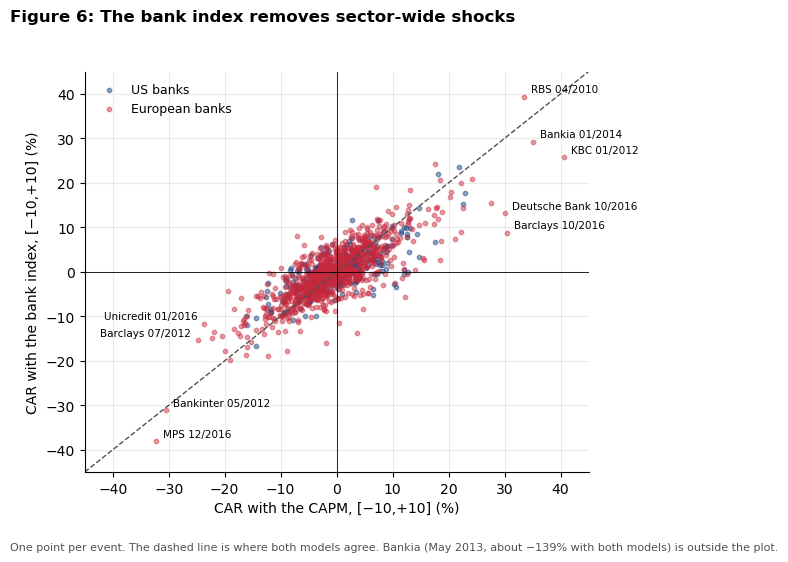

In [77]:
short = {"royal bank of sctl.gp.": "RBS", "banca monte dei paschi": "MPS", "bankinter 'r'": "Bankinter",
         "deutsche bank": "Deutsche Bank", "kbc group": "KBC"}
region_of = panel.groupby("ds_name")["region"].first()
pts = cmp.assign(region=cmp["ds_name"].map(region_of), x=100 * cmp["car_capm"], y=100 * cmp["car_bank"])

lim = 45
fig, ax = plt.subplots(figsize=(6.5, 5.2))
for r, (name, col) in REG.items():
    d = pts[pts["region"] == r]
    ax.scatter(d["x"], d["y"], s=10, alpha=0.45, color=col, label=name)
ax.plot([-lim, lim], [-lim, lim], color=C["grey"], ls="--", lw=1)
ax.axhline(0, color="black", lw=0.6)
ax.axvline(0, color="black", lw=0.6)

extremes = pd.concat([pts.nsmallest(5, "x"), pts.nlargest(5, "x")])

for _, e in extremes[extremes["x"].abs() < lim].iterrows():
    left = -25 < e["x"] < 0       
    ax.annotate(f"{short.get(e['ds_name'], e['ds_name'].title())} {e['trade_date']:%m/%Y}", (e["x"], e["y"]),
                xytext=(-5 if left else 5, 3), textcoords="offset points", fontsize=7.5, ha="right" if left else "left")

ax.set_xlim(-lim, lim)
ax.set_ylim(-lim, lim)
ax.set_xlabel("CAR with the CAPM, [−10,+10] (%)")
ax.set_ylabel("CAR with the bank index, [−10,+10] (%)")
ax.legend(frameon=False, loc="upper left", fontsize=9)
style([ax])
fig.suptitle("Figure 6: The bank index removes sector-wide shocks", x=0.01, y=1.0, ha="left", fontsize=12, fontweight="bold")
fig.text(0.01, -0.04, "One point per event. The dashed line is where both models agree. "
         "Bankia (May 2013, about −139% with both models) is outside the plot.", fontsize=8, color=C["grey"])
plt.show()

**comment:** 

Each point compares an event's CAR under the CAPM (horizontal axis) and under the bank index (vertical axis). Most events lie close to the diagonal, and the two measures are correlated at 0.85. The large CARs, however, tend to shrink towards zero: the cloud is flatter than the diagonal on both sides. These are sector-wide moves that the CAPM attributes to the bank. Deutsche Bank and Barclays in October 2016 fall from about +30% to +13% and +9%, KBC in January 2012 from +41% to +26%, and UniCredit in January 2016 and Barclays in July 2012 roughly halve. Bank-specific crises stay on or below the diagonal: Bankinter (−30% and −31%), Monte dei Paschi (−32% and −38%) and Bankia in May 2013 (about −139% with both, outside the plot). RBS in April 2010 even rises (+33% to +39%), as its stock outperformed the other banks.

In [78]:
region_of = panel.groupby("ds_name")["region"].first()
main = {key: s for key, s in studies.items() if key[0] in ("capm", "bank")}

for r, name in [("US", "US banks"), ("EU", "European banks")]:
    t = test_table(main, keep=lambda w, r=r: w["ds_name"].map(region_of) == r)
    print(f"\n{name}")
    print(t[["n", "mean", "median", "t_boehmer", "z_cowan", "t_date", "t_month"]].round(3).to_string())


US banks
                       n   mean  median  t_boehmer  z_cowan  t_date  t_month
model window sign                                                           
capm  1      neg   315.0  0.001  -0.000      0.521   -0.205   0.752    0.724
             pos    37.0 -0.004  -0.003     -1.736   -0.922  -0.903   -0.873
      5      neg   315.0  0.002   0.000      0.130    0.584   0.582    0.545
             pos    37.0 -0.003  -0.011     -0.825   -0.922  -0.508   -0.484
      10     neg   315.0  0.000  -0.001     -0.392    0.133   0.114    0.101
             pos    37.0 -0.005   0.002     -0.479    0.395  -0.549   -0.530
bank  1      neg   315.0  0.001   0.001      1.579    1.700   1.440    1.428
             pos    37.0 -0.002  -0.002     -1.197   -0.018  -0.631   -0.613
      5      neg   315.0  0.002   0.001      0.696    0.686   1.157    1.227
             pos    37.0  0.001   0.001      0.186    0.311   0.232    0.231
      10     neg   315.0  0.002  -0.001      0.410   -0.103   0.67

**Results by region:** We split the tests by region, for the CAPM and the bank benchmark (CARs are winsorised on the full sample before the split). This split was not planned before looking at the results, so we treat it as exploratory. For US banks, there is no effect for any window or model. For European banks, negative campaigns lower returns by about 0.2–0.3% on [−1,+1], significant with month-clustered errors under both the CAPM (t_month −2.39) and the bank benchmark (−2.74). On longer windows, the effect is not significant once clustered, and the negative reaction to positive campaigns is also entirely European.

In [79]:
eu = lambda w: w["ds_name"].map(region_of) == "EU"
eu_checks = {
    "baseline": test_table(studies, keep=eu),
    "clean": test_table(studies, keep=lambda w: eu(w) & (w["n_other"] == 0)),
    "raw": test_table(studies, keep=eu, col="car"),
    "no_stale": test_table(studies, keep=lambda w: eu(w) & ~w["ds_name"].isin(stale)),
}
keys_eu = [("capm", 1, "neg"), ("ff", 1, "neg"), ("mkt", 1, "neg"), ("bank", 1, "neg")]
print(pd.concat({name: t.loc[keys_eu, ["n", "mean", "t_month"]] for name, t in eu_checks.items()}, axis=1).round(4).to_string())

                  baseline                  clean                    raw                 no_stale                
                         n    mean t_month      n    mean t_month      n    mean t_month        n    mean t_month
model window sign                                                                                                
capm  1      neg     739.0 -0.0029 -2.3873  694.0 -0.0031 -2.4498  739.0 -0.0040 -2.3928    716.0 -0.0027 -2.1598
ff    1      neg     739.0 -0.0014 -1.4870  694.0 -0.0015 -1.6345  739.0 -0.0027 -1.8575    716.0 -0.0012 -1.3437
mkt   1      neg     739.0 -0.0025 -1.9621  694.0 -0.0029 -2.1591  739.0 -0.0036 -2.0434    716.0 -0.0022 -1.6892
bank  1      neg     739.0 -0.0022 -2.7445  694.0 -0.0022 -2.7078  739.0 -0.0033 -2.6414    716.0 -0.0020 -2.4057


**Robustness of the European result:** The effect on [−1,+1] holds when we drop events with other campaigns in the window, use raw CARs or drop banks with many zero-return days, under both the CAPM and the bank benchmark. It is weaker with β = 1 (t_month between −1.69 and −2.16) and not significant with Fama-French factors, where the mean is about halved. The pooled results therefore mix a short-lived effect for European banks with no effect for US banks.

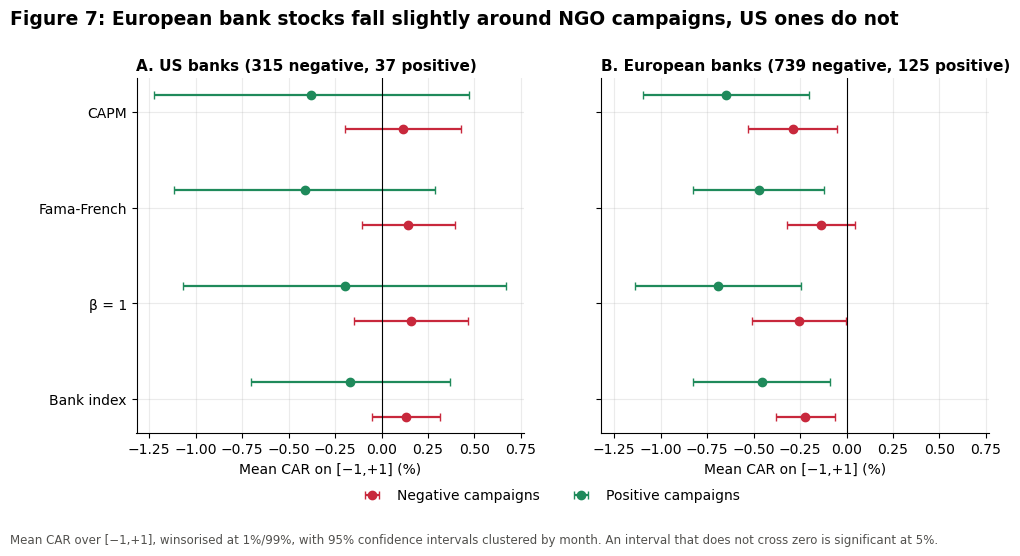

          model region sign  mean    lo    hi    n
0          CAPM     EU  neg -0.29 -0.53 -0.05  739
1          CAPM     EU  pos -0.65 -1.09 -0.20  125
2          CAPM     US  neg  0.12 -0.20  0.43  315
3          CAPM     US  pos -0.38 -1.22  0.47   37
4   Fama-French     EU  neg -0.14 -0.32  0.04  739
5   Fama-French     EU  pos -0.47 -0.82 -0.12  125
6   Fama-French     US  neg  0.15 -0.11  0.40  315
7   Fama-French     US  pos -0.41 -1.12  0.29   37
8         β = 1     EU  neg -0.25 -0.51 -0.00  739
9         β = 1     EU  pos -0.69 -1.14 -0.25  125
10        β = 1     US  neg  0.16 -0.15  0.46  315
11        β = 1     US  pos -0.20 -1.07  0.67   37
12   Bank index     EU  neg -0.22 -0.38 -0.06  739
13   Bank index     EU  pos -0.46 -0.83 -0.09  125
14   Bank index     US  neg  0.13 -0.05  0.32  315
15   Bank index     US  pos -0.17 -0.70  0.37   37


In [80]:
def mean_ci(y, groups):
    # mean and 95% confidence interval, with errors clustered by month
    fit = sm.OLS(y.to_numpy(), np.ones(len(y))).fit(cov_type="cluster", cov_kwds={"groups": pd.factorize(groups)[0]})
    m, se = fit.params[0], fit.bse[0]
    return 100 * m, 100 * (m - 1.96 * se), 100 * (m + 1.96 * se)


labels = {"capm": "CAPM", "ff": "Fama-French", "mkt": "β = 1", "bank": "Bank index"}
rows = []
for model, label in labels.items():
    w = winsorise(studies[(model, 1)])
    w["region"] = w["ds_name"].map(region_of)
    for (r, sign), d in w[w["sign"] != "neu"].groupby(["region", "sign"]):
        m, lo, hi = mean_ci(d["car_w"], d["trade_date"].dt.to_period("M"))
        rows.append({"model": label, "region": r, "sign": sign, "mean": m, "lo": lo, "hi": hi, "n": len(d)})
ci = pd.DataFrame(rows)

fig, axes = plt.subplots(1, 2, figsize=(11, 4.6), sharex=True, sharey=True)
y = np.arange(len(labels))
for ax, (r, title) in zip(axes, [("US", "A. US banks"), ("EU", "B. European banks")]):
    n = ci[ci["region"] == r].groupby("sign")["n"].first()
    for sign, shift, name in [("neg", 0.18, "Negative campaigns"), ("pos", -0.18, "Positive campaigns")]:
        d = ci[(ci["region"] == r) & (ci["sign"] == sign)].set_index("model").loc[list(labels.values())]
        ax.errorbar(d["mean"], y + shift, xerr=[d["mean"] - d["lo"], d["hi"] - d["mean"]],
                    fmt="o", ms=6, color=C[sign], capsize=3, lw=1.6, label=name)
    ax.axvline(0, color="black", lw=0.8)
    ax.set_yticks(y, list(labels.values()), fontsize=10)
    ax.set_title(f"{title} ({n['neg']} negative, {n['pos']} positive)", loc="left", fontweight="bold", fontsize=11)
    ax.set_xlabel("Mean CAR on [−1,+1] (%)")
axes[0].invert_yaxis()
style(axes)

handles, names = axes[0].get_legend_handles_labels()
fig.legend(handles, names, loc="lower center", ncol=2, frameon=False, bbox_to_anchor=(0.5, -0.07), fontsize=10)
fig.suptitle("Figure 7: European bank stocks fall slightly around NGO campaigns, US ones do not",
             x=0.01, y=1.03, ha="left", fontsize=13.5, fontweight="bold")
fig.text(0.01, -0.13, "Mean CAR over [−1,+1], winsorised at 1%/99%, with 95% confidence intervals clustered by month. "
         "An interval that does not cross zero is significant at 5%.", fontsize=8.5, color=C["grey"])
plt.show()
print(ci.round(2).to_string())

**Figure 7:** Each point is the mean CAR on [−1,+1] with its 95% confidence interval, clustered by month, for the four benchmarks. *US banks:* every interval crosses zero, for negative and positive campaigns alike. The point estimates for negative campaigns are even slightly positive (+0.12% to +0.22%). *European banks:* negative campaigns lower returns by 0.16% to 0.29%. The interval excludes zero with the CAPM (−0.29%, [−0.53%, −0.05%]) and the bank index (−0.22%, [−0.38%, −0.06%]), touches it with β = 1 and crosses it with Fama-French (−0.16%, [−0.36%, +0.04%]). Positive campaigns lower European returns by more, 0.46% to 0.69%, and the interval excludes zero under all four benchmarks, but it is wide because there are only 125 events. The figure summarises our main finding: there is no reaction for US banks, and a small, short-lived drop for European banks, after both negative and, surprisingly, positive campaigns.

# Part D

## Task 6: Do investors react to NGO campaigns, and which campaigns does it depend on?

Follows Krüger (2015). Uses `handoff/cars.csv`, the output of Part C (one row per event, returns in USD), so the tests here match Part C's. Fama-French CARs (`car_ff`) use the five-factor model from Part B.

**Hypotheses, fixed before testing:**
1. Negative campaigns lower returns (6.2).
2. Positive campaigns raise them (6.2).
3. Bank-specific campaigns matter more than multi-firm ones (6.3.1).
4. Prominent campaigns and high-reach NGOs matter more (6.3.2).
5. Climate campaigns react differently after COP21 (6.3.3).
6. Campaigns echoed in the press matter more (6.7).

**Main results:** the [−10, +10] window, the Boehmer t-statistic and the t-test clustered by date. The other windows and tests are support. Task 7 adds the political context, and the summary figure at the end of the notebook brings Parts C, 6 and 7 together.

## 6.1 Setup

In [81]:
PRE, POST = 10, 10                                                   # event window [t0-10, t0+10], as in Part C
COP21 = pd.Timestamp("2015-12-12")                                   # Paris Agreement

cars = pd.read_csv(OUT / "cars.csv", parse_dates=["trade_date"])     # Part C's output: one row per event
cars["post"] = cars["trade_date"] > COP21                            # campaign after COP21
cars["month"] = cars["trade_date"].dt.to_period("M").astype(str)     # for errors clustered by month
print(len(cars), cars["sign"].value_counts().to_dict())
print(f"{len(panel):,} bank-days | {panel['ds_name'].nunique()} banks | {len(cars):,} CARs")

1301 {'neg': 1054, 'pos': 162, 'neu': 85}
172,502 bank-days | 59 banks | 1,301 CARs


## 6.2 Do investors react? Negative vs positive campaigns

In [82]:
# winsorise each window at 1%/99% over all events, before splitting into groups (as in Part C)
for col in ["car", "car_1", "car_5", "car_ff"]:
    lo, hi = cars[col].quantile([0.01, 0.99])
    cars[col + "_win"] = cars[col].clip(lo, hi)

# check: negative campaigns on [-10,+10], N, mean and median in %
d = cars[cars["sign"] == "neg"]
y = d["car_win"]
n = len(d)
print(n, 100 * y.mean(), 100 * y.median())


1054 -0.38530343506549247 -0.663506317899485


In [83]:
# all tests for one group of events: same definitions as Part C's car_tests, so the numbers match
def group_tests(d, col="car_win", width=21):
    y, n = d[col], len(d)

    # Boehmer: each CAR in units of the bank's normal volatility (CAPM residual sd over the window)
    scar = y / (d["sigma"] * np.sqrt(width))
    t_boehmer = scar.mean() * np.sqrt(n) / scar.std()

    # Cowan: number of positive CARs against the share of positive residuals in normal times
    p = d["pos_share"].mean()
    z_cowan = ((y > 0).sum() - n * p) / np.sqrt(n * p * (1 - p))

    # t-tests on the mean, with errors clustered by event date and by month
    t_date = clustered_t(y, d["trade_date"])
    t_month = clustered_t(y, d["month"])
    
    return {"N": n, "Mean (%)": 100 * y.mean(), "Median (%)": 100 * y.median(), 
            "t_Boehmer": t_boehmer, "z_Cowan": z_cowan, "t_date": t_date, "t_month": t_month}

In [84]:
# each window: winsorised CAR column and number of days
WINDOWS = {"[-1,+1]": ("car_1_win", 3), "[-5,+5]": ("car_5_win", 11), "[-10,+10]": ("car_win", 21)}
SIGNS = {"Negative": "neg", "Positive": "pos", "Neutral": "neu"}

# one row per campaign tone and window
rows = []
for name, s in SIGNS.items():
    for w, (col, width) in WINDOWS.items():
        rows.append({"Group": name, "Window": w, **group_tests(cars[cars["sign"] == s], col, width)})

pd.DataFrame(rows).set_index(["Group", "Window"]).round(2)


N  Mean (%)  Median (%)  t_Boehmer  z_Cowan  t_date  \
Group    Window                                                              
Negative [-1,+1]    1054     -0.17       -0.25      -1.63    -2.22   -1.55   
         [-5,+5]    1054     -0.24       -0.42      -1.92    -2.04   -1.17   
         [-10,+10]  1054     -0.39       -0.66      -2.44    -1.91   -1.38   
Positive [-1,+1]     162     -0.59       -0.33      -3.38    -1.56   -2.72   
         [-5,+5]     162     -0.70       -1.10      -2.30    -2.19   -1.90   
         [-10,+10]   162     -0.50       -0.21      -1.05     0.17   -0.96   
Neutral  [-1,+1]      85      0.21        0.16       0.58     0.61    0.66   
         [-5,+5]      85      0.27        0.46       0.15     1.05    0.36   
         [-10,+10]    85      0.69        0.04       0.80     0.40    0.72   

                    t_month  
Group    Window              
Negative [-1,+1]      -1.67  
         [-5,+5]      -0.92  
         [-10,+10]    -0.99  
Positive [-1,+1]      -2.84  
         [-5,+5]      -1.74  
         [-10,+10]    -0.84  
Neutral  [-1,+1]       0.61  
         [-5,+5]       0.30  
         [-10,+10]     0.65

**Negative and positive campaigns:** Negative campaigns have a mean CAR of −0.39% on [−10, +10] (median −0.66%), so the sign fits the first hypothesis, but the effect is small. The tests disagree: Boehmer is significant (−2.44), but Cowan (−1.91) and the clustered t-tests (date −1.38, month −0.99) are not, so the evidence is weak once we allow for events that share dates.

Positive campaigns do not raise returns. On [−1, +1] their mean is −0.59%, significantly negative on Boehmer (−3.38) and on both clustered tests (−2.72 and −2.84), which goes against the second hypothesis, although it rests on only 162 events. Neutral campaigns (85) are slightly positive and not significant. One possible reading is that investors treat any NGO attention as a risk signal, whatever its tone. The tests use Part C's definitions, so these numbers match Part C.

## 6.3 Which campaigns matter?
We split within negative campaigns, because prominence and reach should push negative and positive campaigns in opposite directions. Positive campaigns follow, with small groups. A group being significant while another is not does not show that they differ, so each split has a gap test, and 6.4 tests all the characteristics together.

### 6.3.1 Number of firms named
Does a campaign aimed at one bank matter more than one naming many firms?

In [85]:
# 6.3.1: negative campaigns, and how many firms each one names
neg = cars[cars["sign"] == "neg"]
print(neg["n_targets"].describe())
print((neg["n_targets"] == 1).sum(), neg["n_targets"].between(2, 10).sum(), neg["mass"].sum())   # 1 firm, 2-10, more than 10

count    1054.000000
mean       10.360531
std         8.726454
min         1.000000
25%         4.000000
50%         8.000000
75%        14.000000
max        72.000000
Name: n_targets, dtype: float64
86 610 358


In [86]:
# the tests of group_tests for several groups at once, on [-10,+10] by default
def split_table(groups, col='car_win', width=21):
    rows = {name: group_tests(d, col, width) for name, d in groups.items()}
    return pd.DataFrame(rows).T.round(2)

split_table({
    "One firm": neg[neg["n_targets"] == 1],
    "2 to 10 firms": neg[neg["n_targets"].between(2, 10)],
    "More than 10 firms": neg[neg["mass"]],
})

,N,Mean (%),Median (%),t_Boehmer,z_Cowan,t_date,t_month
One firm,86.0,-0.68,-1.54,-1.40,-0.99,-0.81,-0.80
2 to 10 firms,610.0,-0.69,-0.64,-2.41,-1.68,-2.05,-1.63
More than 10 firms,358.0,0.20,-0.53,-0.39,-0.60,0.41,0.31


In [87]:
# 6.3.1 gap test: regress the CAR (in %) on a mass dummy; the coefficient is the gap between the two groups
d_neg = neg.assign(y=100*neg["car_win"], x=neg["mass"].astype(int))
groups = np.column_stack([pd.factorize(d_neg["trade_date"])[0], pd.factorize(d_neg["ds_name"])[0]])   # cluster by date and by bank
f = smf.ols("y ~ x", data=d_neg).fit(cov_type="cluster", cov_kwds={"groups": groups})
print(f.params["x"], f.tvalues["x"], f.pvalues["x"])                 # gap (pts), t, p

0.8921360644626714 1.5587800772139053 0.11904844116041916


In [88]:
# 6.3.1 for positive campaigns (small groups)
pos = cars[cars["sign"] == "pos"]
print(pos["n_targets"].describe())
print((pos["n_targets"] == 1).sum(), pos["n_targets"].between(2, 10).sum(), pos["mass"].sum())

split_table({
    "One firm": pos[pos["n_targets"] == 1],
    "2 to 10 firms": pos[pos["n_targets"].between(2, 10)],
    "More than 10 firms": pos[pos["mass"]],
})

count    162.000000
mean      10.240741
std        8.587008
min        1.000000
25%        5.000000
50%        8.000000
75%       13.000000
max       56.000000
Name: n_targets, dtype: float64
6 99 57


,N,Mean (%),Median (%),t_Boehmer,z_Cowan,t_date,t_month
One firm,6.0,-0.51,1.32,-0.60,0.83,-0.25,-0.25
2 to 10 firms,99.0,-0.58,0.08,-0.88,0.43,-0.80,-0.71
More than 10 firms,57.0,-0.36,-0.88,-0.45,-0.55,-0.47,-0.50


In [89]:
# 6.3.1 gap test for positive campaigns
d_pos = pos.assign(y=100*pos["car_win"], x=pos["mass"].astype(int))
groups = np.column_stack([pd.factorize(d_pos["trade_date"])[0], pd.factorize(d_pos["ds_name"])[0]])
f = smf.ols("y ~ x", data=d_pos).fit(cov_type="cluster", cov_kwds={"groups": groups})
print(f.params["x"], f.tvalues["x"], f.pvalues["x"])

0.21498116322459926 0.23391754965333725 0.815048988485553


**Number of firms named:** Campaigns naming 10 firms or fewer have lower CARs: −0.68% for one firm (N 86) and −0.69% for 2 to 10 firms (N 610, t date −2.05), against +0.20% for more than 10 firms (N 358). The direction fits the third hypothesis, but the gap of 0.89 points is not significant (t 1.56, p 0.12). Since one firm and 2 to 10 firms are almost the same, the data points to "not a mass campaign" rather than "bank-specific".

The mass group's mean of +0.20% hides a median of −0.53%, so a few large positive CARs pull it up, and the one-firm group is too small (86 events) for a firm conclusion. Positive campaigns show no pattern (gap 0.21 points, p 0.82).

### 6.3.2 Prominence and NGO reach
Are campaigns that mention the bank more prominently, or that come from NGOs with a wider reach, more damaging?

In [90]:
# 6.3.2: group sizes. Prominence: 1 = report only, 2 = elsewhere, 3 = first paragraph, 4 = headline
print(neg["prominence"].value_counts().sort_index())
print(neg["ngo_power"].round(2).value_counts().sort_index())         # reach of the strongest NGO, local (low) to global (high)

prominence
1    152
2    457
3    204
4    241
Name: count, dtype: int64
ngo_power
0.50      3
1.00    380
1.50    245
2.00     63
2.50    313
2.75     50
Name: count, dtype: int64


In [91]:
# gap between a group (x = True) and the rest, in points of CAR, with errors clustered by date and by bank
def diff_test(d,x):
    d = d.assign(y=100*d["car_win"], x = x.astype(int))
    groups = np.column_stack([pd.factorize(d["trade_date"])[0], pd.factorize(d["ds_name"])[0]])
    f = smf.ols("y ~ x", data = d).fit(cov_type="cluster", cov_kwds={"groups": groups})
    return {"Gap (pts)": f.params["x"], "t-value": f.tvalues["x"], "p-value": f.pvalues["x"]}

# 6.3.2: prominence
split_table({
    "Headline": neg[neg["prominence"] == 4],
    "First paragraph": neg[neg["prominence"] == 3],
    "Elsewhere or report only": neg[neg["prominence"] <= 2],
})

,N,Mean (%),Median (%),t_Boehmer,z_Cowan,t_date,t_month
Headline,241.0,-1.06,-1.14,-2.75,-2.03,-2.17,-1.84
First paragraph,204.0,0.18,-0.38,-0.51,-0.07,0.30,0.25
Elsewhere or report only,609.0,-0.31,-0.51,-1.21,-1.20,-0.82,-0.61


In [92]:
# headline vs all other negative campaigns
diff_test(neg, neg["prominence"] == 4)

{'Gap (pts)': np.float64(-0.8776736109697623),
 't-value': np.float64(-1.6474301781628158),
 'p-value': np.float64(0.09946965667358526)}

In [93]:
# 6.3.2: NGO reach, cut at 2.5 (international NGOs)
split_table({
    "High Reach (2.5+)": neg[neg["ngo_power"] >= 2.5],
    "Low Reach": neg[neg["ngo_power"] < 2.5],
})

,N,Mean (%),Median (%),t_Boehmer,z_Cowan,t_date,t_month
High Reach (2.5+),363.0,0.07,-1.01,-0.29,-1.96,0.13,0.11
Low Reach,691.0,-0.62,-0.49,-2.82,-0.94,-1.94,-1.52


In [94]:
# high-reach vs lower-reach NGOs
diff_test(neg, neg["ngo_power"] >= 2.5)

{'Gap (pts)': np.float64(0.6909738309100053),
 't-value': np.float64(1.0663938412591694),
 'p-value': np.float64(0.2862456445597067)}

**Positive campaigns:** the same splits by prominence and reach. The groups are small (27 headline events), so they are reported but not interpreted on their own.

In [95]:
# 6.3.2 for positive campaigns: group sizes
print(pos["prominence"].value_counts().sort_index())
print(pos["ngo_power"].round(2).value_counts().sort_index())

prominence
1    10
2    98
3    27
4    27
Name: count, dtype: int64
ngo_power
0.50     1
1.00    57
1.50    24
2.00     8
2.50    66
2.75     6
Name: count, dtype: int64


In [96]:
# positive campaigns by prominence
split_table({
    "Headline": pos[pos["prominence"] == 4],
    "First paragraph": pos[pos["prominence"] == 3],
    "Elsewhere or report only": pos[pos["prominence"] <= 2],
})

,N,Mean (%),Median (%),t_Boehmer,z_Cowan,t_date,t_month
Headline,27.0,-1.73,-3.20,-1.33,-0.75,-1.35,-1.35
First paragraph,27.0,-0.59,-1.45,-0.99,-0.79,-0.38,-0.36
Elsewhere or report only,108.0,-0.17,0.37,-0.07,0.98,-0.29,-0.27


In [97]:
# headline vs all other positive campaigns
diff_test(pos, pos["prominence"] == 4)

{'Gap (pts)': np.float64(-1.4719398924291947),
 't-value': np.float64(-1.19345719038964),
 'p-value': np.float64(0.2326903684815973)}

In [98]:
# positive campaigns by NGO reach
split_table({
    "High Reach (2.5+)": pos[pos["ngo_power"] >= 2.5],
    "Low Reach": pos[pos["ngo_power"] < 2.5],
})

,N,Mean (%),Median (%),t_Boehmer,z_Cowan,t_date,t_month
High Reach (2.5+),72.0,-0.96,-0.98,-1.72,-0.40,-1.24,-1.19
Low Reach,90.0,-0.13,0.22,0.08,0.58,-0.19,-0.17


In [99]:
# high-reach vs lower-reach NGOs, positive campaigns
diff_test(pos, pos["ngo_power"] >= 2.5)

{'Gap (pts)': np.float64(-0.8216024258560944),
 't-value': np.float64(-0.8313645290792382),
 'p-value': np.float64(0.4057677309266977)}

**Prominence and NGO reach:** Headline campaigns are the strongest group in Task 6, at −1.06% (N 241), and significant on every test except month clustering (Boehmer −2.75, Cowan −2.03, date −2.17, month −1.84). The effect does not fall steadily with prominence, though: first-paragraph campaigns are at +0.18% and the rest at −0.31%, and the gap between headline campaigns and the rest is only weakly significant (−0.88 points, t −1.65, p 0.10).

NGO reach goes against the fourth hypothesis: lower-reach NGOs have the larger effect (−0.62%, Boehmer −2.82, date −1.94), against +0.07% for high-reach NGOs, and the gap is not significant (0.69 points, p 0.29). High-reach campaigns have a median of −1.01% and a Cowan test of −1.96, so a few large positive CARs pull their mean up. Among positive campaigns, headline ones are at −1.73% (N 27) and no gap is significant. With this many comparisons, a p-value of 0.10 is weak evidence.

### 6.3.3 Climate campaigns and COP21
Did climate campaigns change more than other campaigns after COP21 (12 December 2015)? We compare the four groups and test the difference-in-differences.

In [100]:
# 6.3.3: group sizes, climate vs other issues, before and after COP21
print(pd.crosstab(neg["climate"], neg["post"]))

post     False  True 
climate              
False      446    249
True       163    196


In [101]:
# 6.3.3: the four groups of the difference-in-differences
split_table({
    "Climate before COP21": neg[neg["climate"] & ~neg["post"]],
    "Climate after COP21": neg[neg["climate"] & neg["post"]],
    "Other issues before COP21": neg[~neg["climate"] & ~neg["post"]],
    "Other issues after COP21": neg[~neg["climate"] & neg["post"]],
})

,N,Mean (%),Median (%),t_Boehmer,z_Cowan,t_date,t_month
Climate before COP21,163.0,-0.72,-0.63,-1.56,-1.28,-1.20,-1.14
Climate after COP21,196.0,-0.21,-0.00,-0.71,0.41,-0.26,-0.22
Other issues before COP21,446.0,-0.27,-0.65,-1.05,-0.95,-0.69,-0.55
Other issues after COP21,249.0,-0.51,-1.18,-1.82,-2.00,-0.92,-0.70


In [102]:
# difference-in-differences by hand: change for climate campaigns minus change for other campaigns
m = 100 * neg.groupby(["climate", "post"])["car_win"].mean()

climate_change = m.loc[True, True] - m.loc[True, False]
other_change = m.loc[False, True] - m.loc[False, False]

print(round(climate_change, 2), round(other_change, 2), round(climate_change - other_change, 2))

0.52 -0.24 0.76


In [103]:
# the same difference-in-differences as a regression: climate:post is the test of 6.3.3
d = neg.assign(y=100*neg["car_win"], climate=neg["climate"].astype(int), post=neg["post"].astype(int))
groups = np.column_stack([pd.factorize(d["trade_date"])[0], pd.factorize(d["ds_name"])[0]])
f = smf.ols("y ~ climate * post", data = d).fit(cov_type = "cluster", cov_kwds={"groups": groups})
pd.DataFrame({"Coefficients": f.params, "t-values": f.tvalues, "p-values": f.pvalues}).round(3)

,Coefficients,t-values,p-values
Intercept,-0.271,-0.844,0.399
climate,-0.450,-0.620,0.535
post,-0.240,-0.401,0.688
climate:post,0.756,0.695,0.487


In [104]:
# 6.3.3 for positive campaigns (small groups)
split_table({
    "Climate before COP21": pos[pos["climate"] & ~pos["post"]],
    "Climate after COP21": pos[pos["climate"] & pos["post"]],
    "Other issues before COP21": pos[~pos["climate"] & ~pos["post"]],
    "Other issues after COP21": pos[~pos["climate"] & pos["post"]],
})

,N,Mean (%),Median (%),t_Boehmer,z_Cowan,t_date,t_month
Climate before COP21,46.0,-0.94,-0.34,-1.32,0.20,-1.08,-0.96
Climate after COP21,31.0,-2.08,-1.66,-2.03,-0.30,-1.68,-1.68
Other issues before COP21,46.0,-0.28,-0.36,-0.16,-0.12,-0.25,-0.23
Other issues after COP21,39.0,1.01,0.98,1.03,0.52,1.11,1.05


In [105]:
# 6.3.3 difference-in-differences for positive campaigns
d = pos.assign(y=100*pos["car_win"], climate=pos["climate"].astype(int), post=pos["post"].astype(int))
groups = np.column_stack([pd.factorize(d["trade_date"])[0], pd.factorize(d["ds_name"])[0]])
f = smf.ols("y ~ climate * post", data = d).fit(cov_type = "cluster", cov_kwds={"groups": groups})
pd.DataFrame({"Coefficients": f.params, "t-values": f.tvalues, "p-values": f.pvalues}).round(3)

,Coefficients,t-values,p-values
Intercept,-0.276,-0.250,0.803
climate,-0.662,-0.444,0.657
post,1.282,0.919,0.358
climate:post,-2.420,-1.134,0.257


#### Figure 8: COP21, climate vs other campaigns
Mean CAR on [−10, +10] before and after COP21, by issue. Red is negative and navy positive campaigns, and the line style shows the issue. The chart shows means only; the tests are the difference-in-differences regressions above.

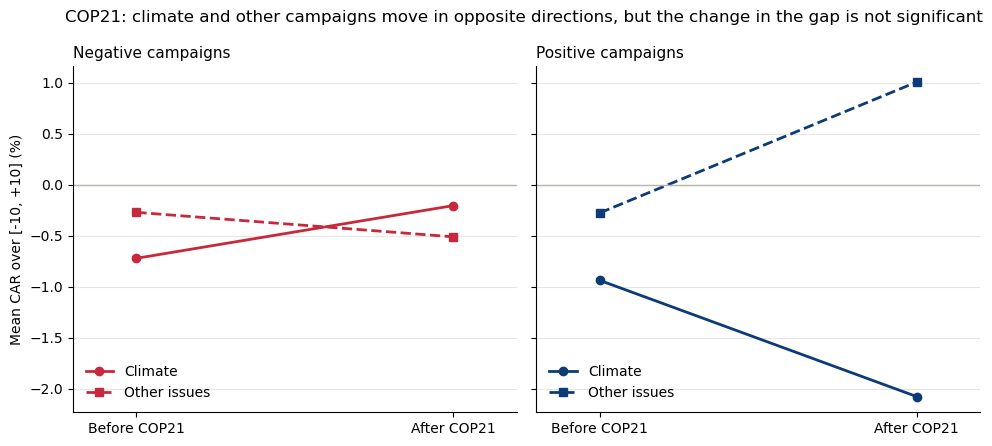

In [106]:
# Figure 8: mean CAR before and after COP21. Colour shows the tone (red = negative, navy = positive), line style the issue
TONE = {"neg": ("Negative campaigns", "#c8283c"), "pos": ("Positive campaigns", "#0d3b78")}

fig, axes = plt.subplots(1, 2, figsize=(10, 4.5), sharey=True)
for ax, (s, d) in zip(axes, [("neg", neg), ("pos", pos)]):
    title, col = TONE[s]
    for climate, label, ls, marker in [(True, "Climate", "-", "o"), (False, "Other issues", "--", "s")]:
        m = 100 * d[d["climate"] == climate].groupby("post")["car_win"].mean()     # before (False) and after (True) COP21
        ax.plot([0, 1], m.to_numpy(), color=col, ls=ls, lw=2, marker=marker, ms=6, label=label)
    ax.axhline(0, color="#b7b5ad", lw=1)
    ax.set_xticks([0, 1], ["Before COP21", "After COP21"])
    ax.set_xlim(-0.2, 1.2)
    ax.set_title(title, loc="left", fontsize=11)
    ax.grid(axis="y", color="#e8e6df", lw=0.8)
    ax.set_axisbelow(True)
    ax.spines[["top", "right"]].set_visible(False)
    ax.legend(frameon=False, loc="lower left")
axes[0].set_ylabel("Mean CAR over [-10, +10] (%)")
fig.suptitle("COP21: climate and other campaigns move in opposite directions, but the change in the gap is not significant",
             x=0.07, ha="left", fontsize=12)
fig.tight_layout()
plt.show()


**Climate campaigns and COP21:** Among negative campaigns, climate campaigns go from −0.72% before COP21 to −0.21% after, while other campaigns go from −0.27% to −0.51%. This difference-in-differences of +0.76 points is not significant (t 0.70, p 0.49), and stays insignificant with the other characteristics held constant (0.85, see 6.4).

Positive campaigns move the other way (climate from −0.94% to −2.08%, other issues from −0.28% to +1.01%), which is why the two tones are not pooled, but this difference of −2.42 points is not significant either (t −1.13, p 0.26) and rests on groups of 31 to 46 events. The campaigns and banks targeted after 2015 may differ, and the period after COP21 also contains the 2016 US election, so this cannot show that COP21 caused any change.

### 6.3.4 Extension: the Trump effect
We treat the Trump effect as additional exploratory task. We use the same difference-in-differences as for COP21, with the US election (8 November 2016) as the break: did climate campaigns change more than other campaigns?

In [107]:
TRUMP = pd.Timestamp("2016-11-08")                           # Trump election

# the four groups of the difference-in-differences, with the election as the break
def trump_groups(d):
    after = d["trade_date"] > TRUMP
    return{
        "Climate before election": d[d["climate"] & ~after],
        "Climate after election": d[d["climate"] & after],
        "Other issues before election": d[~d["climate"] & ~after],
        "Other issues after election": d[~d["climate"] & after]
    }

split_table(trump_groups(neg))

,N,Mean (%),Median (%),t_Boehmer,z_Cowan,t_date,t_month
Climate before election,206.0,-0.37,-0.28,-0.97,-0.40,-0.54,-0.53
Climate after election,153.0,-0.54,-0.41,-1.12,-0.40,-0.67,-0.66
Other issues before election,511.0,-0.03,-0.39,-0.40,-0.33,-0.07,-0.06
Other issues after election,184.0,-1.27,-1.78,-3.61,-3.25,-2.75,-2.42


In [108]:
# difference-in-differences regression for the election: climate:post_trump is the test
def trump_did(d):
    d = d.assign(y = 100*d["car_win"],
                 climate = d["climate"].astype(int),
                 post_trump = (d["trade_date"] > TRUMP).astype(int))
    groups = np.column_stack([pd.factorize(d["trade_date"])[0], pd.factorize(d["ds_name"])[0]])   # cluster by date and by bank
    f = smf.ols("y ~ climate * post_trump", data = d).fit(cov_type = "cluster", cov_kwds={"groups": groups})
    return pd.DataFrame({"Coefficients": f.params, "t-values": f.tvalues, "p-values": f.pvalues}).round(3)

In [109]:
# negative campaigns
trump_did(neg)

,Coefficients,t-values,p-values
Intercept,-0.029,-0.084,0.933
climate,-0.339,-0.386,0.699
post_trump,-1.240,-2.187,0.029
climate:post_trump,1.071,0.806,0.420


In [110]:
# positive campaigns (small groups)
split_table(trump_groups(pos))

,N,Mean (%),Median (%),t_Boehmer,z_Cowan,t_date,t_month
Climate before election,58.0,-1.00,0.41,-1.27,0.75,-1.13,-1.06
Climate after election,19.0,-2.62,-2.93,-2.83,-1.39,-2.65,-2.38
Other issues before election,55.0,0.14,0.58,0.19,0.28,0.15,0.14
Other issues after election,30.0,0.62,0.06,0.65,0.08,0.56,0.52


In [111]:
# positive campaigns
trump_did(pos)

,Coefficients,t-values,p-values
Intercept,0.142,0.154,0.878
climate,-1.138,-0.870,0.384
post_trump,0.480,0.349,0.727
climate:post_trump,-2.103,-1.155,0.248


#### Figure 9: Before and after the 2016 US election
Mean CAR on [−10, +10] with 95% confidence intervals clustered by date, by issue. Red is negative and navy positive campaigns, the line style shows the issue, and N is shown above each interval.

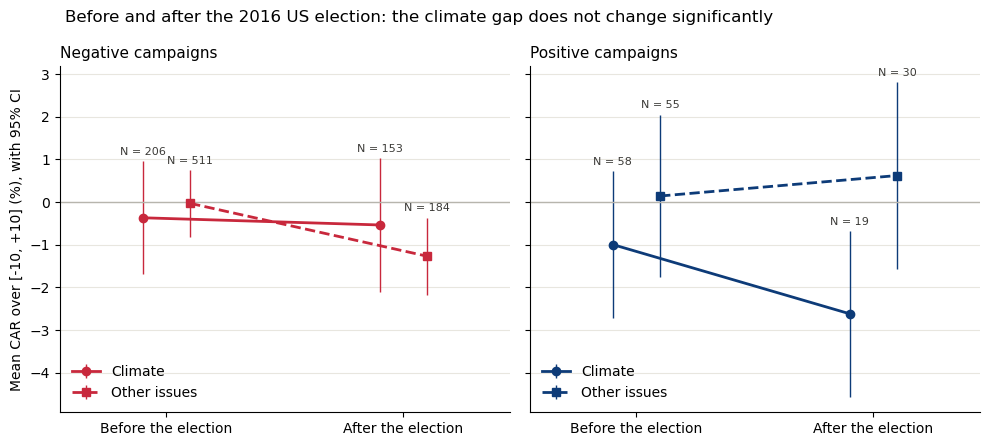

In [112]:
# mean CAR (in %) of a group, with a 95% confidence interval clustered by date, and its N
def group_ci(d, col="car_win"):
    f = sm.OLS(100 * d[col].to_numpy(), np.ones(len(d))).fit(cov_type="cluster", cov_kwds={"groups": pd.factorize(d["trade_date"])[0]})
    return f.params[0], 1.96 * f.bse[0], len(d)

TRUMP = pd.Timestamp("2016-11-08")

# Figure 9: colour shows the tone (red = negative, navy = positive), line style the issue
TONE = {"neg": ("Negative campaigns", "#c8283c"), "pos": ("Positive campaigns", "#0d3b78")}

fig, axes = plt.subplots(1, 2, figsize=(10, 4.5), sharey=True)
for ax, (s, d) in zip(axes, [("neg", neg), ("pos", pos)]):
    title, col = TONE[s]
    after = d["trade_date"] > TRUMP
    for climate, label, ls, marker, shift in [(True, "Climate", "-", "o", -0.1), (False, "Other issues", "--", "s", 0.1)]:
        groups = [d[(d["climate"] == climate) & ~after], d[(d["climate"] == climate) & after]]
        m, ci, n = zip(*[group_ci(g) for g in groups])
        x = np.array([0, 1]) + shift                                  # shift the two lines apart so the intervals don't overlap
        ax.errorbar(x, m, yerr=ci, color=col, ls=ls, lw=2, marker=marker, ms=6, elinewidth=1, label=label)
        for xi, top, ni in zip(x, np.array(m) + np.array(ci), n):    # N above each interval
            ax.annotate(f"N = {ni}", (xi, top), xytext=(0, 3), textcoords="offset points",
                        ha="center", va="bottom", fontsize=8, color="#3a3936")
    ax.axhline(0, color="#b7b5ad", lw=1)
    ax.set_xticks([0, 1], ["Before the election", "After the election"])
    ax.set_xlim(-0.45, 1.45)
    ax.set_title(title, loc="left", fontsize=11)
    ax.grid(axis="y", color="#e8e6df", lw=0.8)
    ax.set_axisbelow(True)
    ax.spines[["top", "right"]].set_visible(False)
    ax.legend(frameon=False, loc="lower left")
axes[0].set_ylabel("Mean CAR over [-10, +10] (%), with 95% CI")
fig.suptitle("Before and after the 2016 US election: the climate gap does not change significantly", x=0.07, ha="left", fontsize=12)
fig.tight_layout()
plt.show()


**The Trump effect:** There is no climate-specific effect of the election: `climate:post_trump` is 1.07 for negative campaigns (t 0.81, p 0.42) and −2.10 for positive ones (t −1.16, p 0.25). The surprise is that negative campaigns on other issues fall to −1.27% after the election, significant on every test (Boehmer −3.61, Cowan −3.25, date −2.75, month −2.42, and `post_trump` −1.24 with p 0.03).

The election came only 11 months after COP21, so the two periods largely overlap, yet the test is inable to properly separate them. Positive climate campaigns after the election are also only 19 events.

### 6.3.5 All splits together

#### Figure 10: All splits of negative campaigns
Mean CAR on [−10, +10] for each group in 6.3, with 95% confidence intervals clustered by date. An interval that crosses zero means the group's mean is close to the zero value. Overlapping intervals do not test whether two groups differ: the gap tests and 6.4 do.

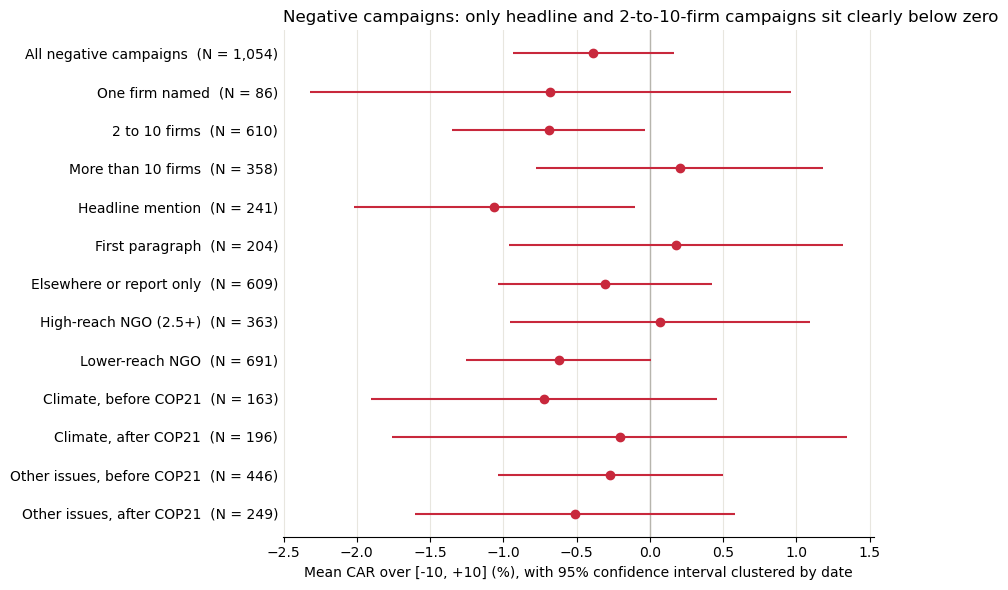

In [113]:
# Figure 10: every split of negative campaigns, mean CAR with a 95% confidence interval clustered by date
FOREST = {
    "All negative campaigns": neg,
    "One firm named": neg[neg["n_targets"] == 1],
    "2 to 10 firms": neg[neg["n_targets"].between(2, 10)],
    "More than 10 firms": neg[neg["mass"]],
    "Headline mention": neg[neg["prominence"] == 4],
    "First paragraph": neg[neg["prominence"] == 3],
    "Elsewhere or report only": neg[neg["prominence"] <= 2],
    "High-reach NGO (2.5+)": neg[neg["ngo_power"] >= 2.5],
    "Lower-reach NGO": neg[neg["ngo_power"] < 2.5],
    "Climate, before COP21": neg[neg["climate"] & ~neg["post"]],
    "Climate, after COP21": neg[neg["climate"] & neg["post"]],
    "Other issues, before COP21": neg[~neg["climate"] & ~neg["post"]],
    "Other issues, after COP21": neg[~neg["climate"] & neg["post"]],
}
res = pd.DataFrame({k: group_ci(d) for k, d in FOREST.items()}, index=["mean", "ci", "n"]).T
y = np.arange(len(res))[::-1]                                         # first group at the top

fig, ax = plt.subplots(figsize=(9, 6))
ax.axvline(0, color="#b7b5ad", lw=1)
ax.errorbar(res["mean"], y, xerr=res["ci"], fmt="o", color="#c8283c", ms=6, lw=1.5, capsize=0)   # red = negative campaigns
ax.set_yticks(y, [f"{k}  (N = {int(n):,})" for k, n in zip(res.index, res["n"])])
ax.set_xlabel("Mean CAR over [-10, +10] (%), with 95% confidence interval clustered by date")
ax.set_title("Negative campaigns: only headline and 2-to-10-firm campaigns sit clearly below zero", loc="left", fontsize=12)
ax.grid(axis="x", color="#e8e6df", lw=0.8)
ax.set_axisbelow(True)
ax.spines[["top", "right", "left"]].set_visible(False)
ax.tick_params(axis="y", length=0)
fig.tight_layout()
plt.show()


**All splits together:** Only headline campaigns (−1.06%) and campaigns naming 2 to 10 firms (−0.69%) have intervals entirely below zero, and lower-reach NGOs (−0.62%) just reach zero. All other groups cross zero, including all negative campaigns together (−0.39%), and small groups such as one firm named (N 86) and the climate groups have wide intervals.

## 6.4 Do the groups really differ? Test on a regression
We regress the winsorised CAR (in %) on all the campaign characteristics at once, with errors clustered by date and by bank. This tests whether the groups in 6.3 really differ, holding the other characteristics constant. Column (2), negative campaigns on [−10, +10], is the main specification, and `climate` and `post` enter with their interaction.

In [114]:
# all campaign characteristics in one regression; region is text, so it enters as a US vs EU dummy
RHS = "sentiment + climate * post + prominence + ngo_power + mass + region"

# CAR in % on the characteristics, errors clustered by date and by bank
def run_reg(col, d):
    d = d.assign(y=100 * d[col], climate=d["climate"].astype(int), post=d["post"].astype(int), mass=d["mass"].astype(int))
    groups = np.column_stack([pd.factorize(d["trade_date"])[0], pd.factorize(d["ds_name"])[0]])
    return smf.ols(f"y ~ {RHS}", data=d).fit(cov_type="cluster", cov_kwds={"groups": groups})

# main specification: negative campaigns, [-10,+10]
f = run_reg("car_win", neg)
pd.DataFrame({"Coefficients": f.params, "t-values": f.tvalues, "p-values": f.pvalues}).round(3)

,Coefficients,t-values,p-values
Intercept,-0.371,-0.250,0.802
region[T.US],0.485,1.186,0.235
sentiment,-0.012,-0.027,0.979
climate,-0.557,-0.701,0.483
post,-0.568,-0.868,0.385
climate:post,0.851,0.775,0.438
prominence,-0.213,-0.824,0.410
ngo_power,0.227,0.476,0.634
mass,0.706,1.183,0.237


In [115]:
# the same regression on other samples, windows and models
SPECS = {
    "(1) All, [-10,+10]": ("car_win", cars),
    "(2) Negative [-10,+10]": ("car_win", neg),
    "(3) Negative [-5,+5]": ("car_5_win", neg),
    "(4) Negative, Fama-French": ("car_ff_win", neg),
    "(5) Positive, [-10,+10]": ("car_win", pos),
}

fits = {name: run_reg(col, d) for name, (col, d) in SPECS.items()}

# coefficient (t-statistic) for each specification
reg = pd.DataFrame({name: {v: f"{f.params[v]:.3f} ({f.tvalues[v]:.3f})" for v in f.params.index} 
                   for name, f in fits.items()})

reg.loc["N"] = {name: f"{int(f.nobs):,}" for name, f in fits.items()}
reg.loc["R-squared"] = {name: f"{f.rsquared:.3f}" for name, f in fits.items()}
reg

,"(1) All, [-10,+10]","(2) Negative [-10,+10]","(3) Negative [-5,+5]","(4) Negative, Fama-French","(5) Positive, [-10,+10]"
Intercept,-0.079 (-0.073),-0.371 (-0.250),-1.479 (-1.285),-0.484 (-0.400),1.462 (0.528)
region[T.US],0.608 (1.699),0.485 (1.186),0.491 (1.492),0.557 (1.439),0.503 (0.514)
sentiment,0.027 (0.159),-0.012 (-0.027),0.038 (0.098),-0.528 (-1.640),-0.117 (-0.088)
climate,-0.298 (-0.405),-0.557 (-0.701),0.264 (0.442),-0.201 (-0.273),-0.503 (-0.338)
post,-0.435 (-0.709),-0.568 (-0.868),-0.000 (-0.001),-1.221 (-2.901),1.191 (0.842)
climate:post,0.339 (0.320),0.851 (0.775),-0.219 (-0.315),0.442 (0.509),-2.748 (-1.257)
prominence,-0.299 (-1.195),-0.213 (-0.824),0.061 (0.268),-0.192 (-0.845),-0.208 (-0.365)
ngo_power,0.250 (0.574),0.227 (0.476),0.450 (1.376),0.089 (0.250),-0.578 (-0.706)
mass,0.401 (0.797),0.706 (1.183),0.539 (1.107),0.057 (0.105),-0.381 (-0.374)
N,"1,301","1,054","1,054","1,054",162


**Regression:** In the main specification, column (2), no characteristic is significant: prominence −0.21 (t −0.82), NGO reach 0.23 (t 0.48), mass 0.71 (t 1.18), `climate:post` 0.85 (t 0.78) and US banks 0.49 (t 1.19). This confirms the gap tests: the differences seen in 6.3 are not significant once tested together, and the characteristics explain almost none of the variation in CARs (R² under 1.1% in the negative columns). Column (2) is the main result because pooling negative and positive campaigns, as in column (1), mixes effects of opposite sign, and the positive column (5) has only 162 events and nothing significant.

The results are not stable across specifications: `climate:post` changes sign (0.85, −0.22 and 0.44 in columns 2 to 4), and so does prominence in column (3). Prominence also enters as a straight line from 1 to 4, while the headline effect was not a steady pattern, so a headline dummy would be a useful check. In the five-factor column (4), `post` is −1.22 (t −2.90), the only significant coefficient, so negative campaigns after COP21 have lower FF5 CARs; with this many coefficients, it should be treated with caution.

## 6.5 Main figure: when does the market react?
The average cumulative abnormal return from day −10 to +10 shows when the reaction happens. `cars.csv` has no daily path, so we rebuild the daily ARs from B's betas and check that they add up to Part C's CARs.

In [ ]:
# each event's day number t0 in the bank's trading days, to rebuild the daily ARs (cars.csv has no daily path)
t0 = cars.merge(panel[["ds_name", "date", "t"]], left_on=["ds_name", "trade_date"],
                right_on=["ds_name", "date"], how="left", validate="1:1")["t"]
print(t0.isna().sum())                                               # check: 0, every event found its day

0


In [ ]:
# daily abnormal returns from t0-10 to t0+10, with the CAPM parameters at t0 held fixed (as in Part C)
params = betas.set_index(["ds_name", "t"])[["capm_alpha", "capm_mkt_rf"]]
by_bank = {name: d.set_index("t") for name, d in panel.groupby("ds_name")}

paths = []
for name, t in zip(cars["ds_name"], t0.astype(int)):
    win = by_bank[name].loc[t - PRE:t + POST]
    alpha, beta = params.loc[(name, t)]
    paths.append((win["exret"] - (alpha + beta * win["mkt_rf"])).to_numpy())

ar = np.vstack(paths)                                                # one row per event, one column per day
print(ar.shape)
print(np.abs(ar.sum(axis=1) - cars["car"]).max())                    # check: about 0, the daily ARs add up to Part C's CARs

(1301, 21)
9.8879238130678e-17


In [118]:
# cumulative AR by day, winsorised day by day so that day +10 matches the means of the main table
days = np.arange(-PRE, POST + 1)
cum = ar.cumsum(axis=1)
lo, hi = np.quantile(cum, [0.01, 0.99], axis=0)
cum_w = np.clip(cum, lo, hi)

In [119]:
# mean cumulative AR (in %) and its standard error clustered by date, for each day
def path_stats(mask):
    dates = pd.factorize(cars.loc[mask, "trade_date"])[0]
    fits = [sm.OLS(100 * cum_w[mask, j], np.ones(mask.sum())).fit(cov_type="cluster", cov_kwds={"groups": dates})
            for j in range(len(days))]
    return np.array([f.params[0] for f in fits]), np.array([f.bse[0] for f in fits])

# red = negative, navy = positive (as in Figures 8-10)
STYLE = {"neg": ("Negative campaigns", "#c8283c", "-"), "pos": ("Positive campaigns", "#0d3b78", "--")}
path = {s: path_stats((cars["sign"] == s).to_numpy()) for s in STYLE}

pd.DataFrame({STYLE[s][0]: {f"Day {d:+d}": path[s][0][d + PRE] for d in (-10, -5, -1, 0, 1, 5, 10)} for s in STYLE}).round(2).T

,Day -10,Day -5,Day -1,Day +0,Day +1,Day +5,Day +10
Negative campaigns,0.02,0.05,0.06,0.04,-0.10,-0.18,-0.39
Positive campaigns,-0.10,0.10,-0.17,-0.18,-0.53,-0.70,-0.50


#### Figure 11: Cumulative abnormal returns around the campaign
Mean cumulative AR from day −10 to +10, negative (red, solid) against positive (navy, dashed) campaigns, with 95% bands clustered by date.

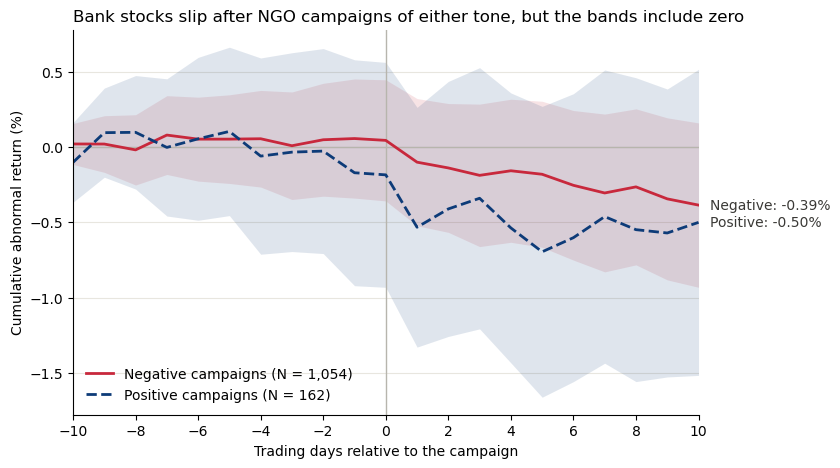

In [120]:
# Figure 11: mean cumulative AR from day -10 to +10, negative vs positive, with 95% bands clustered by date
fig, ax = plt.subplots(figsize=(9, 5))
ax.axhline(0, color="#b7b5ad", lw=1)
ax.axvline(0, color="#b7b5ad", lw=1)                                 # event day

for s, (label, col, ls) in STYLE.items():
    m, se = path[s]
    n = (cars["sign"] == s).sum()
    ax.fill_between(days, m - 1.96 * se, m + 1.96 * se, color=col, alpha=0.13, lw=0)
    ax.plot(days, m, color=col, ls=ls, lw=2, label=f"{label} (N = {n:,})")
    ax.annotate(f"{label.split()[0]}: {m[-1]:.2f}%", (days[-1], m[-1]), xytext=(8, 0),     # value at day +10
                textcoords="offset points", va="center", fontsize=10, color="#3a3936")

ax.set_xlim(-10, 10)
ax.set_xticks(range(-10, 11, 2))
ax.set_xlabel("Trading days relative to the campaign")
ax.set_ylabel("Cumulative abnormal return (%)")
ax.set_title("Bank stocks slip after NGO campaigns of either tone, but the bands include zero", loc="left", fontsize=12)
ax.grid(axis="y", color="#e8e6df", lw=0.8)
ax.set_axisbelow(True)
ax.spines[["top", "right"]].set_visible(False)
ax.legend(frameon=False, loc="lower left")
fig.subplots_adjust(right=0.82)                                      # room for the labels on the right
plt.show()

**Timing of the reaction:** There is no drift before the campaign: the negative line stays close to zero until day 0 (+0.02% on day −10, +0.06% on day −1), so there is no sign of leakage. Negative campaigns move from day +1 (−0.10%) and drift to −0.39% by day +10, while positive campaigns drop on day +1 (−0.53%) and end at −0.50%. Sigwatch's `date` is when the action was entered in its database, not the publication date, which may explain why the move shows on day +1 rather than day 0.

Both bands include zero on every day, in line with the date-clustered t-statistics (−1.38 and −0.96). Since both lines fall and the bands overlap, there is no evidence that the market reacts differently to negative and positive campaigns.

## 6.6 Robustness
We rerun the key groups under Part C's checks, on [−10, +10]: Fama-French five-factor CARs, β = 1, raw (unwinsorised) CARs, clean windows (no other campaign on the same bank inside the window, `n_other == 0`) and no stale-price banks. Part C reports other overlap gaps for negative vs positive campaigns. They would need a new sample here, so we don't repeat them for the splits.

In [ ]:
# market-adjusted model (beta = 1): abnormal return = bank excess return - market excess return
car_mkt = []
for name, t in zip(cars["ds_name"], t0.astype(int)):
    win = by_bank[name].loc[t - PRE:t + POST]
    car_mkt.append((win["exret"] - win["mkt_rf"]).sum())
cars["car_mkt"] = car_mkt

lo, hi = cars["car_mkt"].quantile([0.01, 0.99])
cars["car_mkt_win"] = cars["car_mkt"].clip(lo, hi)

print(100 * cars.loc[cars["sign"] == "neg", "car_mkt_win"].mean())   # check: negative campaigns, in %

-0.43310465608031995


In [122]:
# key groups from 6.2 and 6.3
GROUPS = {
    "All negative": cars["sign"] == "neg",
    "All positive": cars["sign"] == "pos",
    "Negative, headline": (cars["sign"] == "neg") & (cars["prominence"] == 4),
    "Negative, 10 firms or fewer": (cars["sign"] == "neg") & ~cars["mass"],
    "Negative, lower-reach NGO": (cars["sign"] == "neg") & (cars["ngo_power"] < 2.5),
    "Negative, climate after COP21": (cars["sign"] == "neg") & cars["climate"] & cars["post"],
}
# each check: CAR column and which events to keep (True = all). stale comes from Part C
CHECKS = {
    "Baseline": ("car_win", True),
    "Fama-French": ("car_ff_win", True),
    "Beta = 1": ("car_mkt_win", True),
    "Raw CARs": ("car", True),
    "Clean windows": ("car_win", cars["n_other"] == 0),
    "No stale banks": ("car_win", ~cars["ds_name"].isin(stale)),
}

In [123]:
# every group under every check, on [-10,+10]. Boehmer and Cowan are left out because sigma and pos_share are CAPM only
rows = []
for g, mask in GROUPS.items():
    for c, (col, keep) in CHECKS.items():
        d = cars[mask & keep]
        rows.append({"Group": g, "Check": c, "N": len(d), "Mean (%)": 100 * d[col].mean(),
                     "t date": clustered_t(d[col], d["trade_date"]), "t month": clustered_t(d[col], d["month"])})
robust = pd.DataFrame(rows)

# one table per statistic, groups as rows and checks as columns
def show(value):
    return robust.pivot(index="Group", columns="Check", values=value).reindex(index=list(GROUPS), columns=list(CHECKS)).round(2)

show("Mean (%)")


Check,Baseline,Fama-French,Beta = 1,Raw CARs,Clean windows,No stale banks
Group,,,,,,
All negative,-0.39,-0.33,-0.43,-0.48,-0.52,-0.32
All positive,-0.50,-0.30,-0.41,-0.49,-0.33,-0.63
"Negative, headline",-1.06,-0.59,-1.37,-1.59,-1.40,-0.97
"Negative, 10 firms or fewer",-0.69,-0.31,-0.91,-0.88,-1.06,-0.61
"Negative, lower-reach NGO",-0.62,-0.46,-0.70,-0.79,-0.47,-0.53
"Negative, climate after COP21",-0.21,-0.72,0.03,-0.23,-0.59,-0.24


**Robustness:** Fama-French changes the results only a little: for negative campaigns on [−10,+10] the mean goes from −0.39% under CAPM to −0.33%, and for positive campaigns on [−1,+1] from −0.59% to −0.46%. Across all checks, the mean for all negative campaigns stays between −0.32% and −0.52% and its date-clustered t between −1.16 and −1.58, so it is never significant at 5%.

Headline campaigns are the most stable group: significant on date clustering under the baseline (−2.17), β = 1 (−2.88) and raw CARs (−2.04), just below 1.96 with clean windows (−1.91) and without stale banks (−1.97), and at −1.40 under Fama-French. With month clustering, only β = 1 is significant (−2.44). Campaigns naming 10 firms or fewer are significant under the baseline, β = 1, raw CARs and clean windows (−2.61), but not under Fama-French (−1.15), and climate campaigns after COP21 are never significant (Fama-French −0.72%, t −1.26).

Removing events with another campaign in the window makes the means larger (all negative −0.52%, headline −1.40%, 10 firms or fewer −1.06%), so other campaigns do not explain the effect, although N roughly halves. Part C's overlap-gap table is not repeated here: its five-factor negative results stay insignificant at every gap.

## 6.7 Add-on: press echo (#1)
In this part we check whether the market reacts more when the press picks up the campaign. Part A's `final_pool.csv` lists the press articles accepted as relevant to a campaign and a bank, with the day of each article relative to the campaign. An event counts as echoed if an accepted article names its bank from day 0 to day +7, the definition used in Part A. The articles are licensed Factiva content, so the cell reads only the campaign, bank and day columns, shows only counts and means, and skips itself if the file is not there. This is the test of the sixth hypothesis.

The file lists echoed campaigns only, not every campaign that Part A searched, so the comparison group mixes campaigns searched without an echo and campaigns never searched.

In [ ]:
# 6.7: press echo from Part A. final_pool.csv has one row per accepted press article; only the campaign, bank and
# day columns are read (the text is licensed Factiva content). An event is echoed if an article names its bank from day 0 to +7
POOL = OUT / "final_pool.csv"

if not POOL.exists():
    print("Echo file not available (licensed Factiva data, see Part D): 6.7 is skipped.")
else:
    pool = pd.read_csv(POOL, dtype={"uid_archive": str}, keep_default_na=False,
                       usecols=["uid_archive", "banks_relevant", "relative_day", "source_type"])
    post7 = pool[pool["source_type"].eq("press") & pool["relative_day"].between(0, 7)]
    echoed = (post7.assign(ds_name=post7["banks_relevant"].str.split(";")).explode("ds_name")
              .assign(ds_name=lambda d: d["ds_name"].str.strip().str.casefold())     # same bank key as cars
              [["uid_archive", "ds_name"]].drop_duplicates().assign(echo=1))

    # an event is echoed if any of its campaigns is echoed for that bank
    links = (cars[["ds_name", "trade_date", "uids"]]
             .assign(uid_archive=cars["uids"].astype(str).str.split(";")).explode("uid_archive")
             .merge(echoed, on=["uid_archive", "ds_name"], how="left"))
    event_echo = links.groupby(["ds_name", "trade_date"], as_index=False)["echo"].max().fillna({"echo": 0})
    cars = cars.drop(columns="echo", errors="ignore").merge(event_echo, on=["ds_name", "trade_date"], how="left", validate="1:1")
    print(f"{pool['uid_archive'].nunique()} campaigns with an accepted article, {post7['uid_archive'].nunique()} of them from day 0 to +7")
    print("echoed events by tone:", cars.groupby("sign")["echo"].sum().astype(int).to_dict())

    # negative campaigns: echoed events against all the others, on [-10,+10] and [-1,+1]
    neg = cars[cars["sign"] == "neg"]
    groups = {"Echo within 7 days": neg[neg["echo"] == 1], "No echo found or not searched": neg[neg["echo"] == 0]}
    display(split_table(groups))
    display(split_table(groups, col="car_1_win", width=3))
    display(pd.DataFrame({"Gap, [-10,+10]": diff_test(neg, neg["echo"] == 1)}).T.round(3))   # clustered by date and by bank

23 campaigns with an accepted article, 12 of them from day 0 to +7
echoed events by tone: {'neg': 7, 'neu': 1, 'pos': 2}


,N,Mean (%),Median (%),t_Boehmer,z_Cowan,t_date,t_month
Echo within 7 days,7.0,-4.76,-3.94,-3.75,-2.59,-3.12,-3.12
No echo found or not searched,1047.0,-0.36,-0.63,-2.27,-1.71,-1.27,-0.92


,N,Mean (%),Median (%),t_Boehmer,z_Cowan,t_date,t_month
Echo within 7 days,7.0,-0.72,-1.37,-0.41,-1.08,-0.64,-0.64
No echo found or not searched,1047.0,-0.17,-0.25,-1.60,-2.14,-1.51,-1.62


,Gap (pts),t-value,p-value
"Gap, [-10,+10]",-4.405,-2.8,0.005


**Press echo:** 12 of the 23 campaigns in Part A's file (Considering only news outlet not newswires) have an accepted article from day 0 to +7, and they give 7 negative events in the event-study sample (plus 2 positive and 1 neutral). These 7 events have a mean CAR of −4.76% on [−10, +10] (median −3.94%), significant on every test (Boehmer −3.75, Cowan −2.59, date −3.12, month −3.12), against −0.36% for all other negative events. The gap of −4.41 points is significant (t −2.80, p 0.005), which fits the sixth hypothesis. On [−1, +1], though, the echoed events are at only −0.72% and not significant, so most of the fall happens outside the three days around the campaign, before or after it.

The result rests on 7 events, so one or two banks can drive it. The direction of causality is also unclear: the press may cover a campaign because the bank is already in the news for other reasons, and that news would move the price too. Finally, the comparison group contains campaigns Part A never searched, some of which may have had an echo. Press echo is therefore the largest effect in Task 6, but also the least reliable one. Further research with additional resources is needed to confirm this effect. 

## 6.8 Conclusion
**Do investors react?** Only weakly. Negative campaigns lower returns by −0.39% on [−10, +10], the sign the first hypothesis predicts, but the effect is significant only on Boehmer's test and not once errors are clustered by date (−1.38). Positive campaigns do not raise returns, against the second hypothesis: they lower them by −0.59% on [−1, +1], significant on Boehmer and both clustered tests, although on only 162 events.

**Which campaigns matter?** Campaigns naming 10 firms or fewer (−0.69%) and headline campaigns (−1.06%) are the only groups of negative campaigns with intervals entirely below zero, but their gaps to the other campaigns are not significant at 5% (p 0.12 and 0.10), so hypotheses 3 and 4 get weak support at best. NGO reach goes the wrong way, and climate campaigns do not change after COP21 (difference-in-differences +0.76, p 0.49), so hypothesis 5 is not supported. In the 6.4 regression no characteristic is significant, and together they explain less than 1.1% of the variation in CARs.

**Timing and robustness:** Prices move from day +1, with no drift before the campaign. Headline campaigns are the most stable group across Part C's checks, while the effect of campaigns naming 10 firms or fewer does not survive Fama-French. The one unplanned result, negative non-climate campaigns after the 2016 US election (−1.27%), is exploratory; Task 7 looks at the political context more generally.

**Press echo:** The 7 negative events that the press picked up within a week fall by −4.76% on [−10, +10], far more than the other negative events (gap −4.41 points, p 0.005), which supports the sixth hypothesis. With only 7 events, and with press coverage that may itself follow other bank news, this is a lead for further work rather than a firm result.

**Answer:** Investors react little to NGO campaigns on average. What reaction there is depends more on how visible the campaign is (a headline mention, not one firm among many, coverage in the press) than on its issue or the NGO's reach. With this many splits, these patterns are suggestive rather than firm.

## Task 7: Does the political context change the reaction?
Uses `cars` from Task 6 and each bank's home country from `lookup_banks.csv`. The variable is one value per event: the party of the head of government in the bank's home country on the trading day of the campaign. It merges on `ds_name` + `trade_date`, so it needs no `uid_archive` link.

**Hypothesis, fixed before testing:**
1. Negative campaigns lower returns more when a centre-left government is in power, because the threat of regulation behind the campaign is more credible (7.3, 7.4).

**Main results:** the [−10, +10] window, the t-test clustered by date and the regression with country fixed effects (7.4, column 3). The other windows and samples are support.

**Identification:** Germany, the Netherlands and Ireland have the same party family in power for the whole sample, so the test rests on the changes of government in the US (2017), the UK (2010), France (2012, 2017), Spain (2011, 2018), Sweden (2014), Italy (2011-2018), Belgium (2011, 2014) and Austria (2017).

## 7.1 Governments, 2010-2018
One row per government, from the date it took office; a government lasts until the next row for the same country. `left` is 1 when the head of government comes from a centre-left party.

In [128]:
# 7.1: head of government from each start date; left = 1 for a centre-left party. Source: ParlGov (parlgov.org), US by hand
# France uses the president, who sets policy; the technocrat Monti, Conte (M5S-Lega) and Macron (centrist) are coded 0
GOV = pd.DataFrame([
    ("US", "2009-01-20", "Obama", "Democrats", 1),            ("US", "2017-01-20", "Trump", "Republicans", 0),
    ("UK", "2007-06-27", "Brown", "Labour", 1),               ("UK", "2010-05-11", "Cameron", "Conservatives", 0),
    ("UK", "2016-07-13", "May", "Conservatives", 0),
    ("France", "2007-05-16", "Sarkozy", "UMP", 0),            ("France", "2012-05-15", "Hollande", "PS", 1),
    ("France", "2017-05-14", "Macron", "LREM", 0),
    ("Spain", "2004-04-17", "Zapatero", "PSOE", 1),           ("Spain", "2011-12-21", "Rajoy", "PP", 0),
    ("Spain", "2018-06-02", "Sanchez", "PSOE", 1),
    ("Germany", "2005-11-22", "Merkel", "CDU", 0),
    ("Netherlands", "2007-02-22", "Balkenende", "CDA", 0),    ("Netherlands", "2010-10-14", "Rutte", "VVD", 0),
    ("Sweden", "2006-10-06", "Reinfeldt", "Moderates", 0),    ("Sweden", "2014-10-03", "Lofven", "Social Democrats", 1),
    ("Italy", "2008-05-08", "Berlusconi", "PdL", 0),          ("Italy", "2011-11-16", "Monti", "Technocrat", 0),
    ("Italy", "2013-04-28", "Letta", "PD", 1),                ("Italy", "2014-02-22", "Renzi", "PD", 1),
    ("Italy", "2016-12-12", "Gentiloni", "PD", 1),            ("Italy", "2018-06-01", "Conte", "Independent (M5S-Lega)", 0),
    ("Belgium", "2009-11-25", "Leterme", "CD&V", 0),          ("Belgium", "2011-12-06", "Di Rupo", "PS", 1),
    ("Belgium", "2014-10-11", "Michel", "MR", 0),
    ("Ireland", "2008-05-07", "Cowen", "Fianna Fail", 0),     ("Ireland", "2011-03-09", "Kenny", "Fine Gael", 0),
    ("Ireland", "2017-06-14", "Varadkar", "Fine Gael", 0),
    ("Austria", "2008-12-02", "Faymann", "SPO", 1),           ("Austria", "2016-05-17", "Kern", "SPO", 1),
    ("Austria", "2017-12-18", "Kurz", "OVP", 0),
], columns=["country", "start", "leader", "party", "left"])
GOV["start"] = pd.to_datetime(GOV["start"])
print(f"{len(GOV)} governments in {GOV['country'].nunique()} countries")


31 governments in 11 countries


**Coding:** France is coded by the president, who sets economic policy, and the other countries by the head of government. Three governments are judgment calls, all coded 0: the technocrat Monti, Conte's M5S-Lega coalition and the centrist Macron. Coalitions are coded by the leader's party, so Merkel's grand coalitions count as centre-right and Austria's SPÖ-led coalitions as centre-left.

## 7.2 Attach the government to each event
Each event gets the government in power in its bank's home country on the trading day: `merge_asof` takes the latest government that started on or before that day.

In [129]:
# 7.2: bank -> home country (lookup_banks.csv), then the government in power on the trading day
home = pd.read_csv(OUT / "lookup_banks.csv").drop_duplicates("ds_name").set_index("ds_name")["parent_country"]
cars = cars.drop(columns=["country", "leader", "left"], errors="ignore")        # so the cell can be rerun
cars["country"] = cars["ds_name"].map(home)
cars = (pd.merge_asof(cars.sort_values("trade_date"), GOV[["country", "start", "leader", "left"]].sort_values("start"),
                      left_on="trade_date", right_on="start", by="country", direction="backward")
        .drop(columns="start").sort_values(["ds_name", "trade_date"]).reset_index(drop=True))
assert cars["left"].notna().all(), "every event must get a government"

neg, pos = cars[cars["sign"] == "neg"], cars[cars["sign"] == "pos"]
print(f"{cars['left'].mean():.0%} of events under a centre-left government")
pd.crosstab([cars["country"], cars["leader"]], cars["sign"], margins=True)


38% of events under a centre-left government


sign                     neg  neu  pos   All
country     leader                          
Austria     Faymann        1    0    0     1
            Kurz           2    0    0     2
Belgium     Di Rupo        2    1    2     5
            Leterme        2    0    0     2
            Michel         7    0    8    15
France      Hollande      73    7   15    95
            Macron        34    0   10    44
            Sarkozy       24    0    0    24
Germany     Merkel        86    6    9   101
Ireland     Cowen          4    0    0     4
            Kenny          2    0    0     2
Italy       Berlusconi     4    0    1     5
            Conte          5    0    0     5
            Gentiloni     10    0    0    10
            Letta          2    0    2     4
            Monti          5    0    1     6
            Renzi         12    2    1    15
Netherlands Balkenende     3    1    0     4
            Rutte         53   11   27    91
Spain       Rajoy        100   11    1   112
            Sanchez        6    0    0     6
            Zapatero      21    2    2    25
Sweden      Lofven        44    2   13    59
            Reinfeldt     17    0    6    23
UK          Brown          2    1    0     3
            Cameron      149   11   20   180
            May           69    2    7    78
US          Obama        213   27   32   272
            Trump        102    1    5   108
All                     1054   85  162  1301

**Coverage:** Every event gets a government, and 38% fall under a centre-left one (386 of the 1,054 negative campaigns). Four leaders hold most of the events: Obama (272), Cameron (180), Rajoy (112) and Trump (108). Most of the variation therefore comes from the US switch in 2017, France (Sarkozy, Hollande, Macron), Spain and Sweden; the Italian, Belgian, Irish and Austrian groups are small.

## 7.3 Do campaigns matter more under centre-left governments?
The same tests as in 6.3: `split_table` for each group and `diff_test` for the gap, on [−10, +10] and on [−1, +1], where Part C finds the European effect.

In [130]:
# 7.3: negative campaigns, centre-left vs other governments, [-10,+10]
split_table({
    "Centre-left government": neg[neg["left"] == 1],
    "Other government": neg[neg["left"] == 0],
})


,N,Mean (%),Median (%),t_Boehmer,z_Cowan,t_date,t_month
Centre-left government,386.0,0.38,0.11,0.77,0.63,0.93,0.71
Other government,668.0,-0.83,-1.08,-3.83,-2.88,-2.57,-2.05


In [131]:
# the same on [-1,+1], where Part C finds the European effect
split_table({
    "Centre-left government": neg[neg["left"] == 1],
    "Other government": neg[neg["left"] == 0],
}, col="car_1_win", width=3)


,N,Mean (%),Median (%),t_Boehmer,z_Cowan,t_date,t_month
Centre-left government,386.0,0.18,-0.01,1.71,0.43,1.05,1.06
Other government,668.0,-0.37,-0.40,-3.69,-3.11,-3.25,-3.16


In [132]:
# gap test (diff_test from 6.3.2): all banks, then European banks only, so the US/EU split does not drive it
eu_neg = neg[neg["region"] == "EU"]
pd.DataFrame({"All banks": diff_test(neg, neg["left"] == 1),
              "European banks": diff_test(eu_neg, eu_neg["left"] == 1)}).T.round(3)


,Gap (pts),t-value,p-value
All banks,1.204,2.674,0.007
European banks,1.207,1.671,0.095


In [133]:
# positive campaigns (small groups)
split_table({
    "Centre-left government": pos[pos["left"] == 1],
    "Other government": pos[pos["left"] == 0],
}, col="car_1_win", width=3)


,N,Mean (%),Median (%),t_Boehmer,z_Cowan,t_date,t_month
Centre-left government,67.0,-0.37,-0.32,-1.56,-1.12,-1.08,-1.14
Other government,95.0,-0.74,-0.44,-3.15,-1.10,-2.79,-2.81


**Centre-left vs other governments:** The result goes against the hypothesis. Negative campaigns lower returns under other governments (−0.83% on [−10, +10], median −1.08%, significant on every test: Boehmer −3.83, Cowan −2.88, date −2.57, month −2.05) but not under centre-left ones (+0.38%, not significant). The gap of 1.20 points is significant (t 2.67, p 0.007). It is the same size for European banks alone (1.21 points) but only weakly significant (p 0.095), with fewer events. The pattern holds on [−1, +1] (−0.37% against +0.18%, date −3.25). Positive campaigns lower returns under both kinds of government, more under other governments (−0.74% against −0.37% on [−1, +1]), but these groups are small (95 and 67).

## 7.4 Regression with country fixed effects
With country fixed effects, only changes of government within a country identify `left`, so it cannot pick up a fixed difference between, say, Spanish and German banks. Columns (5) and (6) rerun column (3) on European banks only and with Fama-French CARs.


In [130]:
# 7.4: the 6.4 regression plus left, without and with country fixed effects (country is text, so it enters as dummies); errors clustered by date and bank
def run_reg_pol(col, d, rhs):
    d = d.assign(y=100 * d[col], climate=d["climate"].astype(int), post=d["post"].astype(int), mass=d["mass"].astype(int))
    groups = np.column_stack([pd.factorize(d["trade_date"])[0], pd.factorize(d["ds_name"])[0]])
    return smf.ols(f"y ~ {rhs}", data=d).fit(cov_type="cluster", cov_kwds={"groups": groups})

POL_SPECS = {
    "(1) Negative, left only": ("car_win", neg, "left"),
    "(2) Negative, + characteristics": ("car_win", neg, f"{RHS} + left"),
    "(3) Negative, + country FE": ("car_win", neg, f"{RHS} + left + country"),
    "(4) Negative [-1,+1], + country FE": ("car_1_win", neg, f"{RHS} + left + country"),
    "(5) European banks, + country FE": ("car_win", eu_neg, f"{RHS} + left + country"),
    "(6) Negative, Fama-French, + country FE": ("car_ff_win", neg, f"{RHS} + left + country"),
}
pol = {name: run_reg_pol(col, d, rhs) for name, (col, d, rhs) in POL_SPECS.items()}
pd.DataFrame({name: {"left": f"{f.params['left']:.3f} ({f.tvalues['left']:.2f})", "N": f"{int(f.nobs):,}",
                     "R-squared": f"{f.rsquared:.3f}"} for name, f in pol.items()})


,"(1) Negative, left only","(2) Negative, + characteristics","(3) Negative, + country FE","(4) Negative [-1,+1], + country FE","(5) European banks, + country FE","(6) Negative, Fama-French, + country FE"
left,1.204 (2.67),1.259 (1.98),1.814 (2.29),0.576 (1.86),2.083 (1.91),1.109 (1.89)
N,"1,054","1,054","1,054","1,054",739,"1,054"
R-squared,0.007,0.014,0.029,0.039,0.029,0.037


**Regression:** `left` stays positive in every column. Adding the campaign characteristics leaves it at 1.26 (t 1.98), and with country fixed effects it grows to 1.81 (t 2.29), so the result comes from changes of government within countries, not from which countries are campaigned against. On [−1, +1] it is 0.58 (t 1.86). For European banks alone it is 2.08 (t 1.91, N 739), so the result does not rest on the US switch alone, and with Fama-French CARs it falls to 1.11 (t 1.89). Columns (1) to (3) are significant at 5%, the other three only at 10%.

## 7.5 Conclusion
**Does the political context matter?** It does, but against the hypothesis. Negative campaigns lower bank returns under centre-right and other non-left governments (−0.83% on [−10, +10]) and not under centre-left ones (+0.38%). The gap survives the campaign characteristics and country fixed effects. It is not only the US: within European banks the coefficient is 2.08 points. It is weaker in the checks, though: for European banks alone, on [−1, +1] and under Fama-French it is significant only at 10% (t 1.86 to 1.91).

**Caution:** The largest single switch is the 2016 US election (Obama to Trump), which overlaps with the exploratory result in 6.3.4, and the coding of the centrist governments (Monti, Conte, Macron) is a judgment call. The hypothesis was fixed before testing, but this is one more split among many, so the result is suggestive and not causal. One possible reading is that a campaign matters more when the government is less likely to take up the NGO's demands itself, so that the campaign is the main source of pressure. Another is that the "other government" group picks up periods of bank stress, such as Spain under Rajoy.

# To conclude: The whole project in one figure

#### Figure 12: The whole project in one figure
Mean CAR for the main groups of Part C and Part D, with 95% confidence intervals clustered by date. Block A asks whether the market reacts (6.2), block B where (Part C's results by region, on [−1, +1] as in Figure 7), block C which negative campaigns (6.3, on [−10, +10]) and block D under which government (Task 7, on [−10, +10]). The filled circle is the CAPM mean and the open diamond the Fama-French five-factor mean, so each row also shows how much of the result survives the main robustness check. Red is negative and navy positive campaigns.

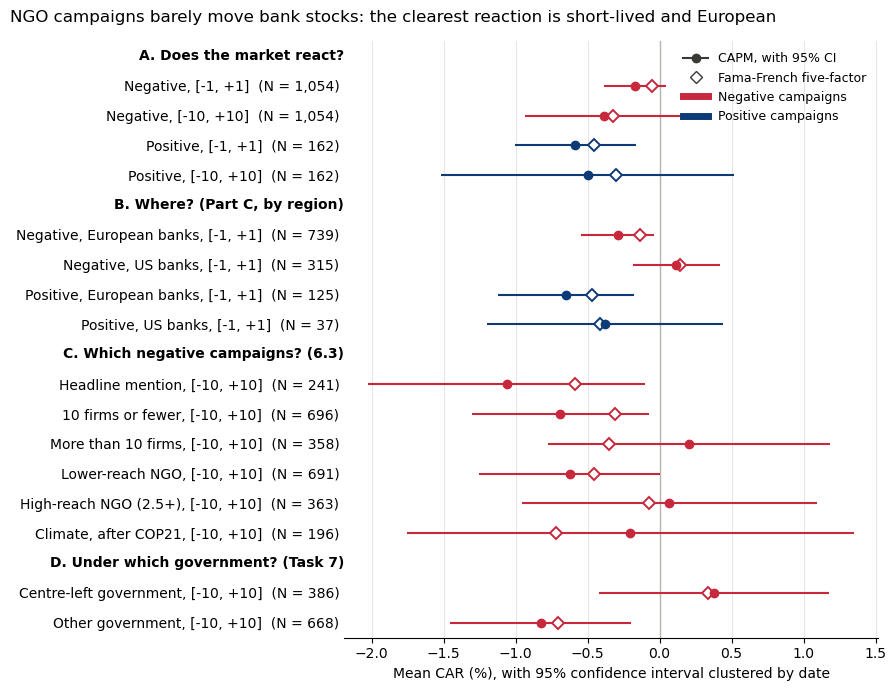

                                            label  mean    ci    ff
0                 Negative, [-1, +1]  (N = 1,054) -0.17  0.21 -0.05
1               Negative, [-10, +10]  (N = 1,054) -0.39  0.55 -0.33
2                   Positive, [-1, +1]  (N = 162) -0.59  0.42 -0.46
3                 Positive, [-10, +10]  (N = 162) -0.50  1.02 -0.30
4   Negative, European banks, [-1, +1]  (N = 739) -0.29  0.26 -0.14
5         Negative, US banks, [-1, +1]  (N = 315)  0.12  0.30  0.15
6   Positive, European banks, [-1, +1]  (N = 125) -0.65  0.47 -0.47
7          Positive, US banks, [-1, +1]  (N = 37) -0.38  0.82 -0.41
8         Headline mention, [-10, +10]  (N = 241) -1.06  0.96 -0.59
9        10 firms or fewer, [-10, +10]  (N = 696) -0.69  0.61 -0.31
10      More than 10 firms, [-10, +10]  (N = 358)  0.20  0.98 -0.35
11         Lower-reach NGO, [-10, +10]  (N = 691) -0.62  0.63 -0.46
12   High-reach NGO (2.5+), [-10, +10]  (N = 363)  0.07  1.03 -0.07
13    Climate, after COP21, [-10, +10]  (N = 196

In [131]:
from matplotlib.lines import Line2D

# Figure 12: one figure for the whole project. Mean CAR with a 95% CI clustered by date (group_ci from Figure 9);
# filled circle = CAPM, open diamond = Fama-French five-factor mean
lo, hi = cars["car_ff_1"].quantile([0.01, 0.99])                     # Fama-French [-1,+1], winsorised like the other windows
cars["car_ff_1_win"] = cars["car_ff_1"].clip(lo, hi)

is_neg, is_pos, is_eu = cars["sign"] == "neg", cars["sign"] == "pos", cars["region"] == "EU"
W1, W10 = ("car_1_win", "car_ff_1_win", "[-1, +1]"), ("car_win", "car_ff_win", "[-10, +10]")

# (block, group, events, window)
SUMMARY = [
    ("A. Does the market react?", "Negative", is_neg, W1),
    ("A. Does the market react?", "Negative", is_neg, W10),
    ("A. Does the market react?", "Positive", is_pos, W1),
    ("A. Does the market react?", "Positive", is_pos, W10),
    ("B. Where? (Part C, by region)", "Negative, European banks", is_neg & is_eu, W1),
    ("B. Where? (Part C, by region)", "Negative, US banks", is_neg & ~is_eu, W1),
    ("B. Where? (Part C, by region)", "Positive, European banks", is_pos & is_eu, W1),
    ("B. Where? (Part C, by region)", "Positive, US banks", is_pos & ~is_eu, W1),
    ("C. Which negative campaigns? (6.3)", "Headline mention", is_neg & (cars["prominence"] == 4), W10),
    ("C. Which negative campaigns? (6.3)", "10 firms or fewer", is_neg & ~cars["mass"], W10),
    ("C. Which negative campaigns? (6.3)", "More than 10 firms", is_neg & cars["mass"], W10),
    ("C. Which negative campaigns? (6.3)", "Lower-reach NGO", is_neg & (cars["ngo_power"] < 2.5), W10),
    ("C. Which negative campaigns? (6.3)", "High-reach NGO (2.5+)", is_neg & (cars["ngo_power"] >= 2.5), W10),
    ("C. Which negative campaigns? (6.3)", "Climate, after COP21", is_neg & cars["climate"] & cars["post"], W10),
    ("D. Under which government? (Task 7)", "Centre-left government", is_neg & (cars["left"] == 1), W10),
    ("D. Under which government? (Task 7)", "Other government", is_neg & (cars["left"] == 0), W10),
]

rows, y, heads = [], 0, []
for block, group, mask, (col, col_ff, w) in SUMMARY:
    if not heads or heads[-1][1] != block:                           # an empty line with the block title
        heads.append((y, block))
        y += 1
    d = cars[mask]
    m, ci, n = group_ci(d, col)
    rows.append({"y": y, "label": f"{group}, {w}  (N = {n:,})", "tone": d["sign"].iloc[0],
                 "mean": m, "ci": ci, "ff": 100 * d[col_ff].mean()})
    y += 1
res = pd.DataFrame(rows)

fig, ax = plt.subplots(figsize=(9, 7))
ax.axvline(0, color="#b7b5ad", lw=1)
for _, r in res.iterrows():
    col = TONE[r["tone"]][1]                                          # red = negative, navy = positive (TONE from Figure 8)
    ax.errorbar(r["mean"], r["y"], xerr=r["ci"], fmt="o", color=col, ms=6, lw=1.5, capsize=0)
    ax.plot(r["ff"], r["y"], marker="D", ms=6, mfc="white", mec=col, mew=1.4, ls="none")
for yh, block in heads:
    ax.text(0, yh, block, transform=ax.get_yaxis_transform(), ha="right", va="center", fontweight="bold")

ax.set_yticks(res["y"], res["label"])
ax.set_ylim(y - 0.5, -0.5)                                           # first block at the top
ax.set_xlabel("Mean CAR (%), with 95% confidence interval clustered by date")
fig.suptitle("NGO campaigns barely move bank stocks: the clearest reaction is short-lived and European", x=0.01, ha="left", fontsize=12)
ax.legend(handles=[Line2D([], [], color="#3a3936", marker="o", lw=1.5, label="CAPM, with 95% CI"),
                   Line2D([], [], color="#3a3936", marker="D", mfc="white", ls="none", label="Fama-French five-factor"),
                   Line2D([], [], color=TONE["neg"][1], lw=5, label=TONE["neg"][0]),
                   Line2D([], [], color=TONE["pos"][1], lw=5, label=TONE["pos"][0])],
          frameon=False, loc="upper right", fontsize=9)
ax.grid(axis="x", color="#e8e6df", lw=0.8)
ax.set_axisbelow(True)
ax.spines[["top", "right", "left"]].set_visible(False)
ax.tick_params(axis="y", length=0)
fig.tight_layout()
plt.show()
print(res[["label", "mean", "ci", "ff"]].round(2).to_string())

**Summary:** Six rows have an interval entirely below zero: positive campaigns on [−1, +1] (−0.59%), negative and positive campaigns against European banks on [−1, +1] (−0.29% and −0.65%), two splits of negative campaigns on [−10, +10], headline mentions (−1.06%) and campaigns naming 10 firms or fewer (−0.69%), and negative campaigns under non-left governments (−0.83%). Every other group, including all negative campaigns together (−0.39%) and every US group, crosses zero. The Fama-French diamonds sit closer to zero in most rows: the European negative effect halves (−0.14%) and the headline effect falls to −0.59%, while the government split barely moves (−0.71% against +0.33%). NGO campaigns therefore move bank stocks little on average: the clearest reactions are short-lived, European, and depend on the political context. Block B uses date clustering to match Task 6, so its intervals are slightly narrower than Figure 7's, which are clustered by month.